# Part (b) — Step 1: MsPacman-v5 Environment and Image Preprocessing Validation

## Objective

Before implementing Modified Rainbow DQN, verify that the Atari environment works and that the **assignment-provided preprocessing function** produces the expected image format. This step performs **no model training**.

We use the official `ALE/MsPacman-v5` environment with **9 discrete actions**, RGB observations of shape `(210, 160, 3)`, and the default v5 settings (frame skip 4, sticky-action probability 0.25). We will **not** add another frame-skipping wrapper.

## Procedure

1. Create and reset `ALE/MsPacman-v5` using seed `42`.
2. Verify the RGB observation shape and the 9-action discrete action space.
3. Apply the exact preprocessing function given in the assignment: crop and downsample, sum RGB channels, remove the specified color, transform to `int8`, and reshape to `(88, 80, 1)`.
4. Save and display a side-by-side preview of the original and processed images.
5. Execute **20 random environment steps only** to confirm the Gymnasium API and create a four-frame state of shape `(4, 88, 80)` for the future CNN.
6. Check the network-input conversion `(state.float() + 128) / 255`, which is necessary because the assignment's preprocessing returns signed `int8` data.

## Installation (run only if packages are missing)

In a separate notebook cell, run `%pip install "gymnasium[atari]" pillow`, then restart the kernel. Modern ALE versions include the Atari ROMs with the package. If the ROM cannot be found, check your installed `ale-py` version and official ALE installation instructions.

## Expected output

- Environment ID: `ALE/MsPacman-v5`
- Action space: `Discrete(9)`
- Original image: `(210, 160, 3)`, `uint8`
- Preprocessed image: `(88, 80, 1)`, `int8`
- Four-frame state: `(4, 88, 80)`, `int8`
- Normalized network input: `(4, 88, 80)`, `float32`, values in `[0, 1]`
- An image file at `results_mspacman_rainbow/step1_preprocessing_preview.png`

This short interaction test only confirms environment/data compatibility; it does not assess learning, game performance, or the correctness of Rainbow optimization.

**Official reference:** https://ale.farama.org/environments/ms_pacman/


ENVIRONMENT INFORMATION
Environment: ALE/MsPacman-v5
Action space: Discrete(9)
Observation shape: (210, 160, 3)
Observation dtype: uint8
Action meanings: ['NOOP', 'UP', 'RIGHT', 'LEFT', 'DOWN', 'UPRIGHT', 'UPLEFT', 'DOWNRIGHT', 'DOWNLEFT']

PREPROCESSING CHECK
Processed shape: (88, 80, 1)
Processed dtype: int8
Processed value range: -128 to 27

Saved preview: results_mspacman_rainbow\step1_preprocessing_preview.png


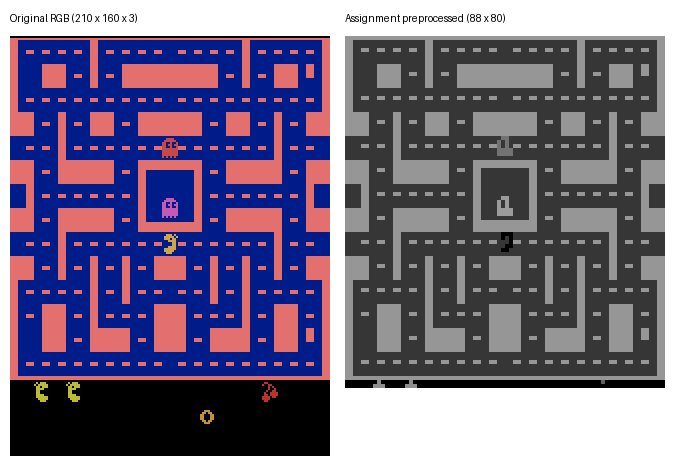


SHORT INTERACTION CHECK
Random actions executed: 20
Raw cumulative reward (diagnostic only): 0.0
Environment resets during test: 0
Four-frame state shape: (4, 88, 80)
Four-frame state dtype: int8
Normalized input dtype: float32
Normalized input range: 0.0000 to 0.6078

STEP 1 PASSED: Environment and preprocessing are compatible.
No learning or gradient updates were performed.


In [1]:
# ============================================================
# Part (b) — Step 1: Environment and preprocessing validation
# No DQN/Rainbow model, no training, no Matplotlib display.
# ============================================================

from pathlib import Path
from collections import deque

import numpy as np
import gymnasium as gym
import ale_py
from PIL import Image as PILImage, ImageDraw
from IPython.display import display, Image as NotebookImage

# Register Atari environments explicitly (Gymnasium 1.x).
gym.register_envs(ale_py)

SEED = 42
ENV_ID = "ALE/MsPacman-v5"
OUT_DIR = Path("results_mspacman_rainbow")
OUT_DIR.mkdir(parents=True, exist_ok=True)
PREVIEW_PATH = OUT_DIR / "step1_preprocessing_preview.png"

# EXACT preprocessing function provided in the assignment.
mspacman_color = 210 + 164 + 74

def preprocess_observation(obs):
    img = obs[1:176:2, ::2]  # crop and downsize
    img = img.sum(axis=2)  # to greyscale
    img[img == mspacman_color] = 0  # improve contrast
    img = (img // 3 - 128).astype(np.int8)  # normalize from -128 to 127
    return img.reshape(88, 80, 1)

# ------------------------------------------------------------
# 1. Environment initialization and checks
# ------------------------------------------------------------

env = gym.make(ENV_ID, obs_type="rgb")

try:
    observation, info = env.reset(seed=SEED)
    env.action_space.seed(SEED)

    print("ENVIRONMENT INFORMATION")
    print("Environment:", env.spec.id)
    print("Action space:", env.action_space)
    print("Observation shape:", observation.shape)
    print("Observation dtype:", observation.dtype)

    assert env.spec.id == ENV_ID
    assert isinstance(env.action_space, gym.spaces.Discrete)
    assert env.action_space.n == 9, "The assignment requires exactly 9 actions."
    assert observation.shape == (210, 160, 3)
    assert observation.dtype == np.uint8

    # Optional action names if this ALE build exposes them.
    if hasattr(env.unwrapped, "get_action_meanings"):
        print("Action meanings:", env.unwrapped.get_action_meanings())

    # --------------------------------------------------------
    # 2. Assignment preprocessing — shape and range checks
    # --------------------------------------------------------

    processed = preprocess_observation(observation)
    assert processed.shape == (88, 80, 1)
    assert processed.dtype == np.int8

    print("\nPREPROCESSING CHECK")
    print("Processed shape:", processed.shape)
    print("Processed dtype:", processed.dtype)
    print("Processed value range:", int(processed.min()), "to", int(processed.max()))

    # --------------------------------------------------------
    # 3. Save a side-by-side preview using PIL (not plt.show)
    # --------------------------------------------------------

    # Undo the -128 offset for visualization only; preserve
    # the original int8 result for the eventual Rainbow input.
    preview_gray = (processed[:, :, 0].astype(np.int16) + 128).astype(np.uint8)
    original_view = PILImage.fromarray(observation)
    processed_view = PILImage.fromarray(preview_gray).convert("RGB")

    nearest = PILImage.Resampling.NEAREST
    original_view = original_view.resize((320, 420), resample=nearest)
    processed_view = processed_view.resize((320, 352), resample=nearest)

    canvas = PILImage.new("RGB", (675, 470), color="white")
    draw = ImageDraw.Draw(canvas)
    draw.text((10, 12), "Original RGB (210 x 160 x 3)", fill="black")
    draw.text((345, 12), "Assignment preprocessed (88 x 80)", fill="black")
    canvas.paste(original_view, (10, 36))
    canvas.paste(processed_view, (345, 36))
    canvas.save(PREVIEW_PATH)

    print("\nSaved preview:", PREVIEW_PATH)
    display(NotebookImage(filename=str(PREVIEW_PATH), width=675))

    # --------------------------------------------------------
    # 4. Check the Gymnasium step interface and 4-frame stack
    # --------------------------------------------------------

    frames = deque([processed[:, :, 0].copy() for _ in range(4)], maxlen=4)
    rng = np.random.default_rng(SEED)
    total_reward = 0.0
    total_resets = 0

    for step_idx in range(20):
        action = int(rng.integers(0, env.action_space.n))
        next_observation, reward, terminated, truncated, info = env.step(action)
        total_reward += float(reward)

        next_processed = preprocess_observation(next_observation)
        frames.append(next_processed[:, :, 0].copy())

        if terminated or truncated:
            # Maintain a clean frame stack for a newly reset episode.
            next_observation, info = env.reset()
            next_processed = preprocess_observation(next_observation)
            frames = deque([next_processed[:, :, 0].copy() for _ in range(4)], maxlen=4)
            total_resets += 1

    stacked_state = np.stack(frames, axis=0)
    assert stacked_state.shape == (4, 88, 80)
    assert stacked_state.dtype == np.int8

    normalized_state = (stacked_state.astype(np.float32) + 128.0) / 255.0
    assert normalized_state.dtype == np.float32
    assert np.all((normalized_state >= 0.0) & (normalized_state <= 1.0))

    print("\nSHORT INTERACTION CHECK")
    print("Random actions executed:", 20)
    print("Raw cumulative reward (diagnostic only):", total_reward)
    print("Environment resets during test:", total_resets)
    print("Four-frame state shape:", stacked_state.shape)
    print("Four-frame state dtype:", stacked_state.dtype)
    print("Normalized input dtype:", normalized_state.dtype)
    print("Normalized input range:", f"{normalized_state.min():.4f}", "to", f"{normalized_state.max():.4f}")

    print("\nSTEP 1 PASSED: Environment and preprocessing are compatible.")
    print("No learning or gradient updates were performed.")

finally:
    env.close()



# Part (b) — Step 2: Modified Rainbow DQN Network Validation

## Objective

Build and validate the **convolutional, dueling, noisy, distributional Q-network** used by our modified Rainbow DQN for `ALE/MsPacman-v5`.

This step verifies the network and its outputs **without starting reinforcement learning training**.

### Assignment Constraints

- Environment: `ALE/MsPacman-v5` (verified in Step 1).
- Teacher-specified preprocessing: each frame is `int8` with shape `(88, 80, 1)`.
- Frame stacking: four frames in channel-first form `(4, 88, 80)`.
- Number of discrete actions: **9**.
- Discount factor: **$\gamma=0.99$**.

### Model Architecture

We use a modified Rainbow DQN architecture consisting of:

1. **Convolutional Neural Network (CNN):** Extracts spatial features from four stacked game frames.
2. **Dueling Network:** Separates state-value and action-advantage estimation.
3. **Noisy Networks:** Introduces learnable parameter noise for exploration.
4. **Categorical Distributional DQN (C51):** Predicts a probability distribution over returns rather than a single scalar Q-value.

The CNN transforms the input from `(4, 88, 80)` to `(64, 7, 6)`, producing 2,688 flattened features.

A fully connected layer maps these features to 512 hidden units.

The dueling network produces value and advantage distributions for 9 actions and 51 distributional atoms.

The distributional support is:

$$
z_j \in [-10,10],
\qquad N_{\mathrm{atoms}}=51.
$$

The expected action-value is computed as:

$$
Q(s,a)=\sum_{j=1}^{51}z_jp_j(s,a).
$$

The support range is designed for clipped training rewards and does not represent the range of original MsPacman game scores.

Final evaluation will use the environment's original, unclipped rewards.

### Validation Tests

We conduct the following checks:

1. Verify CNN input, intermediate feature, and output dimensions.
2. Confirm that all C51 probability distributions are nonnegative and sum to one.
3. Verify that the network produces 9 expected Q-values for each observation.
4. Confirm deterministic predictions in evaluation mode.
5. Confirm that resetting NoisyNet noise changes predictions in training mode.
6. Verify finite gradients through a diagnostic backward pass.

No optimizer updates, environment rollouts, or reinforcement learning training are performed.

### Expected Outputs

- Input shape: `(2, 4, 88, 80)`
- CNN output: `(64, 7, 6)`
- Flattened dimension: `2688`
- C51 probability tensor: `(2, 9, 51)`
- Expected Q-value tensor: `(2, 9)`

The results will be saved to:

`results_mspacman_rainbow/step2_rainbow_network_validation.json`

### Reference

The implementation follows the architecture of CleanRL's open-source Rainbow Atari implementation, adapted to the assignment's image dimensions, preprocessing format, and action space.

This step validates only the neural network. Prioritized Experience Replay, N-step Returns, Double Q-Learning targets, and C51 Bellman projection will be implemented and tested in subsequent steps.


In [2]:

# ============================================================
# Part (b) — Step 2: Modified Rainbow DQN Network Validation
#
# CNN + Dueling Network + NoisyNet + C51
#
# No training or environment interaction.
# ============================================================

import json
import math
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)

# Use CPU for architecture validation.
DEVICE = torch.device("cpu")

RESULTS_DIR = Path("results_mspacman_rainbow")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

N_ACTIONS = 9
N_ATOMS = 51

V_MIN = -10.0
V_MAX = 10.0

GAMMA = 0.99

INPUT_SHAPE = (4, 88, 80)


# ------------------------------------------------------------
# 2. Factorized Gaussian NoisyLinear
# ------------------------------------------------------------

class NoisyLinear(nn.Module):

    def __init__(
        self,
        in_features,
        out_features,
        std_init=0.5
    ):
        super().__init__()

        self.in_features = in_features
        self.out_features = out_features

        self.weight_mu = nn.Parameter(
            torch.empty(out_features, in_features)
        )

        self.weight_sigma = nn.Parameter(
            torch.empty(out_features, in_features)
        )

        self.bias_mu = nn.Parameter(
            torch.empty(out_features)
        )

        self.bias_sigma = nn.Parameter(
            torch.empty(out_features)
        )

        self.register_buffer(
            "weight_epsilon",
            torch.zeros(out_features, in_features)
        )

        self.register_buffer(
            "bias_epsilon",
            torch.zeros(out_features)
        )

        bound = 1.0 / math.sqrt(in_features)

        nn.init.uniform_(
            self.weight_mu, -bound, bound
        )

        nn.init.uniform_(
            self.bias_mu, -bound, bound
        )

        nn.init.constant_(
            self.weight_sigma,
            std_init / math.sqrt(in_features)
        )

        nn.init.constant_(
            self.bias_sigma,
            std_init / math.sqrt(out_features)
        )

        self.reset_noise()

    @staticmethod
    def _scaled_noise(size, device):

        x = torch.randn(size, device=device)

        return x.sign() * x.abs().sqrt()

    @torch.no_grad()
    def reset_noise(self):

        eps_in = self._scaled_noise(
            self.in_features,
            self.weight_mu.device
        )

        eps_out = self._scaled_noise(
            self.out_features,
            self.weight_mu.device
        )

        self.weight_epsilon.copy_(
            torch.outer(eps_out, eps_in)
        )

        self.bias_epsilon.copy_(eps_out)

    def forward(self, x):

        if self.training:

            weight = (
                self.weight_mu
                + self.weight_sigma
                * self.weight_epsilon
            )

            bias = (
                self.bias_mu
                + self.bias_sigma
                * self.bias_epsilon
            )

        else:

            weight = self.weight_mu
            bias = self.bias_mu

        return F.linear(x, weight, bias)


# ------------------------------------------------------------
# 3. Modified Rainbow Network
# ------------------------------------------------------------

class ModifiedRainbowNetwork(nn.Module):

    def __init__(
        self,
        n_actions=9,
        n_atoms=51,
        v_min=-10.0,
        v_max=10.0
    ):
        super().__init__()

        self.n_actions = n_actions
        self.n_atoms = n_atoms

        self.v_min = v_min
        self.v_max = v_max

        self.register_buffer(
            "support",
            torch.linspace(
                v_min,
                v_max,
                n_atoms
            )
        )

        # CNN Feature Extractor

        self.conv = nn.Sequential(

            nn.Conv2d(
                4, 32,
                kernel_size=8,
                stride=4
            ),
            nn.ReLU(),

            nn.Conv2d(
                32, 64,
                kernel_size=4,
                stride=2
            ),
            nn.ReLU(),

            nn.Conv2d(
                64, 64,
                kernel_size=3,
                stride=1
            ),
            nn.ReLU()
        )

        # Infer feature dimensions automatically.

        with torch.no_grad():

            dummy = torch.zeros(
                1, *INPUT_SHAPE
            )

            feature_shape = self.conv(dummy).shape

        self.feature_shape = tuple(
            feature_shape[1:]
        )

        self.flattened_dim = int(
            math.prod(self.feature_shape)
        )

        self.fc = nn.Sequential(

            nn.Linear(
                self.flattened_dim,
                512
            ),

            nn.ReLU()
        )

        # Dueling Value Stream

        self.value = nn.Sequential(

            NoisyLinear(512, 512),

            nn.ReLU(),

            NoisyLinear(
                512,
                n_atoms
            )
        )

        # Dueling Advantage Stream

        self.advantage = nn.Sequential(

            NoisyLinear(512, 512),

            nn.ReLU(),

            NoisyLinear(
                512,
                n_actions * n_atoms
            )
        )

    def forward(self, stacked_int8_frames):

        # Teacher preprocessing produces int8 values
        # in the interval [-128, 127].
        #
        # Normalize to [0, 1] before the CNN.

        x = (
            stacked_int8_frames.float()
            + 128.0
        ) / 255.0

        features = self.conv(x)

        features = features.flatten(
            start_dim=1
        )

        features = self.fc(features)

        # State-value distribution

        value = self.value(features).view(
            -1,
            1,
            self.n_atoms
        )

        # Action-advantage distributions

        advantage = self.advantage(features).view(
            -1,
            self.n_actions,
            self.n_atoms
        )

        # Dueling combination

        logits = (
            value
            + advantage
            - advantage.mean(
                dim=1,
                keepdim=True
            )
        )

        # C51 categorical probability distributions

        probabilities = F.softmax(
            logits,
            dim=-1
        )

        return probabilities

    def q_values(self, obs):

        probabilities = self(obs)

        support = self.support.view(
            1, 1, -1
        )

        expected_q = (
            probabilities * support
        ).sum(dim=-1)

        return expected_q

    def reset_noise(self):

        for module in self.modules():

            if isinstance(
                module,
                NoisyLinear
            ):

                module.reset_noise()


# ------------------------------------------------------------
# 4. Initialize Model
# ------------------------------------------------------------

model = ModifiedRainbowNetwork(

    n_actions=N_ACTIONS,

    n_atoms=N_ATOMS,

    v_min=V_MIN,

    v_max=V_MAX

).to(DEVICE)

# Synthetic observations follow exactly the shape
# and dtype of the output from Step 1.
#
# No Atari rollout is needed for this test.

rng = np.random.default_rng(SEED)

obs_np = rng.integers(

    -128,
    128,

    (2, *INPUT_SHAPE),

    dtype=np.int16

).astype(np.int8)

obs = torch.from_numpy(
    obs_np
).to(DEVICE)


# ------------------------------------------------------------
# 5. Test A: Output Shapes and C51 Probabilities
# ------------------------------------------------------------

model.eval()

with torch.inference_mode():

    probabilities = model(obs)

    q_values = model.q_values(obs)

    actions = q_values.argmax(
        dim=1
    )

    probabilities_again = model(obs)


assert model.feature_shape == (64, 7, 6)

assert model.flattened_dim == 2688

assert probabilities.shape == (2, 9, 51)

assert q_values.shape == (2, 9)

assert torch.isfinite(
    probabilities
).all()

assert torch.isfinite(
    q_values
).all()

assert (probabilities >= 0).all()

assert torch.allclose(

    probabilities.sum(dim=-1),

    torch.ones((2, 9)),

    atol=1e-6
)

assert (
    (q_values >= V_MIN - 1e-5)
    &
    (q_values <= V_MAX + 1e-5)
).all()

assert torch.equal(
    probabilities,
    probabilities_again
)

assert torch.all(
    (actions >= 0)
    &
    (actions < N_ACTIONS)
)

print("TEST A: C51 NETWORK OUTPUT")

print("Input shape:", tuple(obs.shape))

print("CNN feature shape:", model.feature_shape)

print("Flattened dimension:", model.flattened_dim)

print(
    "C51 probability shape:",
    tuple(probabilities.shape)
)

print(
    "Expected Q-value shape:",
    tuple(q_values.shape)
)

print("Greedy actions:", actions.tolist())

print("C51 normalization: PASS")

print("Deterministic evaluation: PASS")


# ------------------------------------------------------------
# 6. Test B: NoisyNet Exploration
# ------------------------------------------------------------

model.train()

with torch.no_grad():

    model.reset_noise()

    noisy_q1 = model.q_values(obs)

    model.reset_noise()

    noisy_q2 = model.q_values(obs)

noisy_difference = float(

    (
        noisy_q1 - noisy_q2
    ).abs().max().item()
)

assert noisy_difference > 0

print("\nTEST B: NOISY NETWORK")

print(
    "Maximum Q-value difference:",
    f"{noisy_difference:.6f}"
)

print("NoisyNet exploration: PASS")


# ------------------------------------------------------------
# 7. Test C: Gradient Validation
# ------------------------------------------------------------

model.zero_grad(
    set_to_none=True
)

model.reset_noise()

probabilities_train = model(obs)

selected_actions = torch.tensor(

    [0, 1],

    dtype=torch.long
)

selected_probabilities = probabilities_train[

    torch.arange(2),

    selected_actions

]

# Diagnostic loss only.
# This is not the C51 Bellman training loss.

toy_loss = -torch.log(

    selected_probabilities[
        :, N_ATOMS // 2
    ].clamp_min(1e-8)

).mean()

toy_loss.backward()

assert torch.isfinite(toy_loss)

assert all(

    p.grad is not None
    and torch.isfinite(p.grad).all()

    for p in model.parameters()

    if p.requires_grad

)

model.zero_grad(
    set_to_none=True
)

model.eval()

print("\nTEST C: BACKPROPAGATION")

print(
    "Diagnostic loss:",
    f"{toy_loss.item():.6f}"
)

print("All parameter gradients finite: PASS")


# ------------------------------------------------------------
# 8. Parameter Count
# ------------------------------------------------------------

n_parameters = sum(

    p.numel()

    for p in model.parameters()

)

print("\nMODEL INFORMATION")

print(
    "Trainable parameters:",
    f"{n_parameters:,}"
)


# ------------------------------------------------------------
# 9. Save Validation Summary
# ------------------------------------------------------------

summary = {

    "environment": "ALE/MsPacman-v5",

    "teacher_preprocessed_frame": [88, 80, 1],

    "teacher_preprocessed_dtype": "int8",

    "stacked_input_shape": list(INPUT_SHAPE),

    "conv_output_shape": list(model.feature_shape),

    "flattened_features": model.flattened_dim,

    "actions": N_ACTIONS,

    "atoms": N_ATOMS,

    "v_min": V_MIN,

    "v_max": V_MAX,

    "gamma_for_future_training": GAMMA,

    "parameter_count": n_parameters,

    "eval_deterministic": True,

    "train_noise_changes_q": True,

    "all_distribution_rows_normalized": True,

    "all_gradients_finite": True,

    "optimizer_steps": 0

}

summary_path = (
    RESULTS_DIR
    / "step2_rainbow_network_validation.json"
)

with open(
    summary_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=4
    )


# ------------------------------------------------------------
# 10. Final Summary
# ------------------------------------------------------------

print("\n" + "=" * 58)

print("STEP 2: MODIFIED RAINBOW NETWORK VALIDATION")

print("=" * 58)

print("Device:", DEVICE)

print("Parameters:", f"{n_parameters:,}")

print("Input shape:", tuple(obs.shape))

print("C51 shape:", tuple(probabilities.shape))

print("Q-values shape:", tuple(q_values.shape))

print("C51 probability normalization: PASS")

print("Deterministic evaluation mode: PASS")

print("NoisyNet reset changes Q-values: PASS")

print("Finite backward gradients: PASS")

print("Saved summary:", summary_path)

print(
    "\nSTEP 2 PASSED: "
    "Network is ready for Rainbow training components."
)

print(
    "No optimizer steps, checkpoint training, "
    "or environment rollouts performed."
)


TEST A: C51 NETWORK OUTPUT
Input shape: (2, 4, 88, 80)
CNN feature shape: (64, 7, 6)
Flattened dimension: 2688
C51 probability shape: (2, 9, 51)
Expected Q-value shape: (2, 9)
Greedy actions: [6, 6]
C51 normalization: PASS
Deterministic evaluation: PASS

TEST B: NOISY NETWORK
Maximum Q-value difference: 0.099626
NoisyNet exploration: PASS

TEST C: BACKPROPAGATION
Diagnostic loss: 3.853241
All parameter gradients finite: PASS

MODEL INFORMATION
Trainable parameters: 3,028,636

STEP 2: MODIFIED RAINBOW NETWORK VALIDATION
Device: cpu
Parameters: 3,028,636
Input shape: (2, 4, 88, 80)
C51 shape: (2, 9, 51)
Q-values shape: (2, 9)
C51 probability normalization: PASS
Deterministic evaluation mode: PASS
NoisyNet reset changes Q-values: PASS
Finite backward gradients: PASS
Saved summary: results_mspacman_rainbow\step2_rainbow_network_validation.json

STEP 2 PASSED: Network is ready for Rainbow training components.
No optimizer steps, checkpoint training, or environment rollouts performed.



# Part (b) - Step 3: Rainbow Learning Components

## 1. Objective

Implement and validate the core learning components of our Modified Rainbow DQN for the MsPacman-v5 environment.

The neural network was constructed and validated in Step 2. This step focuses on the experience replay and learning target calculations.

The main components are:

1. Prioritized Experience Replay (PER)
2. Memory-efficient frame storage
3. N-step Returns
4. Termination and truncation handling
5. Double Q-Learning
6. C51 Distributional Bellman Projection
7. Importance-sampling weighted loss

No reinforcement learning training will be performed in this step.

## 2. Prioritized Experience Replay

Standard experience replay samples transitions uniformly.

Prioritized Experience Replay assigns larger sampling probabilities to transitions with higher priorities.

The sampling probability is:

`P(i) = priority_i**alpha / sum(priority_j**alpha)`

where:

- `priority_i` is the priority of transition i.
- `alpha = 0.6` controls prioritization strength.
- `beta` controls the importance-sampling correction.

Importance-sampling weights reduce the sampling bias introduced by prioritized replay.

The weights are normalized within each sampled batch.

## 3. Memory-Efficient Frame Storage

Each processed MsPacman frame has:

- Shape: (88, 80)
- Data type: int8
- Storage: 7,040 bytes per frame

Instead of saving complete four-frame states for every transition, the replay buffer stores individual frames.

When a transition is sampled, the corresponding four-frame state is reconstructed.

This reduces memory consumption and avoids repeatedly storing nearly identical frames.

The implementation must also prevent frames from different episodes from being combined.

## 4. N-step Returns

We use the following parameters:

- Discount factor: gamma = 0.99
- Number of steps: n = 3
- Training reward: sign-clipped game reward

The three-step discounted reward is:

`R_3 = r_t + gamma*r_(t+1) + gamma**2*r_(t+2)`

For a non-terminal three-step transition, the target also includes a future-value term discounted by `gamma**3`.

If an episode ends before three steps, the algorithm uses the available rewards and the appropriate discount power.

The replay buffer must not combine rewards from different episodes.

Original game scores will be recorded separately and will not be clipped for final evaluation.

## 5. Termination and Truncation

Gymnasium distinguishes two types of episode endings.

### True Termination

A true termination means that the environment reaches a terminal state.

The Bellman target must not include future rewards.

### Time-Limit Truncation

Truncation means that an episode ends because of an external limit.

In this case, the final state may still have future value.

Therefore, the algorithm can bootstrap from the final observation.

The implementation uses the `terminated` flag to determine whether bootstrapping is disabled.

Both termination and truncation prevent N-step transitions from crossing episode boundaries.

## 6. Double Q-Learning

Double Q-Learning separates action selection and action evaluation.

The online network selects the next action with the highest expected Q-value.

The target network evaluates the selected action.

This separation can reduce maximization-related Q-value overestimation.

The online and target networks use the same architecture but maintain separate parameters.

## 7. C51 Distributional Bellman Projection

Unlike standard DQN, C51 predicts a probability distribution over possible returns.

Our configuration uses:

- Number of actions: 9
- Number of atoms: 51
- Minimum support value: -10
- Maximum support value: 10

The C51 target distribution is obtained by:

1. Selecting the next action using the online network.
2. Obtaining its distribution from the target network.
3. Applying the N-step Bellman transformation.
4. Clipping transformed support locations to the fixed support.
5. Projecting probability mass onto neighboring atoms.

The projected probabilities must be nonnegative and sum to one.

## 8. Distributional Training Loss

The network is trained using categorical cross-entropy between the predicted distribution and the projected target distribution.

Prioritized Experience Replay introduces importance-sampling weights.

The resulting loss is a weighted average of individual distributional losses.

The individual losses may also be used to update replay priorities.

## 9. Validation Tests

We perform six groups of tests.

### Test A: N-step Returns

Verify the calculated discounted rewards against manually computed expected values.

### Test B: Episode Boundaries

Verify that frame stacking does not mix observations from different episodes.

Check that true termination and truncation are handled differently.

### Test C: Prioritized Replay

Verify prioritized sampling, observation shapes, action ranges, and importance-sampling weights.

### Test D: C51 Projection

Verify that the projected probability distributions are valid and preserve total probability mass.

### Test E: Double C51 Targets

Verify the target distribution shape, finite loss values, and gradient propagation.

### Test F: Circular Replay Overwriting

Verify that the replay buffer remains consistent when older frames are overwritten.

## 10. Expected Output

All validation tests should report PASS.

The summary will be saved to:

`results_mspacman_rainbow/step3_rainbow_components_validation.json`

This step uses synthetic transitions and an untrained Rainbow network.

No optimizer updates or environment training are performed.

## 11. Next Step

After all tests pass, proceed to Step 4.

Step 4 will integrate the Rainbow network with the real MsPacman environment and perform a short training experiment to verify the complete learning pipeline.


In [3]:

# ============================================================
# Part (b) — Step 3: Rainbow Learning Components
#
# Prioritized Experience Replay
# Memory-efficient single-frame storage
# 3-step returns
# Double Q-Learning
# C51 Bellman projection
#
# No optimizer updates or environment training.
# ============================================================

import json
import copy
from pathlib import Path
from collections import deque

import numpy as np
import torch


SEED = 42

GAMMA_RAINBOW = 0.99
N_STEP_RAINBOW = 3

RESULTS_DIR = Path("results_mspacman_rainbow")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

assert "ModifiedRainbowNetwork" in globals(), (
    "Run Step 2 before executing Step 3."
)


# ============================================================
# 1. Sum Tree for Prioritized Sampling
# ============================================================

class SumTree:

    def __init__(self, capacity):

        self.capacity = int(capacity)

        self.leaf_count = (
            1 << (self.capacity - 1).bit_length()
        )

        self.tree = np.zeros(
            2 * self.leaf_count,
            dtype=np.float64
        )

        self.active_count = 0

    def get(self, index):

        return float(
            self.tree[
                self.leaf_count + int(index)
            ]
        )

    def set(self, index, value):

        index = int(index)
        value = float(value)

        leaf = self.leaf_count + index
        previous = self.tree[leaf]

        if previous == 0 and value > 0:
            self.active_count += 1

        elif previous > 0 and value == 0:
            self.active_count -= 1

        delta = value - previous

        while leaf >= 1:

            self.tree[leaf] += delta
            leaf //= 2

    @property
    def total(self):

        return float(self.tree[1])

    def find(self, mass):

        if self.total <= 0:
            raise RuntimeError(
                "No sampleable transitions."
            )

        mass = min(
            max(float(mass), 0.0),
            np.nextafter(self.total, 0)
        )

        node = 1

        while node < self.leaf_count:

            left = 2 * node

            if mass < self.tree[left]:
                node = left

            else:
                mass -= self.tree[left]
                node = left + 1

        index = node - self.leaf_count

        assert index < self.capacity
        assert self.get(index) > 0

        return index


# ============================================================
# 2. Frame-Based Prioritized Replay Buffer
# ============================================================

class FramePrioritizedReplay:

    def __init__(
        self,
        capacity=100000,
        frame_shape=(88, 80),
        stack_size=4,
        n_step=3,
        gamma=0.99,
        alpha=0.6,
        seed=42
    ):

        self.capacity = int(capacity)
        self.frame_shape = tuple(frame_shape)

        self.stack_size = int(stack_size)
        self.n_step = int(n_step)

        self.gamma = float(gamma)
        self.alpha = float(alpha)

        assert (
            self.capacity
            > self.stack_size + self.n_step + 2
        )

        # Store one processed frame per observation.
        self.frames = np.empty(
            (self.capacity, *self.frame_shape),
            dtype=np.int8
        )

        self.frame_ids = np.full(
            self.capacity, -1, dtype=np.int64
        )

        self.episode_ids = np.full(
            self.capacity, -1, dtype=np.int64
        )

        self.actions = np.zeros(
            self.capacity, dtype=np.int64
        )

        self.rewards = np.zeros(
            self.capacity, dtype=np.float32
        )

        self.n_steps = np.zeros(
            self.capacity, dtype=np.int16
        )

        self.terminated = np.zeros(
            self.capacity, dtype=np.bool_
        )

        self.truncated = np.zeros(
            self.capacity, dtype=np.bool_
        )

        self.next_ids = np.full(
            self.capacity, -1, dtype=np.int64
        )

        self.tree = SumTree(self.capacity)

        self.max_priority = 1.0
        self.rng = np.random.default_rng(seed)

        self.next_frame_id = 0
        self.episode_number = -1

        self.current_frame_id = None
        self.pending = deque()

    def _prepare_frame(self, frame):

        frame = np.asarray(frame)

        if frame.shape == (
            *self.frame_shape, 1
        ):
            frame = frame[..., 0]

        if (
            frame.shape != self.frame_shape
            or frame.dtype != np.int8
        ):
            raise ValueError(
                "Expected one int8 frame "
                "with shape (88,80) or (88,80,1)."
            )

        return frame

    def _add_frame(self, frame):

        frame = self._prepare_frame(frame)

        frame_id = self.next_frame_id
        slot = frame_id % self.capacity

        old_id = int(
            self.frame_ids[slot]
        )

        if old_id >= 0:

            # Invalidate transitions depending
            # on overwritten frame history.
            for dependent_id in range(
                old_id,
                old_id + self.stack_size
            ):

                dependent_slot = (
                    dependent_id % self.capacity
                )

                if (
                    self.frame_ids[dependent_slot]
                    == dependent_id
                ):
                    self.tree.set(
                        dependent_slot, 0
                    )

        self.tree.set(slot, 0)

        self.frames[slot] = frame
        self.frame_ids[slot] = frame_id

        self.episode_ids[slot] = (
            self.episode_number
        )

        self.next_frame_id += 1

        return frame_id

    def begin_episode(self, initial_frame):

        if (
            self.current_frame_id is not None
            or self.pending
        ):
            raise RuntimeError(
                "Previous episode has not ended."
            )

        self.episode_number += 1

        self.current_frame_id = (
            self._add_frame(initial_frame)
        )

    def append_step(
        self,
        action,
        reward,
        next_frame,
        terminated=False,
        truncated=False
    ):

        if self.current_frame_id is None:
            raise RuntimeError(
                "Call begin_episode() first."
            )

        if not 0 <= int(action) < 9:
            raise ValueError(
                "Action must be between 0 and 8."
            )

        terminated = bool(terminated)
        truncated = bool(truncated)

        if terminated and truncated:
            raise ValueError(
                "Both boundary flags are True. "
                "Resolve the effective termination "
                "semantics before storing."
            )

        successor_id = self._add_frame(
            next_frame
        )

        # Clip reward for Rainbow learning.
        # Keep raw rewards separately in
        # the future training logger.
        clipped_reward = float(
            np.sign(reward)
        )

        self.pending.append((
            self.current_frame_id,
            int(action),
            clipped_reward,
            successor_id,
            terminated,
            truncated
        ))

        if len(self.pending) >= self.n_step:

            self._emit_first(self.n_step)
            self.pending.popleft()

        if terminated or truncated:

            # Flush incomplete n-step transitions.
            while self.pending:

                self._emit_first(
                    len(self.pending)
                )

                self.pending.popleft()

            self.current_frame_id = None

        else:

            self.current_frame_id = (
                successor_id
            )

    def _emit_first(self, k):

        items = list(self.pending)[:k]

        first_id = items[0][0]
        first_action = items[0][1]

        final = items[-1]

        discounted_reward = sum(
            (self.gamma ** j) * item[2]
            for j, item in enumerate(items)
        )

        slot = first_id % self.capacity

        if self.frame_ids[slot] != first_id:
            raise RuntimeError(
                "Replay capacity is too small."
            )

        self.actions[slot] = first_action

        self.rewards[slot] = (
            discounted_reward
        )

        self.n_steps[slot] = k

        self.next_ids[slot] = final[3]

        self.terminated[slot] = final[4]
        self.truncated[slot] = final[5]

        self.tree.set(
            slot,
            self.max_priority ** self.alpha
        )

    def get_stack(self, frame_id):

        frame_id = int(frame_id)
        slot = frame_id % self.capacity

        if self.frame_ids[slot] != frame_id:
            raise RuntimeError(
                "Requested frame was overwritten."
            )

        episode = self.episode_ids[slot]

        frames = []

        for candidate in range(
            frame_id - self.stack_size + 1,
            frame_id + 1
        ):

            if candidate < 0:
                frames.append(None)
                continue

            candidate_slot = (
                candidate % self.capacity
            )

            valid = (
                self.frame_ids[candidate_slot]
                == candidate
                and
                self.episode_ids[candidate_slot]
                == episode
            )

            if valid:

                frames.append(
                    self.frames[candidate_slot]
                )

            else:

                frames.append(None)

        first_valid = next(
            f for f in frames
            if f is not None
        )

        return np.stack(
            [
                first_valid if f is None else f
                for f in frames
            ],
            axis=0
        )

    def sample(self, batch_size=32, beta=0.4):

        if self.tree.active_count == 0:
            raise RuntimeError(
                "Replay buffer is empty."
            )

        batch_size = int(batch_size)

        segment = (
            self.tree.total / batch_size
        )

        indices = np.array([
            self.tree.find(
                self.rng.uniform(
                    j * segment,
                    (j + 1) * segment
                )
            )
            for j in range(batch_size)
        ], dtype=np.int64)

        probabilities = np.array([
            self.tree.get(i)
            for i in indices
        ]) / self.tree.total

        weights = (
            self.tree.active_count
            * probabilities
        ) ** (-float(beta))

        weights = weights / weights.max()

        states = np.stack([
            self.get_stack(
                self.frame_ids[i]
            )
            for i in indices
        ])

        next_states = np.stack([
            self.get_stack(
                self.next_ids[i]
            )
            for i in indices
        ])

        return {
            "indices": indices,
            "states": states,
            "next_states": next_states,
            "actions": self.actions[
                indices
            ].copy(),
            "rewards": self.rewards[
                indices
            ].copy(),
            "n_steps": self.n_steps[
                indices
            ].copy(),
            "terminated": self.terminated[
                indices
            ].copy(),
            "truncated": self.truncated[
                indices
            ].copy(),
            "weights": weights.astype(
                np.float32
            )
        }

    def update_priorities(
        self, indices, errors, eps=1e-6
    ):

        for index, error in zip(
            indices, errors
        ):

            priority = (
                abs(float(error)) + eps
            )

            self.max_priority = max(
                self.max_priority,
                priority
            )

            self.tree.set(
                int(index),
                priority ** self.alpha
            )


# ============================================================
# 3. C51 Distributional Bellman Projection
# ============================================================

@torch.no_grad()
def c51_projection(
    next_distribution,
    rewards,
    terminated,
    n_steps,
    support,
    gamma=0.99
):

    batch_size, n_atoms = (
        next_distribution.shape
    )

    delta_z = (
        support[-1] - support[0]
    ) / (n_atoms - 1)

    discounts = torch.pow(
        torch.as_tensor(
            gamma,
            device=support.device
        ),
        n_steps.float()
    )

    target_atoms = (
        rewards[:, None]
        +
        (
            1.0 - terminated.float()
        )[:, None]
        *
        discounts[:, None]
        *
        support[None, :]
    )

    target_atoms = target_atoms.clamp(
        min=float(support[0]),
        max=float(support[-1])
    )

    b = (
        target_atoms - support[0]
    ) / delta_z

    lower = b.floor().long().clamp(
        0, n_atoms - 1
    )

    upper = b.ceil().long().clamp(
        0, n_atoms - 1
    )

    projected = torch.zeros_like(
        next_distribution
    )

    projected.scatter_add_(
        1,
        lower,
        next_distribution
        * (upper.float() - b)
    )

    projected.scatter_add_(
        1,
        upper,
        next_distribution
        * (b - lower.float())
    )

    # Important: preserve probability mass
    # when b is exactly an integer.
    projected.scatter_add_(
        1,
        lower,
        next_distribution
        * (lower == upper).float()
    )

    return projected


# ============================================================
# 4. Double Q-Learning Distributional Targets
# ============================================================

@torch.no_grad()
def double_c51_targets(
    online_model,
    target_model,
    next_states,
    rewards,
    terminated,
    n_steps,
    gamma=0.99
):

    # Online network selects next action.
    next_actions = (
        online_model
        .q_values(next_states)
        .argmax(dim=1)
    )

    # Target network evaluates selected action.
    next_distributions = target_model(
        next_states
    )

    batch_indices = torch.arange(
        next_states.shape[0],
        device=next_states.device
    )

    selected_next_distribution = (
        next_distributions[
            batch_indices,
            next_actions
        ]
    )

    return c51_projection(
        selected_next_distribution,
        rewards,
        terminated,
        n_steps,
        online_model.support,
        gamma
    )


# ============================================================
# 5. Test A: Three-Step Returns and Boundaries
# ============================================================

def test_frame(value):

    return np.full(
        (88, 80),
        value,
        dtype=np.int8
    )


# Tiny replay buffer for testing.
replay = FramePrioritizedReplay(
    capacity=32,
    n_step=3,
    gamma=0.99,
    seed=SEED
)

replay.begin_episode(
    test_frame(10)
)

test_rewards = [
    1, -1, 1, 1
]

for t, reward in enumerate(test_rewards):

    replay.append_step(
        action=t,
        reward=reward,
        next_frame=test_frame(11 + t),
        terminated=(t == 3)
    )

expected_returns = [
    1 - 0.99 + 0.99**2,
    -1 + 0.99 + 0.99**2,
    1 + 0.99,
    1
]

actual_returns = (
    replay.rewards[:4]
)

assert np.allclose(
    actual_returns,
    expected_returns,
    atol=1e-6
)

assert (
    replay.n_steps[:4].tolist()
    == [3, 3, 2, 1]
)

assert (
    replay.terminated[:4].tolist()
    == [False, True, True, True]
)

assert replay.tree.active_count == 4

print("TEST A: N-STEP RETURNS")

print(
    "Expected:",
    np.round(expected_returns, 6)
)

print(
    "Actual:",
    np.round(actual_returns, 6)
)

print(
    "N-step lengths:",
    replay.n_steps[:4].tolist()
)

print("N-step return verification: PASS")


# ============================================================
# 6. Test B: Episode Boundaries and Truncation
# ============================================================

assert np.all(
    replay.get_stack(0) == 10
)

assert (
    replay.get_stack(1)[:, 0, 0].tolist()
    == [10, 10, 10, 11]
)

# Start a new episode.
replay.begin_episode(
    test_frame(30)
)

replay.append_step(
    action=4,
    reward=2,
    next_frame=test_frame(31),
    terminated=False,
    truncated=True
)

# Frame 5 belongs to the new episode.
assert np.all(
    replay.get_stack(5) == 30
)

assert (
    replay.get_stack(6)[:, 0, 0].tolist()
    == [30, 30, 30, 31]
)

assert replay.tree.active_count == 5

# Truncation must NOT be treated
# as true termination.
assert not replay.terminated[5]
assert replay.truncated[5]

# Raw reward 2 is clipped to +1.
assert np.isclose(
    replay.rewards[5],
    1.0
)

print("\nTEST B: EPISODE BOUNDARIES")

print("Frame stacks respect episode reset: PASS")
print("True termination vs truncation: PASS")
print("Training reward clipping: PASS")


# ============================================================
# 7. Test C: Prioritized Sampling
# ============================================================

replay.update_priorities(
    indices=[0, 1, 2, 3, 5],
    errors=[1, 1000, 1, 1, 1]
)

batch = replay.sample(
    batch_size=16,
    beta=0.4
)

assert batch["states"].shape == (
    16, 4, 88, 80
)

assert batch["next_states"].shape == (
    16, 4, 88, 80
)

assert np.isfinite(
    batch["rewards"]
).all()

assert np.all(
    batch["weights"] > 0
)

assert np.all(
    batch["weights"] <= 1
)

assert np.all(
    (batch["actions"] >= 0)
    &
    (batch["actions"] < 9)
)

print("\nTEST C: PRIORITIZED REPLAY")

print(
    "Active transitions:",
    replay.tree.active_count
)

print(
    "Sampled state shape:",
    batch["states"].shape
)

print(
    "Importance weights range:",
    (
        float(batch["weights"].min()),
        float(batch["weights"].max())
    )
)

print("Prioritized sampling: PASS")


# ============================================================
# 8. Test D: C51 Projection
# ============================================================

support = torch.linspace(
    -10.0, 10.0, 51
)

next_distribution = torch.zeros(
    3, 51
)

# All mass initially at zero.
next_distribution[:, 25] = 1.0

projected = c51_projection(
    next_distribution=next_distribution,
    rewards=torch.tensor([0., 1., 3.]),
    terminated=torch.tensor(
        [False, True, False]
    ),
    n_steps=torch.tensor([1, 3, 3]),
    support=support,
    gamma=0.99
)

probability_sums = projected.sum(dim=1)

assert torch.allclose(
    probability_sums,
    torch.ones(3),
    atol=1e-6
)

assert (
    projected >= 0
).all()

# Zero reward and zero-valued next support
# should preserve a point mass at zero.
assert torch.allclose(
    projected[0],
    next_distribution[0],
    atol=1e-6
)

# A truly terminal reward of 1 must
# have expected projected return 1.
terminal_expected_return = (
    projected[1] * support
).sum().item()

assert abs(
    terminal_expected_return - 1.0
) < 1e-5

# Reward 3 plus bootstrap from a
# zero-valued distribution has mean 3.
nonterminal_expected_return = (
    projected[2] * support
).sum().item()

assert abs(
    nonterminal_expected_return - 3.0
) < 1e-5

print("\nTEST D: C51 PROJECTION")

print(
    "Probability sums:",
    probability_sums.tolist()
)

print(
    "Terminal projected mean:",
    round(terminal_expected_return, 6)
)

print(
    "Nonterminal projected mean:",
    round(nonterminal_expected_return, 6)
)

print("C51 Bellman projection: PASS")


# ============================================================
# 9. Test E: Double C51 Target and Gradient
# ============================================================

# Reuse the network architecture from Step 2.
# These are diagnostic copies, not trained agents.

online = ModifiedRainbowNetwork(
    n_actions=9,
    n_atoms=51,
    v_min=-10.0,
    v_max=10.0
).to("cpu")

target = copy.deepcopy(online)

online.eval()
target.eval()

small_batch = replay.sample(
    batch_size=2,
    beta=0.4
)

states_t = torch.from_numpy(
    small_batch["states"].copy()
)

next_states_t = torch.from_numpy(
    small_batch["next_states"].copy()
)

actions_t = torch.from_numpy(
    small_batch["actions"].copy()
).long()

rewards_t = torch.from_numpy(
    small_batch["rewards"].copy()
).float()

terminated_t = torch.from_numpy(
    small_batch["terminated"].copy()
)

n_steps_t = torch.from_numpy(
    small_batch["n_steps"].copy()
)

weights_t = torch.from_numpy(
    small_batch["weights"].copy()
).float()

target_distributions = double_c51_targets(
    online,
    target,
    next_states_t,
    rewards_t,
    terminated_t,
    n_steps_t,
    gamma=0.99
)

assert target_distributions.shape == (
    2, 51
)

assert torch.allclose(
    target_distributions.sum(dim=1),
    torch.ones(2),
    atol=1e-5
)

# Diagnostic backward pass through
# the actual distributional loss.

online.train()
online.reset_noise()

predicted_distributions = online(
    states_t
)

selected_probabilities = (
    predicted_distributions[
        torch.arange(2),
        actions_t
    ]
)

per_sample_loss = -(
    target_distributions
    *
    selected_probabilities
    .clamp_min(1e-8)
    .log()
).sum(dim=1)

weighted_loss = (
    per_sample_loss * weights_t
).mean()

online.zero_grad(
    set_to_none=True
)

weighted_loss.backward()

assert torch.isfinite(
    weighted_loss
)

assert all(
    p.grad is not None
    and torch.isfinite(p.grad).all()
    for p in online.parameters()
    if p.requires_grad
)

# No optimizer step.
online.zero_grad(
    set_to_none=True
)

print("\nTEST E: DOUBLE C51 LEARNING TARGET")

print(
    "Target distribution shape:",
    tuple(target_distributions.shape)
)

print(
    "Per-sample C51 losses:",
    per_sample_loss.detach().tolist()
)

print(
    "Weighted distributional loss:",
    round(weighted_loss.item(), 6)
)

print("Double C51 target: PASS")
print("Distributional backward pass: PASS")


# ============================================================
# 10. Test F: Circular Buffer Overwrite
# ============================================================

stress = FramePrioritizedReplay(
    capacity=16,
    n_step=3,
    gamma=0.99,
    seed=SEED
)

for episode in range(12):

    stress.begin_episode(
        test_frame(episode + 1)
    )

    for step in range(4):

        stress.append_step(
            action=(episode + step) % 9,
            reward=1,
            next_frame=test_frame(episode + 1),
            terminated=(step == 3)
        )

    sample = stress.sample(
        batch_size=8
    )

    assert sample["states"].shape == (
        8, 4, 88, 80
    )

    assert sample["next_states"].shape == (
        8, 4, 88, 80
    )

    # Each synthetic episode has one
    # constant frame value.
    assert np.all(
        sample["states"][:, 0, 0, 0]
        ==
        sample["states"][:, -1, 0, 0]
    )

print("\nTEST F: CIRCULAR OVERWRITE")

print(
    "Frames inserted:",
    stress.next_frame_id
)

print(
    "Active transitions:",
    stress.tree.active_count
)

print("Circular replay consistency: PASS")


# ============================================================
# 11. Save Validation Summary
# ============================================================

summary = {

    "environment": "ALE/MsPacman-v5",

    "algorithm": "Modified Rainbow DQN",

    "gamma": GAMMA_RAINBOW,

    "n_step": N_STEP_RAINBOW,

    "priority_alpha": 0.6,

    "test_priority_beta": 0.4,

    "reward_clipping": "sign",

    "frame_dtype": "int8",

    "frame_shape": [88, 80],

    "stack_size": 4,

    "number_of_actions": 9,

    "distributional_atoms": 51,

    "distributional_support": [-10, 10],

    "n_step_return_test": True,

    "episode_boundary_test": True,

    "truncation_test": True,

    "prioritized_replay_test": True,

    "c51_projection_test": True,

    "double_c51_target_test": True,

    "distributional_gradients_finite": True,

    "circular_buffer_test": True,

    "optimizer_updates": 0,

    "environment_training_steps": 0

}

summary_path = (
    RESULTS_DIR /
    "step3_rainbow_components_validation.json"
)

with open(
    summary_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=4
    )


# ============================================================
# 12. Final Output
# ============================================================

print("\n" + "=" * 60)
print("STEP 3: RAINBOW LEARNING COMPONENTS")
print("=" * 60)

print("N-step returns: PASS")
print("Episode boundaries: PASS")
print("Truncation handling: PASS")
print("Prioritized replay: PASS")
print("C51 projection: PASS")
print("Double C51 targets: PASS")
print("Finite gradients: PASS")
print("Circular overwrite: PASS")

print("\nSaved summary:", summary_path)

print(
    "\nSTEP 3 PASSED: "
    "Core Rainbow learning components validated."
)

print(
    "No optimizer steps or environment "
    "training were performed."
)


TEST A: N-STEP RETURNS
Expected: [0.9901 0.9701 1.99   1.    ]
Actual: [0.9901 0.9701 1.99   1.    ]
N-step lengths: [3, 3, 2, 1]
N-step return verification: PASS

TEST B: EPISODE BOUNDARIES
Frame stacks respect episode reset: PASS
True termination vs truncation: PASS
Training reward clipping: PASS

TEST C: PRIORITIZED REPLAY
Active transitions: 5
Sampled state shape: (16, 4, 88, 80)
Importance weights range: (1.0, 1.0)
Prioritized sampling: PASS

TEST D: C51 PROJECTION
Probability sums: [1.0, 1.0, 1.0]
Terminal projected mean: 1.0
Nonterminal projected mean: 3.0
C51 Bellman projection: PASS

TEST E: DOUBLE C51 LEARNING TARGET
Target distribution shape: (2, 51)
Per-sample C51 losses: [3.882319450378418, 3.882319450378418]
Weighted distributional loss: 3.882319
Double C51 target: PASS
Distributional backward pass: PASS

TEST F: CIRCULAR OVERWRITE
Frames inserted: 60
Active transitions: 10
Circular replay consistency: PASS

STEP 3: RAINBOW LEARNING COMPONENTS
N-step returns: PASS
Episode


# Part (b) - Step 4: Rainbow Short Training and Integration Test

## 1. Objective

Connect the Modified Rainbow DQN network and learning components to the real MsPacman-v5 environment.

This step performs a short training experiment to verify that the complete learning pipeline works correctly.

This is a diagnostic experiment, not the final training run.

## 2. Components Used

The experiment reuses:

- The teacher-provided image preprocessing from Step 1.
- The Modified Rainbow Network from Step 2.
- Prioritized Experience Replay from Step 3.
- Three-step discounted returns.
- Double Q-Learning.
- C51 distributional targets.
- NoisyNet exploration.

## 3. Training Configuration

- Environment: ALE/MsPacman-v5
- Discount factor: 0.99
- Maximum environment steps: 320
- Replay buffer capacity: 2,048 frames
- Replay warmup: 80 environment steps
- Batch size: 16
- Learning rate: 0.0001
- Training frequency: every 4 environment steps
- Target network synchronization: every 100 environment steps
- N-step returns: 3
- Prioritization alpha: 0.6
- Importance-sampling beta: 0.4
- Gradient clipping: maximum norm 10
- Random seed: 42

The initial warmup uses random actions.

After warmup, actions are selected using the online Rainbow network with NoisyNet exploration.

Training uses sign-clipped rewards, while the environment's original rewards are recorded separately.

## 4. Additional Prioritized Replay Validation

Before environment training, we perform a controlled sampling experiment.

Four entries receive different sampling weights.

The observed sampling frequencies are compared with their expected probabilities.

This test provides stronger evidence that the priority tree samples according to its assigned weights.

## 5. Learning Procedure

For each environment interaction:

1. Construct the current four-frame observation.
2. Select an action.
3. Execute the action in MsPacman-v5.
4. Apply the teacher-provided preprocessing to the next observation.
5. Store the transition in prioritized replay.
6. Perform a Rainbow update when the warmup and training-frequency conditions are satisfied.
7. Update replay priorities using individual C51 losses.
8. Synchronize the target network periodically.
9. Record raw game rewards and training statistics.

## 6. Checkpoint Validation

After the short training run, save:

- Online network parameters.
- Target network parameters.
- Optimizer state.
- Training configuration.
- Diagnostic counters.

Reload the online network into a new model instance and verify that the saved and restored models produce identical evaluation predictions.

This checks model serialization. Exact continuation of a full training session will require additional replay-buffer and random-state restoration in the later training stage.

## 7. Training-Budget Boundary

If the diagnostic budget is reached during an unfinished game, the final transition is treated as a diagnostic truncation.

This flushes the pending N-step transitions without incorrectly marking the state as a true game failure.

An episode cut short by the diagnostic budget is not counted as a naturally completed game.

## 8. Expected Outputs

The experiment should produce:

- Finite Rainbow training losses.
- Successful optimizer updates.
- Valid C51 target distributions.
- Successful target network synchronization.
- Valid replay-buffer priority updates.
- Successful checkpoint save and reload.

The output directory is:

`results_mspacman_rainbow/`

The diagnostic files are:

- `step4_smoke_training_history.csv`
- `step4_smoke_training_summary.json`
- `step4_smoke_checkpoint.pt`

## 9. Interpretation

This short experiment only verifies that Rainbow can interact with MsPacman and update its neural network.

A few hundred environment steps are insufficient to demonstrate meaningful game-playing performance.

Learning improvement will be evaluated using longer training runs and independent greedy evaluations in subsequent steps.


In [4]:

# ============================================================
# Part (b) - Step 4: Rainbow Short Training Test
#
# Requires Step 1, Step 2, and Step 3.
#
# Real environment interactions and optimizer updates.
# This is NOT the full training experiment.
# ============================================================

import json
import copy
from pathlib import Path
from collections import deque

import gymnasium as gym
import numpy as np
import pandas as pd
import torch


# ------------------------------------------------------------
# 1. Confirm Previous Components
# ------------------------------------------------------------

required_components = [
    "preprocess_observation",
    "ModifiedRainbowNetwork",
    "FramePrioritizedReplay",
    "SumTree",
    "double_c51_targets"
]

missing = [
    name for name in required_components
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Run Steps 1-3 first. Missing: "
        + ", ".join(missing)
    )


# ------------------------------------------------------------
# 2. Configuration
# ------------------------------------------------------------

SEED_SMOKE = 42

MAX_STEPS_SMOKE = 320
WARMUP_STEPS_SMOKE = 80

BUFFER_CAPACITY_SMOKE = 2048
BATCH_SIZE_SMOKE = 16

TRAIN_FREQUENCY_SMOKE = 4
TARGET_SYNC_SMOKE = 100

LEARNING_RATE_SMOKE = 1e-4
MAX_GRAD_NORM_SMOKE = 10.0

GAMMA_SMOKE = 0.99
N_STEP_SMOKE = 3

PER_ALPHA_SMOKE = 0.6
PER_BETA_SMOKE = 0.4

RESULTS_DIR = Path("results_mspacman_rainbow")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

HISTORY_PATH = (
    RESULTS_DIR / "step4_smoke_training_history.csv"
)

SUMMARY_PATH = (
    RESULTS_DIR / "step4_smoke_training_summary.json"
)

CHECKPOINT_PATH = (
    RESULTS_DIR / "step4_smoke_checkpoint.pt"
)

np.random.seed(SEED_SMOKE)
torch.manual_seed(SEED_SMOKE)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED_SMOKE)

DEVICE_SMOKE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE_SMOKE)

if DEVICE_SMOKE.type == "cuda":
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )


# ------------------------------------------------------------
# 3. Additional PER Sampling Test
# ------------------------------------------------------------

priority_tree = SumTree(capacity=4)

priority_values = np.array(
    [1.0, 2.0, 4.0, 8.0],
    dtype=np.float64
)

for i, p in enumerate(priority_values):
    priority_tree.set(i, p)

expected_probabilities = (
    priority_values / priority_values.sum()
)

test_rng = np.random.default_rng(SEED_SMOKE)

n_draws = 6000

sampled_indices = [
    priority_tree.find(
        test_rng.random() * priority_tree.total
    )
    for _ in range(n_draws)
]

counts = np.bincount(
    sampled_indices,
    minlength=4
)

observed_probabilities = counts / n_draws

assert np.all(
    np.abs(
        observed_probabilities
        - expected_probabilities
    ) < 0.035
)

print("\nADDITIONAL PER SAMPLING TEST")

print(
    "Expected probabilities:",
    np.round(expected_probabilities, 4)
)

print(
    "Observed probabilities:",
    np.round(observed_probabilities, 4)
)

print("Priority sampling distribution: PASS")


# ------------------------------------------------------------
# 4. Initialize Real Rainbow Models
# ------------------------------------------------------------

online_smoke = ModifiedRainbowNetwork(
    n_actions=9,
    n_atoms=51,
    v_min=-10.0,
    v_max=10.0
).to(DEVICE_SMOKE)

target_smoke = copy.deepcopy(
    online_smoke
).to(DEVICE_SMOKE)

optimizer_smoke = torch.optim.Adam(
    online_smoke.parameters(),
    lr=LEARNING_RATE_SMOKE
)

replay_smoke = FramePrioritizedReplay(
    capacity=BUFFER_CAPACITY_SMOKE,
    frame_shape=(88, 80),
    stack_size=4,
    n_step=N_STEP_SMOKE,
    gamma=GAMMA_SMOKE,
    alpha=PER_ALPHA_SMOKE,
    seed=SEED_SMOKE
)

print("\nRAINBOW INITIALIZED")
print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in online_smoke.parameters()
    )
)


# ------------------------------------------------------------
# 5. Preprocessing and Tensor Helpers
# ------------------------------------------------------------

def process_frame_smoke(raw_obs):

    frame = preprocess_observation(raw_obs)

    assert frame.shape == (88, 80, 1)
    assert frame.dtype == np.int8

    return np.ascontiguousarray(
        frame[:, :, 0]
    )


def to_tensor_smoke(array, dtype=None):

    tensor = torch.as_tensor(
        array,
        device=DEVICE_SMOKE
    )

    if dtype is not None:
        tensor = tensor.to(dtype=dtype)

    return tensor


# ------------------------------------------------------------
# 6. One Rainbow Gradient Update
# ------------------------------------------------------------

def rainbow_update_smoke():

    batch = replay_smoke.sample(
        batch_size=BATCH_SIZE_SMOKE,
        beta=PER_BETA_SMOKE
    )

    states = to_tensor_smoke(
        batch["states"]
    )

    next_states = to_tensor_smoke(
        batch["next_states"]
    )

    actions = to_tensor_smoke(
        batch["actions"],
        dtype=torch.long
    )

    rewards = to_tensor_smoke(
        batch["rewards"],
        dtype=torch.float32
    )

    terminated = to_tensor_smoke(
        batch["terminated"]
    )

    n_steps = to_tensor_smoke(
        batch["n_steps"],
        dtype=torch.long
    )

    weights = to_tensor_smoke(
        batch["weights"],
        dtype=torch.float32
    )

    # NoisyNet exploration during learning.
    online_smoke.train()
    target_smoke.train()

    online_smoke.reset_noise()
    target_smoke.reset_noise()

    # Double DQN action selection +
    # C51 distributional target.
    with torch.no_grad():

        target_distribution = double_c51_targets(
            online_smoke,
            target_smoke,
            next_states,
            rewards,
            terminated,
            n_steps,
            gamma=GAMMA_SMOKE
        )

    assert torch.allclose(
        target_distribution.sum(dim=1),
        torch.ones(
            BATCH_SIZE_SMOKE,
            device=DEVICE_SMOKE
        ),
        atol=1e-4
    )

    assert torch.isfinite(
        target_distribution
    ).all()

    # Current action distributions.
    predicted = online_smoke(states)

    row_indices = torch.arange(
        BATCH_SIZE_SMOKE,
        device=DEVICE_SMOKE
    )

    selected = predicted[
        row_indices,
        actions
    ]

    per_sample_loss = -(
        target_distribution
        * selected.clamp_min(1e-8).log()
    ).sum(dim=1)

    weighted_loss = (
        per_sample_loss * weights
    ).mean()

    if not torch.isfinite(weighted_loss):
        raise RuntimeError(
            "Non-finite Rainbow loss."
        )

    optimizer_smoke.zero_grad(
        set_to_none=True
    )

    weighted_loss.backward()

    grad_norm = torch.nn.utils.clip_grad_norm_(
        online_smoke.parameters(),
        MAX_GRAD_NORM_SMOKE
    )

    if not torch.isfinite(grad_norm):
        raise RuntimeError(
            "Non-finite gradient norm."
        )

    optimizer_smoke.step()

    # Update replay priorities with
    # individual distributional losses.
    replay_smoke.update_priorities(
        batch["indices"],
        per_sample_loss.detach().cpu().numpy()
    )

    # Predicted Q-values for diagnostics.
    with torch.no_grad():

        q_all = (
            predicted.detach()
            * online_smoke.support.view(1, 1, -1)
        ).sum(dim=-1)

        mean_max_q = (
            q_all.max(dim=1).values.mean().item()
        )

    return {
        "loss": float(weighted_loss.item()),
        "grad_norm": float(grad_norm.item()),
        "mean_max_q": float(mean_max_q)
    }


# ------------------------------------------------------------
# 7. Start MsPacman Environment
# ------------------------------------------------------------

env_smoke = gym.make("ALE/MsPacman-v5")

assert env_smoke.action_space.n == 9

env_smoke.action_space.seed(SEED_SMOKE)

raw_obs, _ = env_smoke.reset(
    seed=SEED_SMOKE
)

initial_frame = process_frame_smoke(
    raw_obs
)

frame_window = deque(
    [initial_frame.copy() for _ in range(4)],
    maxlen=4
)

replay_smoke.begin_episode(
    initial_frame
)

print("\nENVIRONMENT READY")
print("Environment:", env_smoke.spec.id)
print("Action space:", env_smoke.action_space)
print("Frame shape:", initial_frame.shape)


# ------------------------------------------------------------
# 8. Short Rainbow Training Loop
# ------------------------------------------------------------

update_records = []
completed_episodes = []

optimizer_updates = 0
target_sync_count = 0

raw_episode_reward = 0.0
episode_length = 0

diagnostic_cutoff = False

try:

    for global_step in range(
        1,
        MAX_STEPS_SMOKE + 1
    ):

        # Current four-frame observation.
        stacked_state = np.stack(
            list(frame_window),
            axis=0
        )

        # Random warmup.
        if global_step <= WARMUP_STEPS_SMOKE:

            action = env_smoke.action_space.sample()

        else:

            # NoisyNet action selection.
            online_smoke.train()
            online_smoke.reset_noise()

            state_input = to_tensor_smoke(
                stacked_state[None, ...]
            )

            with torch.no_grad():

                q = online_smoke.q_values(
                    state_input
                )

                action = int(
                    q.argmax(dim=1).item()
                )

        # Interact with real MsPacman.
        (
            next_raw_obs,
            raw_reward,
            terminated,
            truncated,
            info
        ) = env_smoke.step(action)

        next_frame = process_frame_smoke(
            next_raw_obs
        )

        raw_episode_reward += float(raw_reward)
        episode_length += 1

        # Diagnostic-only boundary.
        # This is NOT a true game termination.
        diagnostic_cutoff = (
            global_step == MAX_STEPS_SMOKE
            and not (terminated or truncated)
        )

        replay_smoke.append_step(
            action=action,
            reward=raw_reward,
            next_frame=next_frame,
            terminated=terminated,
            truncated=(
                truncated or diagnostic_cutoff
            )
        )

        frame_window.append(
            next_frame
        )

        # Rainbow gradient update.
        if (
            global_step >= WARMUP_STEPS_SMOKE
            and global_step % TRAIN_FREQUENCY_SMOKE == 0
            and replay_smoke.tree.active_count
            >= BATCH_SIZE_SMOKE
        ):

            metrics = rainbow_update_smoke()

            optimizer_updates += 1

            update_records.append({
                "environment_step": global_step,
                "optimizer_update": optimizer_updates,
                "loss": metrics["loss"],
                "grad_norm": metrics["grad_norm"],
                "mean_max_q": metrics["mean_max_q"],
                "raw_episode_reward_so_far":
                    raw_episode_reward,
                "sampleable_transitions":
                    replay_smoke.tree.active_count
            })

        # Target network hard update.
        if (
            global_step % TARGET_SYNC_SMOKE == 0
        ):

            target_smoke.load_state_dict(
                online_smoke.state_dict()
            )

            target_sync_count += 1

        # Natural environment episode ending.
        environment_done = (
            terminated or truncated
        )

        if environment_done:

            completed_episodes.append({
                "episode": len(completed_episodes) + 1,
                "raw_reward": raw_episode_reward,
                "length": episode_length,
                "terminated": bool(terminated),
                "truncated": bool(truncated)
            })

            if global_step < MAX_STEPS_SMOKE:

                raw_obs, _ = env_smoke.reset()

                reset_frame = process_frame_smoke(
                    raw_obs
                )

                replay_smoke.begin_episode(
                    reset_frame
                )

                frame_window = deque(
                    [
                        reset_frame.copy()
                        for _ in range(4)
                    ],
                    maxlen=4
                )

                raw_episode_reward = 0.0
                episode_length = 0

        # Progress logging.
        if global_step % 80 == 0:

            last_loss = (
                update_records[-1]["loss"]
                if update_records
                else float("nan")
            )

            print(
                f"Step {global_step:4d}/"
                f"{MAX_STEPS_SMOKE} | "
                f"Updates: {optimizer_updates:3d} | "
                f"Loss: {last_loss:.4f} | "
                f"Completed episodes: "
                f"{len(completed_episodes)} | "
                f"Replay: "
                f"{replay_smoke.tree.active_count}"
            )

finally:

    env_smoke.close()


# ------------------------------------------------------------
# 9. Save Checkpoint
# ------------------------------------------------------------

checkpoint_smoke = {
    "online_state_dict":
        online_smoke.state_dict(),

    "target_state_dict":
        target_smoke.state_dict(),

    "optimizer_state_dict":
        optimizer_smoke.state_dict(),

    "environment_steps":
        MAX_STEPS_SMOKE,

    "optimizer_updates":
        optimizer_updates,

    "target_sync_count":
        target_sync_count,

    "config": {
        "gamma": GAMMA_SMOKE,
        "n_step": N_STEP_SMOKE,
        "learning_rate": LEARNING_RATE_SMOKE,
        "batch_size": BATCH_SIZE_SMOKE,
        "buffer_capacity": BUFFER_CAPACITY_SMOKE,
        "training_frequency": TRAIN_FREQUENCY_SMOKE,
        "target_sync": TARGET_SYNC_SMOKE,
        "priority_alpha": PER_ALPHA_SMOKE,
        "priority_beta": PER_BETA_SMOKE
    }
}

torch.save(
    checkpoint_smoke,
    CHECKPOINT_PATH
)


# ------------------------------------------------------------
# 10. Checkpoint Reload Validation
# ------------------------------------------------------------

loaded_checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE_SMOKE,
    weights_only=True
)

restored_model = ModifiedRainbowNetwork(
    n_actions=9,
    n_atoms=51,
    v_min=-10.0,
    v_max=10.0
).to(DEVICE_SMOKE)

restored_model.load_state_dict(
    loaded_checkpoint["online_state_dict"]
)

online_smoke.eval()
restored_model.eval()

test_observation = to_tensor_smoke(
    np.stack(
        list(frame_window),
        axis=0
    )[None, ...]
)

with torch.inference_mode():

    original_q = online_smoke.q_values(
        test_observation
    )

    restored_q = restored_model.q_values(
        test_observation
    )

assert torch.allclose(
    original_q,
    restored_q,
    atol=1e-6,
    rtol=1e-6
)

print("\nCHECKPOINT VALIDATION")

print(
    "Maximum reload Q-difference:",
    float(
        (original_q - restored_q)
        .abs().max().item()
    )
)

print("Checkpoint save/reload: PASS")


# ------------------------------------------------------------
# 11. Save Diagnostics
# ------------------------------------------------------------

assert optimizer_updates > 0

assert target_sync_count > 0

assert all(
    np.isfinite(row["loss"])
    for row in update_records
)

history_df = pd.DataFrame(
    update_records
)

history_df.to_csv(
    HISTORY_PATH,
    index=False
)

if completed_episodes:

    mean_completed_reward = float(
        np.mean([
            row["raw_reward"]
            for row in completed_episodes
        ])
    )

else:

    mean_completed_reward = None

summary_smoke = {
    "environment": "ALE/MsPacman-v5",
    "algorithm": "Modified Rainbow DQN",

    "device": str(DEVICE_SMOKE),
    "seed": SEED_SMOKE,

    "environment_steps": MAX_STEPS_SMOKE,
    "optimizer_updates": optimizer_updates,
    "target_sync_count": target_sync_count,

    "completed_episodes":
        len(completed_episodes),

    "mean_completed_episode_reward":
        mean_completed_reward,

    "diagnostic_cutoff_on_final_step":
        bool(diagnostic_cutoff),

    "sampleable_replay_transitions":
        replay_smoke.tree.active_count,

    "mean_training_loss": float(
        history_df["loss"].mean()
    ),

    "last_training_loss": float(
        history_df["loss"].iloc[-1]
    ),

    "all_losses_finite": True,
    "checkpoint_reload_passed": True,
    "priority_sampling_test_passed": True,

    "note": (
        "Short integration test only. "
        "Not a full training result or "
        "evidence of policy convergence."
    )
}

with open(
    SUMMARY_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary_smoke,
        f,
        indent=4
    )


# ------------------------------------------------------------
# 12. Final Results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("STEP 4: RAINBOW SHORT TRAINING")
print("=" * 60)

print(
    "Environment steps:",
    MAX_STEPS_SMOKE
)

print(
    "Optimizer updates:",
    optimizer_updates
)

print(
    "Target synchronizations:",
    target_sync_count
)

print(
    "Completed game episodes:",
    len(completed_episodes)
)

print(
    "Mean training loss:",
    round(
        summary_smoke["mean_training_loss"],
        6
    )
)

print(
    "Final training loss:",
    round(
        summary_smoke["last_training_loss"],
        6
    )
)

print(
    "Replay transitions available:",
    replay_smoke.tree.active_count
)

print(
    "Diagnostic budget cutoff:",
    diagnostic_cutoff
)

print("\nFiles saved:")
print(HISTORY_PATH)
print(SUMMARY_PATH)
print(CHECKPOINT_PATH)

print("\nSTEP 4 PASSED:")
print("Real Rainbow optimizer updates completed.")
print("All recorded losses were finite.")
print("Checkpoint save and reload verified.")

print(
    "\nThis was an integration test, "
    "not the final Rainbow training run."
)


Device: cuda
GPU: NVIDIA GeForce RTX 4090 Laptop GPU

ADDITIONAL PER SAMPLING TEST
Expected probabilities: [0.0667 0.1333 0.2667 0.5333]
Observed probabilities: [0.0658 0.141  0.2677 0.5255]
Priority sampling distribution: PASS

RAINBOW INITIALIZED
Trainable parameters: 3028636

ENVIRONMENT READY
Environment: ALE/MsPacman-v5
Action space: Discrete(9)
Frame shape: (88, 80)
Step   80/320 | Updates:   1 | Loss: 3.9312 | Completed episodes: 0 | Replay: 78
Step  160/320 | Updates:  21 | Loss: 3.9309 | Completed episodes: 0 | Replay: 158
Step  240/320 | Updates:  41 | Loss: 3.9191 | Completed episodes: 0 | Replay: 238
Step  320/320 | Updates:  61 | Loss: 2.8880 | Completed episodes: 0 | Replay: 320

CHECKPOINT VALIDATION
Maximum reload Q-difference: 0.0
Checkpoint save/reload: PASS

STEP 4: RAINBOW SHORT TRAINING
Environment steps: 320
Optimizer updates: 61
Target synchronizations: 3
Completed game episodes: 0
Mean training loss: 3.541534
Final training loss: 2.888037
Replay transitions avai


# Part (b) - Step 5: Full Checkpoint and Resume Validation

## 1. Objective

Implement and validate a checkpoint system for long-running Rainbow DQN experiments.

The checkpoint must preserve the learning state required to resume training after an interruption.

This step focuses on checkpoint correctness rather than game-playing performance.

## 2. Checkpoint Contents

A full training checkpoint contains:

1. Online Rainbow network parameters.
2. Target Rainbow network parameters.
3. Adam optimizer state.
4. Prioritized Replay Buffer contents.
5. Replay sampling priorities.
6. Replay frame identifiers and episode identifiers.
7. Training progress counters.
8. Python and PyTorch random-number generator states.
9. Replay Buffer random-number generator state.
10. Training configuration.

Saving only the neural network weights is insufficient for a faithful continuation of reinforcement learning training.

## 3. Memory-Efficient Replay Serialization

The replay buffer stores individual preprocessed frames using int8.

A full four-frame state is reconstructed when a transition is sampled.

The checkpoint saves only currently occupied frame slots instead of copying unused frame slots.

Other transition metadata and the prioritized sampling tree are saved separately.

This preserves the memory-efficient replay representation developed in Step 3.

## 4. Episode-Boundary Checkpointing

Checkpoints will be created at episode boundaries.

At this point:

- The environment episode has ended.
- All pending N-step transitions have been processed.
- No unfinished transition remains in the N-step queue.
- The next training episode has not yet started.

This avoids the need to serialize the internal Atari emulator state for the normal checkpointing procedure.

After restoration, training begins with the next episode.

This provides episode-boundary continuation, not guaranteed bit-for-bit reproduction of an interrupted episode.

## 5. Atomic Checkpoint Saving

The checkpoint is first written to a temporary file.

After writing finishes successfully, the temporary file replaces the designated checkpoint file.

This reduces the risk of leaving an incomplete checkpoint if the writing process is interrupted.

## 6. Validation Tests

### Test A: Replay Buffer Restoration

Construct a synthetic replay buffer with multiple episodes and circular overwriting.

Save and restore its contents.

Verify that:

- Frame identifiers match.
- Transition metadata matches.
- Replay priorities match.
- Episode boundaries are preserved.
- Sampled states and next states are identical.

### Test B: Neural Network Restoration

Save and reload the online and target Rainbow networks.

Verify that the restored online network produces exactly the same evaluation Q-values.

### Test C: Optimizer Restoration

Perform one diagnostic optimizer update using synthetic observations.

Save and restore the optimizer.

Verify that the Adam optimizer's internal state is preserved.

### Test D: Random-State Restoration

Save Python, PyTorch, and replay sampling random-number generator states.

Restore them and check that the subsequent random draws or replay samples agree.

## 7. Expected Results

All tests should report PASS.

Files will be saved to:

`results_mspacman_rainbow/step5_resume_validation.pt`

`results_mspacman_rainbow/step5_resume_validation.json`

The checkpoint generated here is for validation only.

It is not the starting checkpoint for the final MsPacman training experiment.

## 8. Next Step

After checkpoint validation succeeds, Step 6 will implement the full Rainbow training loop with:

- Long-running training.
- Automatic checkpointing.
- Recovery from saved checkpoints.
- Periodic greedy evaluation.
- Best and final model selection.
- Training and evaluation logs.
- Learning curves and statistical analysis.


In [5]:

# ============================================================
# Part (b) - Step 5: Full Checkpoint and Resume Validation
#
# Checkpoint:
# - Online network
# - Target network
# - Adam optimizer
# - Prioritized replay contents
# - Replay priorities
# - Random-number generator states
# - Training counters
#
# Synthetic diagnostic data only.
# No Atari training.
# ============================================================

import os
import json
import copy
import random
from pathlib import Path

import numpy as np
import torch


# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

SEED_STEP5 = 42

RESULTS_DIR = Path("results_mspacman_rainbow")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = (
    RESULTS_DIR / "step5_resume_validation.pt"
)

SUMMARY_PATH = (
    RESULTS_DIR / "step5_resume_validation.json"
)

DEVICE_STEP5 = torch.device("cpu")

torch.set_num_threads(1)

random.seed(SEED_STEP5)
np.random.seed(SEED_STEP5)
torch.manual_seed(SEED_STEP5)

required = [
    "ModifiedRainbowNetwork",
    "FramePrioritizedReplay"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Run Steps 2 and 3 first. Missing: "
        + ", ".join(missing)
    )

print("Device:", DEVICE_STEP5)


# ------------------------------------------------------------
# 2. Replay Buffer Serialization
# ------------------------------------------------------------

def export_replay_state(replay):

    # Only checkpoint at a completed
    # episode boundary.

    if (
        replay.current_frame_id is not None
        or len(replay.pending) != 0
    ):
        raise RuntimeError(
            "Full checkpoint requires "
            "an episode boundary."
        )

    occupied_slots = np.flatnonzero(
        replay.frame_ids >= 0
    ).astype(np.int64)

    state = {
        "config": {
            "capacity": replay.capacity,
            "frame_shape": list(
                replay.frame_shape
            ),
            "stack_size": replay.stack_size,
            "n_step": replay.n_step,
            "gamma": replay.gamma,
            "alpha": replay.alpha
        },

        "occupied_slots": torch.from_numpy(
            occupied_slots.copy()
        ),

        # Save only occupied frames.
        "occupied_frames": torch.from_numpy(
            replay.frames[
                occupied_slots
            ].copy()
        ),

        "frame_ids": torch.from_numpy(
            replay.frame_ids.copy()
        ),

        "episode_ids": torch.from_numpy(
            replay.episode_ids.copy()
        ),

        "actions": torch.from_numpy(
            replay.actions.copy()
        ),

        "rewards": torch.from_numpy(
            replay.rewards.copy()
        ),

        "n_steps": torch.from_numpy(
            replay.n_steps.copy()
        ),

        "terminated": torch.from_numpy(
            replay.terminated.copy()
        ),

        "truncated": torch.from_numpy(
            replay.truncated.copy()
        ),

        "next_ids": torch.from_numpy(
            replay.next_ids.copy()
        ),

        "priority_tree": torch.from_numpy(
            replay.tree.tree.copy()
        ),

        "priority_active_count": int(
            replay.tree.active_count
        ),

        "max_priority": float(
            replay.max_priority
        ),

        "next_frame_id": int(
            replay.next_frame_id
        ),

        "episode_number": int(
            replay.episode_number
        ),

        "rng_state": copy.deepcopy(
            replay.rng.bit_generator.state
        )
    }

    return state


# ------------------------------------------------------------
# 3. Restore Replay Buffer
# ------------------------------------------------------------

def import_replay_state(saved_state):

    config = saved_state["config"]

    replay = FramePrioritizedReplay(
        capacity=config["capacity"],
        frame_shape=tuple(
            config["frame_shape"]
        ),
        stack_size=config["stack_size"],
        n_step=config["n_step"],
        gamma=config["gamma"],
        alpha=config["alpha"],
        seed=SEED_STEP5
    )

    slots = (
        saved_state["occupied_slots"]
        .cpu().numpy()
    )

    frames = (
        saved_state["occupied_frames"]
        .cpu().numpy()
    )

    replay.frames[slots] = frames

    array_names = [
        "frame_ids",
        "episode_ids",
        "actions",
        "rewards",
        "n_steps",
        "terminated",
        "truncated",
        "next_ids"
    ]

    for name in array_names:

        source = (
            saved_state[name]
            .cpu().numpy()
        )

        destination = getattr(
            replay, name
        )

        destination[:] = source

    replay.tree.tree[:] = (
        saved_state["priority_tree"]
        .cpu().numpy()
    )

    replay.tree.active_count = int(
        saved_state["priority_active_count"]
    )

    replay.max_priority = float(
        saved_state["max_priority"]
    )

    replay.next_frame_id = int(
        saved_state["next_frame_id"]
    )

    replay.episode_number = int(
        saved_state["episode_number"]
    )

    replay.current_frame_id = None
    replay.pending.clear()

    replay.rng.bit_generator.state = (
        copy.deepcopy(
            saved_state["rng_state"]
        )
    )

    assert replay.tree.active_count > 0

    return replay


# ------------------------------------------------------------
# 4. Global Random-State Serialization
# ------------------------------------------------------------

def capture_random_states():

    state = {
        "python": random.getstate(),
        "torch_cpu": torch.get_rng_state().clone(),
        "torch_cuda": None
    }

    if torch.cuda.is_available():

        state["torch_cuda"] = [
            x.clone()
            for x in torch.cuda.get_rng_state_all()
        ]

    return state


def restore_random_states(state):

    random.setstate(
        state["python"]
    )

    torch.set_rng_state(
        state["torch_cpu"]
    )

    cuda_states = state["torch_cuda"]

    if (
        cuda_states is not None
        and torch.cuda.is_available()
        and len(cuda_states)
        == torch.cuda.device_count()
    ):

        torch.cuda.set_rng_state_all(
            cuda_states
        )


# ------------------------------------------------------------
# 5. Atomic Checkpoint Saving
# ------------------------------------------------------------

def save_full_checkpoint(
    path,
    online,
    target,
    optimizer,
    replay,
    counters,
    config
):

    path = Path(path)
    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    payload = {
        "format_version": 1,

        "online_state_dict":
            online.state_dict(),

        "target_state_dict":
            target.state_dict(),

        "optimizer_state_dict":
            optimizer.state_dict(),

        "replay_state":
            export_replay_state(replay),

        "random_states":
            capture_random_states(),

        "counters":
            copy.deepcopy(counters),

        "config":
            copy.deepcopy(config)
    }

    temporary_path = path.with_name(
        path.name + ".tmp"
    )

    torch.save(
        payload,
        temporary_path
    )

    # Atomic replacement on the same filesystem.
    os.replace(
        temporary_path,
        path
    )

    return path


# ------------------------------------------------------------
# 6. Restore Complete Checkpoint
# ------------------------------------------------------------

def restore_full_checkpoint(
    path,
    device=torch.device("cpu")
):

    # weights_only=True works because this
    # checkpoint stores tensors and
    # ordinary Python data structures.

    saved = torch.load(
        path,
        map_location=device,
        weights_only=True
    )

    assert saved["format_version"] == 1

    online = ModifiedRainbowNetwork(
        n_actions=9,
        n_atoms=51,
        v_min=-10.0,
        v_max=10.0
    ).to(device)

    target = ModifiedRainbowNetwork(
        n_actions=9,
        n_atoms=51,
        v_min=-10.0,
        v_max=10.0
    ).to(device)

    online.load_state_dict(
        saved["online_state_dict"]
    )

    target.load_state_dict(
        saved["target_state_dict"]
    )

    optimizer = torch.optim.Adam(
        online.parameters(),
        lr=saved["config"]["learning_rate"]
    )

    optimizer.load_state_dict(
        saved["optimizer_state_dict"]
    )

    replay = import_replay_state(
        saved["replay_state"]
    )

    # Restore RNG states only after model
    # construction, since initializing a
    # model can consume random numbers.

    restore_random_states(
        saved["random_states"]
    )

    return {
        "online": online,
        "target": target,
        "optimizer": optimizer,
        "replay": replay,
        "counters": saved["counters"],
        "config": saved["config"]
    }


# ------------------------------------------------------------
# 7. Construct Synthetic Replay Data
# ------------------------------------------------------------

def make_step5_frame(value):

    return np.full(
        (88, 80),
        value,
        dtype=np.int8
    )


replay5 = FramePrioritizedReplay(
    capacity=32,
    frame_shape=(88, 80),
    stack_size=4,
    n_step=3,
    gamma=0.99,
    alpha=0.6,
    seed=SEED_STEP5
)

# More frames than replay capacity:
# verifies circular overwriting.

N_SYNTHETIC_EPISODES = 12

for episode in range(
    N_SYNTHETIC_EPISODES
):

    frame_value = episode + 1

    replay5.begin_episode(
        make_step5_frame(frame_value)
    )

    for step in range(4):

        replay5.append_step(
            action=(episode + step) % 9,
            reward=1,
            next_frame=make_step5_frame(
                frame_value
            ),
            terminated=(step == 3)
        )

assert replay5.next_frame_id == 60

assert replay5.current_frame_id is None
assert len(replay5.pending) == 0

assert replay5.tree.active_count > 0

# Assign nonuniform priorities to some
# currently sampleable transitions.

active_slots = [
    i for i in range(replay5.capacity)
    if replay5.tree.get(i) > 0
]

assert len(active_slots) >= 3

replay5.update_priorities(
    active_slots[:3],
    [0.2, 2.5, 5.0]
)

print("\nSYNTHETIC REPLAY")

print(
    "Frames inserted:",
    replay5.next_frame_id
)

print(
    "Occupied frame slots:",
    int(
        np.sum(
            replay5.frame_ids >= 0
        )
    )
)

print(
    "Sampleable transitions:",
    replay5.tree.active_count
)


# ------------------------------------------------------------
# 8. Construct Diagnostic Network and Optimizer
# ------------------------------------------------------------

online5 = ModifiedRainbowNetwork(
    n_actions=9,
    n_atoms=51,
    v_min=-10.0,
    v_max=10.0
).to(DEVICE_STEP5)

target5 = copy.deepcopy(
    online5
)

optimizer5 = torch.optim.Adam(
    online5.parameters(),
    lr=1e-4
)

# One synthetic optimizer update ensures
# Adam moment estimates exist.
#
# No real Atari training is performed.

rng5 = np.random.default_rng(SEED_STEP5)

synthetic_obs = rng5.integers(
    -128,
    128,
    size=(2, 4, 88, 80),
    dtype=np.int16
).astype(np.int8)

synthetic_obs_t = torch.from_numpy(
    synthetic_obs
)

online5.train()
online5.reset_noise()

probabilities5 = online5(
    synthetic_obs_t
)

diagnostic_loss5 = -torch.log(
    probabilities5[:, 0, 25]
    .clamp_min(1e-8)
).mean()

optimizer5.zero_grad(
    set_to_none=True
)

diagnostic_loss5.backward()
optimizer5.step()

optimizer5.zero_grad(
    set_to_none=True
)

online5.eval()
target5.eval()

assert len(optimizer5.state) > 0


# ------------------------------------------------------------
# 9. Original Predictions Before Saving
# ------------------------------------------------------------

with torch.inference_mode():

    q_before = online5.q_values(
        synthetic_obs_t
    ).clone()

    target_q_before = target5.q_values(
        synthetic_obs_t
    ).clone()


# ------------------------------------------------------------
# 10. Save Full Checkpoint
# ------------------------------------------------------------

counters5 = {
    "environment_steps": 60,
    "completed_episodes": 12,
    "optimizer_updates": 1,
    "next_episode_index": 12
}

config5 = {
    "environment": "ALE/MsPacman-v5",
    "algorithm": "Modified Rainbow DQN",
    "gamma": 0.99,
    "n_step": 3,
    "learning_rate": 1e-4,
    "seed": SEED_STEP5
}

save_full_checkpoint(
    path=CHECKPOINT_PATH,
    online=online5,
    target=target5,
    optimizer=optimizer5,
    replay=replay5,
    counters=counters5,
    config=config5
)

assert CHECKPOINT_PATH.exists()

print("\nCHECKPOINT SAVED")

print(
    "Path:",
    CHECKPOINT_PATH
)

print(
    "File size (MiB):",
    round(
        CHECKPOINT_PATH.stat().st_size
        / (1024**2),
        3
    )
)


# ------------------------------------------------------------
# 11. Check Global RNG Restoration
# ------------------------------------------------------------

# These draws occur immediately after
# the checkpoint was saved.

reference_torch_draw = torch.rand(5)
reference_python_draw = random.random()


# ------------------------------------------------------------
# 12. Restore into Fresh Objects
# ------------------------------------------------------------

restored5 = restore_full_checkpoint(
    CHECKPOINT_PATH,
    device=DEVICE_STEP5
)

restored_online5 = restored5["online"]
restored_target5 = restored5["target"]
restored_optimizer5 = restored5["optimizer"]
restored_replay5 = restored5["replay"]

restored_online5.eval()
restored_target5.eval()

with torch.inference_mode():

    q_after = restored_online5.q_values(
        synthetic_obs_t
    )

    target_q_after = (
        restored_target5.q_values(
            synthetic_obs_t
        )
    )

assert torch.equal(
    q_before,
    q_after
)

assert torch.equal(
    target_q_before,
    target_q_after
)

print("\nTEST A: NETWORK RESTORATION")

print(
    "Maximum Q-value difference:",
    float(
        (q_before - q_after)
        .abs().max()
    )
)

print("Online network restoration: PASS")
print("Target network restoration: PASS")


# ------------------------------------------------------------
# 13. Optimizer State Verification
# ------------------------------------------------------------

original_optimizer_state = (
    optimizer5.state_dict()
)

restored_optimizer_state = (
    restored_optimizer5.state_dict()
)

assert (
    original_optimizer_state["state"].keys()
    ==
    restored_optimizer_state["state"].keys()
)

for key, original_values in (
    original_optimizer_state["state"].items()
):

    loaded_values = (
        restored_optimizer_state["state"][key]
    )

    for name, original_value in (
        original_values.items()
    ):

        loaded_value = loaded_values[name]

        if torch.is_tensor(original_value):

            assert torch.equal(
                original_value,
                loaded_value
            )

        else:

            assert (
                original_value
                == loaded_value
            )

print("\nTEST B: OPTIMIZER RESTORATION")

print(
    "Optimizer parameter states:",
    len(
        restored_optimizer_state["state"]
    )
)

print("Adam optimizer state: PASS")


# ------------------------------------------------------------
# 14. Replay Metadata Verification
# ------------------------------------------------------------

replay_fields = [
    "frame_ids",
    "episode_ids",
    "actions",
    "rewards",
    "n_steps",
    "terminated",
    "truncated",
    "next_ids"
]

for field in replay_fields:

    assert np.array_equal(
        getattr(replay5, field),
        getattr(restored_replay5, field)
    )

assert np.array_equal(
    replay5.tree.tree,
    restored_replay5.tree.tree
)

assert (
    replay5.tree.active_count
    ==
    restored_replay5.tree.active_count
)

assert (
    replay5.next_frame_id
    ==
    restored_replay5.next_frame_id
)

assert (
    replay5.episode_number
    ==
    restored_replay5.episode_number
)

valid_slots = np.flatnonzero(
    replay5.frame_ids >= 0
)

assert np.array_equal(
    replay5.frames[valid_slots],
    restored_replay5.frames[valid_slots]
)

assert np.isclose(
    replay5.tree.total,
    restored_replay5.tree.total
)

print("\nTEST C: REPLAY RESTORATION")

print(
    "Active transitions:",
    restored_replay5.tree.active_count
)

print(
    "Priority tree total:",
    round(
        restored_replay5.tree.total,
        6
    )
)

print("Replay frames and metadata: PASS")
print("Priority tree restoration: PASS")


# ------------------------------------------------------------
# 15. Replay Sampling Reproducibility
# ------------------------------------------------------------

# Both replay buffers have the same
# internal RNG state at this point.

original_batch = replay5.sample(
    batch_size=8,
    beta=0.4
)

restored_batch = restored_replay5.sample(
    batch_size=8,
    beta=0.4
)

for name in original_batch:

    assert np.array_equal(
        original_batch[name],
        restored_batch[name]
    )

# Synthetic episodes contain identical
# frame values throughout each episode.

assert np.all(
    restored_batch["states"][:, 0, 0, 0]
    ==
    restored_batch["states"][:, -1, 0, 0]
)

assert np.all(
    restored_batch["next_states"][:, 0, 0, 0]
    ==
    restored_batch["next_states"][:, -1, 0, 0]
)

print("\nTEST D: REPLAY SAMPLING")

print(
    "Sampled indices:",
    restored_batch["indices"].tolist()
)

print("Identical restored replay samples: PASS")
print("Episode frame consistency: PASS")


# ------------------------------------------------------------
# 16. Global Random-State Test
# ------------------------------------------------------------

restored_torch_draw = torch.rand(5)
restored_python_draw = random.random()

assert torch.equal(
    reference_torch_draw,
    restored_torch_draw
)

assert (
    reference_python_draw
    ==
    restored_python_draw
)

print("\nTEST E: RANDOM STATE")

print("PyTorch RNG restored: PASS")
print("Python RNG restored: PASS")


# ------------------------------------------------------------
# 17. Training Counters
# ------------------------------------------------------------

assert (
    restored5["counters"]
    == counters5
)

assert (
    restored5["config"]
    == config5
)

print("\nTEST F: TRAINING METADATA")

print("Counters restored: PASS")
print("Configuration restored: PASS")


# ------------------------------------------------------------
# 18. Save Validation Summary
# ------------------------------------------------------------

summary5 = {
    "environment": "ALE/MsPacman-v5",
    "algorithm": "Modified Rainbow DQN",
    "validation_type": "synthetic_checkpoint",

    "network_restoration": True,
    "optimizer_restoration": True,
    "replay_restoration": True,
    "priority_tree_restoration": True,
    "replay_sampling_reproducibility": True,
    "torch_rng_restoration": True,
    "python_rng_restoration": True,
    "training_counter_restoration": True,

    "synthetic_episodes": N_SYNTHETIC_EPISODES,
    "frames_inserted": replay5.next_frame_id,
    "replay_capacity": replay5.capacity,

    "checkpoint_path": str(CHECKPOINT_PATH),

    "checkpoint_size_mib": round(
        CHECKPOINT_PATH.stat().st_size
        / (1024**2),
        3
    ),

    "real_environment_training_steps": 0,

    "note": (
        "Synthetic diagnostic checkpoint only. "
        "The test restores new Python objects, "
        "not an interrupted Atari emulator state. "
        "Full training will checkpoint at "
        "episode boundaries."
    )
}

with open(
    SUMMARY_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary5,
        f,
        indent=4
    )


# ------------------------------------------------------------
# 19. Final Output
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("STEP 5: FULL CHECKPOINT AND RESUME VALIDATION")
print("=" * 60)

print("Online model restoration: PASS")
print("Target model restoration: PASS")
print("Adam optimizer restoration: PASS")
print("Replay data restoration: PASS")
print("Priority tree restoration: PASS")
print("Replay sampling reproducibility: PASS")
print("Random-state restoration: PASS")
print("Training counter restoration: PASS")

print("\nCheckpoint:", CHECKPOINT_PATH)
print("Summary:", SUMMARY_PATH)

print(
    "\nSTEP 5 PASSED: "
    "Episode-boundary checkpoint state "
    "can be serialized and restored."
)

print(
    "This was a synthetic validation test. "
    "No Atari training was performed."
)


Device: cpu

SYNTHETIC REPLAY
Frames inserted: 60
Occupied frame slots: 32
Sampleable transitions: 23

CHECKPOINT SAVED
Path: results_mspacman_rainbow\step5_resume_validation.pt
File size (MiB): 52.489

TEST A: NETWORK RESTORATION
Maximum Q-value difference: 0.0
Online network restoration: PASS
Target network restoration: PASS

TEST B: OPTIMIZER RESTORATION
Optimizer parameter states: 24
Adam optimizer state: PASS

TEST C: REPLAY RESTORATION
Active transitions: 23
Priority tree total: 24.740123
Replay frames and metadata: PASS
Priority tree restoration: PASS

TEST D: REPLAY SAMPLING
Sampled indices: [3, 3, 9, 11, 13, 20, 24, 31]
Identical restored replay samples: PASS
Episode frame consistency: PASS

TEST E: RANDOM STATE
PyTorch RNG restored: PASS
Python RNG restored: PASS

TEST F: TRAINING METADATA
Counters restored: PASS
Configuration restored: PASS

STEP 5: FULL CHECKPOINT AND RESUME VALIDATION
Online model restoration: PASS
Target model restoration: PASS
Adam optimizer restoration:

In [8]:

# ============================================================
# Fix: CPU / CUDA Random State Restoration
#
# Fixes:
# TypeError: RNG state must be a torch.ByteTensor
#
# No training or checkpoint modification.
# ============================================================

import random
import torch


def restore_random_states(state):

    # Restore Python RNG
    random.setstate(
        state["python"]
    )

    # Restore CPU PyTorch RNG
    cpu_rng_state = (
        state["torch_cpu"]
        .detach()
        .to(
            device="cpu",
            dtype=torch.uint8
        )
    )

    torch.set_rng_state(
        cpu_rng_state
    )

    # Restore CUDA RNG states if available
    cuda_states = state.get(
        "torch_cuda"
    )

    if (
        torch.cuda.is_available()
        and cuda_states is not None
    ):

        cuda_states_cpu = [
            s.detach().to(
                device="cpu",
                dtype=torch.uint8
            )
            for s in cuda_states
        ]

        if (
            len(cuda_states_cpu)
            == torch.cuda.device_count()
        ):

            torch.cuda.set_rng_state_all(
                cuda_states_cpu
            )

        else:

            raise RuntimeError(
                "CUDA device count differs "
                "from the saved checkpoint."
            )


print("RNG restoration fix installed.")
print("CPU and CUDA checkpoint states supported.")


RNG restoration fix installed.
CPU and CUDA checkpoint states supported.



# Part (b) - Step 6: Full Modified Rainbow DQN Training

## 1. Objective

Train the Modified Rainbow DQN agent on ALE/MsPacman-v5 using the teacher-specified preprocessing and the components validated in Steps 1-5.

This implementation supports long-running training, automatic checkpoint restoration, periodic evaluation, and experiment logging.

## 2. Algorithm

The algorithm combines:

- Convolutional neural networks
- Dueling network architecture
- Factorized Gaussian Noisy Networks
- Double Q-Learning
- C51 distributional value learning
- Prioritized Experience Replay
- Three-step discounted returns

The discount factor is 0.99.

Training uses sign-clipped rewards. Reported game scores use the original, unclipped environment rewards.

## 3. Training Configuration

- Environment: ALE/MsPacman-v5
- Target training episodes: 5000
- First execution: 20 episodes
- Replay capacity: 100000 frames
- Replay warmup: 20000 environment steps
- Mini-batch size: 32
- Adam learning rate: 0.0001
- Gradient updates: every 4 environment steps
- Target network synchronization: every 8000 environment steps
- Three-step returns
- Prioritization alpha: 0.6
- Importance-sampling beta: linearly increased from 0.4 to 1.0
- Gradient norm clipping: 10
- C51 atoms: 51
- C51 support: [-10, 10]

No separate Standard DQN baseline is trained.

## 4. Memory and Replay Safety

The replay buffer stores individual processed int8 frames.

Four-frame observations are reconstructed when sampled.

Before long-running training, an additional replay overwrite check verifies that active transitions do not depend on overwritten observation frames.

## 5. Episode-Based Checkpoints

The training system saves complete checkpoints at episode boundaries.

The checkpoint includes model parameters, optimizer states, replay contents, priorities, random states, and training progress.

If a previous full checkpoint exists, the training cell automatically restores it.

The short diagnostic model from Step 4 is not used as the initial model for the official experiment.

## 6. Independent Validation

Every 50 completed training episodes, the current model is evaluated using 10 fixed validation seeds.

NoisyNet exploration is disabled during validation.

The best checkpoint is selected using mean validation game score.

These validation episodes are separate from the final independent test set.

## 7. Recorded Metrics

The training log includes:

- Completed training episode
- Cumulative environment steps
- Raw game score
- Episode length
- Termination and truncation flags
- Cumulative optimizer updates
- Mean distributional training loss
- Mean predicted maximum Q-value

The validation log records mean score, standard deviation, and evaluation progress.

## 8. Resume Instructions

On the first execution, the code initializes a new Rainbow training run.

On subsequent executions, it detects the existing latest full checkpoint and restores the experiment.

The number of additional episodes per execution can be changed without modifying the trained model or replay history.

If an interruption occurs during an episode, training resumes from the most recent completed checkpoint.

## 9. Output Files

The results are stored in:

`results_mspacman_rainbow/full_training/`

Main outputs:

- rainbow_latest_full.pt
- rainbow_best.pt
- rainbow_final.pt
- rainbow_training_episodes.csv
- rainbow_validation.csv

The final model is saved only after the requested total number of episodes has been completed.

## 10. Validation Criteria

The initial run must confirm:

1. Successful real environment interaction.
2. Correct episode reward logging.
3. Replay integrity after circular overwriting.
4. Finite optimizer losses after warmup.
5. Successful checkpoint saving.
6. Automatic checkpoint restoration on a subsequent run.

A successful short run verifies the training infrastructure, not convergence.

Learning improvement will be evaluated after sufficient completed episodes and independent validation.


In [10]:

# ============================================================
# Part (b) - Step 6: Restartable Rainbow DQN Training
#
# Requires:
# Step 1: preprocess_observation
# Step 2: ModifiedRainbowNetwork
# Step 3: FramePrioritizedReplay, double_c51_targets
# Step 5: save_full_checkpoint, restore_full_checkpoint
# ============================================================

import os
import gc
import random
import copy

from pathlib import Path
from collections import deque

import numpy as np
import pandas as pd
import torch
import gymnasium as gym


# ============================================================
# 1. Verify Required Components
# ============================================================

required_6 = [
    "preprocess_observation",
    "ModifiedRainbowNetwork",
    "FramePrioritizedReplay",
    "double_c51_targets",
    "save_full_checkpoint",
    "restore_full_checkpoint"
]

missing_6 = [
    name for name in required_6
    if name not in globals()
]

if missing_6:
    raise RuntimeError(
        "Run Steps 1-3 and Step 5 first: "
        + ", ".join(missing_6)
    )


# ============================================================
# 2. Training Configuration
# ============================================================

OUT_6 = (
    Path("results_mspacman_rainbow")
    / "full_training"
)

OUT_6.mkdir(parents=True, exist_ok=True)

LATEST_6 = OUT_6 / "rainbow_latest_full.pt"
BEST_6 = OUT_6 / "rainbow_best.pt"
FINAL_6 = OUT_6 / "rainbow_final.pt"

EP_CSV_6 = OUT_6 / "rainbow_training_episodes.csv"
VAL_CSV_6 = OUT_6 / "rainbow_validation.csv"

# Total experiment target.
TARGET_EPISODES_6 = 5000

# Initial run: only 20 additional episodes.
# Increase this after reviewing the first run.
# Continue training until the total target is reached.
EPISODES_THIS_CALL_6 = 5000

SAVE_EVERY_EPISODES_6 = 50

EVAL_EVERY_EPISODES_6 = 50
EVAL_EPISODES_6 = 10

TRAIN_SEED_BASE_6 = 100000
EVAL_SEED_BASE_6 = 700000

MAX_EPISODE_STEPS_6 = 27000
LOG_EVERY_ENV_STEPS_6 = 5000

REPLAY_CAPACITY_6 = 100000
WARMUP_STEPS_6 = 20000

BATCH_SIZE_6 = 32
LEARNING_RATE_6 = 0.0001

TRAIN_FREQ_6 = 4
TARGET_SYNC_6 = 8000

MAX_GRAD_NORM_6 = 10.0

GAMMA_6 = 0.99
N_STEP_6 = 3

PER_ALPHA_6 = 0.6
PER_BETA_START_6 = 0.4
PER_BETA_ANNEAL_STEPS_6 = 5000000

DEVICE_6 = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

CONFIG_6 = {
    "environment": "ALE/MsPacman-v5",
    "gamma": GAMMA_6,
    "n_step": N_STEP_6,
    "learning_rate": LEARNING_RATE_6,
    "batch_size": BATCH_SIZE_6,
    "replay_capacity": REPLAY_CAPACITY_6,
    "warmup_steps": WARMUP_STEPS_6,
    "training_frequency": TRAIN_FREQ_6,
    "target_sync": TARGET_SYNC_6,
    "per_alpha": PER_ALPHA_6,
    "per_beta_start": PER_BETA_START_6,
    "per_beta_anneal_steps": PER_BETA_ANNEAL_STEPS_6,
    "train_seed_base": TRAIN_SEED_BASE_6,
    "eval_seed_base": EVAL_SEED_BASE_6,
    "max_episode_steps": MAX_EPISODE_STEPS_6
}

print("Device:", DEVICE_6)

if DEVICE_6.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

print("Output directory:", OUT_6)


# ============================================================
# 3. Improve Replay Overwrite Safety
# ============================================================

# The original replay implementation invalidates
# transitions whose current-state stack depends on
# an overwritten frame.
#
# We also invalidate earlier transitions whose
# n-step successor stack may depend on that frame.

if not getattr(
    FramePrioritizedReplay,
    "_rainbow_overwrite_fix_v1",
    False
):

    original_add_frame_6 = (
        FramePrioritizedReplay._add_frame
    )

    def safe_add_frame_6(self, frame):

        old_id = int(
            self.frame_ids[
                self.next_frame_id % self.capacity
            ]
        )

        if old_id >= 0:

            for root_id in range(
                max(0, old_id - self.n_step),
                old_id
            ):

                slot = root_id % self.capacity

                if self.frame_ids[slot] == root_id:
                    self.tree.set(slot, 0.0)

        return original_add_frame_6(
            self, frame
        )

    FramePrioritizedReplay._add_frame = (
        safe_add_frame_6
    )

    FramePrioritizedReplay._rainbow_overwrite_fix_v1 = (
        True
    )


# ============================================================
# 4. Replay Wraparound Preflight Test
# ============================================================

def test_overwrite_6():

    test = FramePrioritizedReplay(
        capacity=24,
        n_step=3,
        gamma=0.99,
        alpha=0.6,
        seed=42
    )

    for ep in range(15):

        value = np.full(
            (88, 80),
            ep + 1,
            dtype=np.int8
        )

        test.begin_episode(value)

        for t in range(7):

            test.append_step(
                action=t % 9,
                reward=1.0,
                next_frame=value,
                terminated=(t == 6)
            )

        for slot in range(test.capacity):

            if test.tree.get(slot) > 0:

                state = test.get_stack(
                    test.frame_ids[slot]
                )

                next_state = test.get_stack(
                    test.next_ids[slot]
                )

                assert np.all(
                    state == state[0, 0, 0]
                )

                assert np.all(
                    next_state == next_state[0, 0, 0]
                )

    assert test.tree.active_count > 0

    return test.tree.active_count


print(
    "Replay wraparound test: PASS; active =",
    test_overwrite_6()
)


# ============================================================
# 5. Environment Initialization
# ============================================================

train_env_6 = gym.make(
    "ALE/MsPacman-v5"
)

val_env_6 = gym.make(
    "ALE/MsPacman-v5"
)

assert train_env_6.action_space.n == 9
assert val_env_6.action_space.n == 9


def frame_6(obs):

    frame = preprocess_observation(obs)

    assert frame.shape == (88, 80, 1)
    assert frame.dtype == np.int8

    return np.ascontiguousarray(
        frame[..., 0]
    )


def tensor_6(array, dtype=None):

    x = torch.as_tensor(
        np.ascontiguousarray(array),
        device=DEVICE_6
    )

    if dtype is not None:
        x = x.to(dtype=dtype)

    return x


# ============================================================
# 6. Lightweight Model Saving
# ============================================================

def save_small_model_6(
    model,
    path,
    episode,
    steps,
    score
):

    temporary = path.with_name(
        path.name + ".tmp"
    )

    torch.save(
        {
            "online_state_dict":
                model.state_dict(),

            "episode": episode,

            "environment_steps": steps,

            "validation_mean_score": score,

            "config": CONFIG_6
        },
        temporary
    )

    os.replace(
        temporary,
        path
    )


def save_logs_6(
    episodes,
    validation
):

    pd.DataFrame(
        episodes
    ).to_csv(
        EP_CSV_6,
        index=False
    )

    pd.DataFrame(
        validation
    ).to_csv(
        VAL_CSV_6,
        index=False
    )


# ============================================================
# 7. Independent Greedy Validation
# ============================================================

def evaluate_policy_6(model):

    model.eval()

    scores = []
    lengths = []

    for i in range(EVAL_EPISODES_6):

        obs, _ = val_env_6.reset(
            seed=EVAL_SEED_BASE_6 + i
        )

        frame = frame_6(obs)

        window = deque(
            [
                frame.copy()
                for _ in range(4)
            ],
            maxlen=4
        )

        raw_score = 0.0

        for t in range(
            1,
            MAX_EPISODE_STEPS_6 + 1
        ):

            stacked = np.stack(
                list(window)
            )[None, ...]

            with torch.inference_mode():

                q_values = model.q_values(
                    tensor_6(stacked)
                )

                action = int(
                    q_values.argmax(
                        dim=1
                    ).item()
                )

            (
                obs,
                reward,
                terminated,
                truncated,
                _
            ) = val_env_6.step(action)

            raw_score += float(reward)

            window.append(
                frame_6(obs)
            )

            if terminated or truncated:
                break

        scores.append(raw_score)
        lengths.append(t)

    mean_score = float(
        np.mean(scores)
    )

    std_score = float(
        np.std(scores, ddof=1)
    )

    return (
        mean_score,
        std_score,
        scores,
        lengths
    )


# ============================================================
# 8. One Rainbow Optimization Update
# ============================================================

def rainbow_update_6(
    online,
    target,
    optimizer,
    replay,
    global_steps
):

    beta = min(
        1.0,
        PER_BETA_START_6
        +
        (1.0 - PER_BETA_START_6)
        * global_steps
        / PER_BETA_ANNEAL_STEPS_6
    )

    batch = replay.sample(
        batch_size=BATCH_SIZE_6,
        beta=beta
    )

    states = tensor_6(
        batch["states"]
    )

    next_states = tensor_6(
        batch["next_states"]
    )

    actions = tensor_6(
        batch["actions"],
        torch.long
    )

    rewards = tensor_6(
        batch["rewards"],
        torch.float32
    )

    terminated = tensor_6(
        batch["terminated"]
    )

    nsteps = tensor_6(
        batch["n_steps"],
        torch.long
    )

    weights = tensor_6(
        batch["weights"],
        torch.float32
    )

    online.train()
    target.train()

    online.reset_noise()
    target.reset_noise()

    with torch.no_grad():

        target_dist = double_c51_targets(
            online,
            target,
            next_states,
            rewards,
            terminated,
            nsteps,
            gamma=GAMMA_6
        )

    assert torch.isfinite(
        target_dist
    ).all()

    assert torch.allclose(
        target_dist.sum(dim=1),
        torch.ones(
            len(actions),
            device=DEVICE_6
        ),
        atol=1e-4
    )

    predicted_all = online(states)

    row_indices = torch.arange(
        len(actions),
        device=DEVICE_6
    )

    selected = predicted_all[
        row_indices,
        actions
    ]

    per_sample_loss = -(
        target_dist
        *
        selected.clamp_min(1e-8).log()
    ).sum(dim=1)

    weighted_loss = (
        per_sample_loss * weights
    ).mean()

    if not torch.isfinite(weighted_loss):
        raise FloatingPointError(
            "Non-finite C51 loss."
        )

    optimizer.zero_grad(
        set_to_none=True
    )

    weighted_loss.backward()

    grad_norm = (
        torch.nn.utils.clip_grad_norm_(
            online.parameters(),
            MAX_GRAD_NORM_6
        )
    )

    if not torch.isfinite(grad_norm):
        raise FloatingPointError(
            "Non-finite gradient norm."
        )

    optimizer.step()

    replay.update_priorities(
        batch["indices"],
        per_sample_loss.detach().cpu().numpy()
    )

    with torch.no_grad():

        q_values = (
            predicted_all.detach()
            *
            online.support.view(
                1, 1, -1
            )
        ).sum(dim=-1)

        mean_max_q = (
            q_values.max(dim=1)
            .values.mean().item()
        )

    return (
        float(weighted_loss.item()),
        float(grad_norm.item()),
        float(mean_max_q)
    )


# ============================================================
# 9. Initialize or Resume Training
# ============================================================

if LATEST_6.exists():

    restored = restore_full_checkpoint(
        LATEST_6,
        device=DEVICE_6
    )

    online_6 = restored["online"]
    target_6 = restored["target"]
    optimizer_6 = restored["optimizer"]
    replay_6 = restored["replay"]
    counters_6 = restored["counters"]

    for key, value in CONFIG_6.items():

        assert (
            restored["config"][key] == value
        ), f"Configuration changed: {key}"

    print(
        "RESUMED from episode",
        counters_6["completed_episodes"]
    )

else:

    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)

    if DEVICE_6.type == "cuda":
        torch.cuda.manual_seed_all(42)

    online_6 = ModifiedRainbowNetwork(
        n_actions=9,
        n_atoms=51,
        v_min=-10.0,
        v_max=10.0
    ).to(DEVICE_6)

    target_6 = copy.deepcopy(
        online_6
    )

    optimizer_6 = torch.optim.Adam(
        online_6.parameters(),
        lr=LEARNING_RATE_6
    )

    replay_6 = FramePrioritizedReplay(
        capacity=REPLAY_CAPACITY_6,
        frame_shape=(88, 80),
        stack_size=4,
        n_step=N_STEP_6,
        gamma=GAMMA_6,
        alpha=PER_ALPHA_6,
        seed=42
    )

    counters_6 = {
        "completed_episodes": 0,
        "environment_steps": 0,
        "optimizer_updates": 0,
        "target_syncs": 0,
        "best_validation_mean": float("-inf"),
        "episode_history": [],
        "validation_history": []
    }

    print(
        "NEW TRAINING RUN."
    )

    print(
        "Step 4 diagnostic weights are not reused."
    )


start_episode_6 = int(
    counters_6["completed_episodes"]
)

stop_episode_6 = min(
    TARGET_EPISODES_6,
    start_episode_6 + EPISODES_THIS_CALL_6
)

print(
    "Episodes scheduled:",
    start_episode_6 + 1,
    "to",
    stop_episode_6
)

print(
    "Replay frame capacity:",
    REPLAY_CAPACITY_6
)


# ============================================================
# 10. Full Rainbow Training Loop
# ============================================================

try:

    for ep_index in range(
        start_episode_6,
        stop_episode_6
    ):

        obs, _ = train_env_6.reset(
            seed=TRAIN_SEED_BASE_6 + ep_index
        )

        frame = frame_6(obs)

        replay_6.begin_episode(frame)

        window = deque(
            [
                frame.copy()
                for _ in range(4)
            ],
            maxlen=4
        )

        score = 0.0

        update_losses = []
        update_qs = []

        ended_by_cap = False

        for local_step in range(
            1,
            MAX_EPISODE_STEPS_6 + 1
        ):

            next_global_step = (
                counters_6["environment_steps"] + 1
            )

            # --------------------------------
            # Action Selection
            # --------------------------------

            if next_global_step <= WARMUP_STEPS_6:

                action = random.randrange(9)

            else:

                online_6.train()
                online_6.reset_noise()

                stacked = np.stack(
                    list(window)
                )[None, ...]

                with torch.inference_mode():

                    q_values = online_6.q_values(
                        tensor_6(stacked)
                    )

                    action = int(
                        q_values.argmax(
                            dim=1
                        ).item()
                    )

            # --------------------------------
            # Environment Interaction
            # --------------------------------

            (
                obs,
                raw_reward,
                terminated,
                truncated,
                _
            ) = train_env_6.step(action)

            new_frame = frame_6(obs)

            ended_by_cap = bool(
                local_step == MAX_EPISODE_STEPS_6
                and not (terminated or truncated)
            )

            replay_6.append_step(
                action=action,
                reward=raw_reward,
                next_frame=new_frame,
                terminated=terminated,
                truncated=(
                    truncated or ended_by_cap
                )
            )

            window.append(new_frame)

            score += float(raw_reward)

            counters_6["environment_steps"] = (
                next_global_step
            )

            # --------------------------------
            # Rainbow Optimization
            # --------------------------------

            ready = (
                next_global_step >= WARMUP_STEPS_6
                and
                next_global_step % TRAIN_FREQ_6 == 0
                and
                replay_6.tree.active_count
                >= BATCH_SIZE_6
            )

            if ready:

                (
                    loss,
                    grad_norm,
                    mean_q
                ) = rainbow_update_6(
                    online_6,
                    target_6,
                    optimizer_6,
                    replay_6,
                    next_global_step
                )

                counters_6["optimizer_updates"] += 1

                update_losses.append(loss)
                update_qs.append(mean_q)

            # --------------------------------
            # Target Network Synchronization
            # --------------------------------

            if next_global_step % TARGET_SYNC_6 == 0:

                target_6.load_state_dict(
                    online_6.state_dict()
                )

                counters_6["target_syncs"] += 1

            # --------------------------------
            # Environment Progress
            # --------------------------------

            if (
                next_global_step
                % LOG_EVERY_ENV_STEPS_6 == 0
            ):

                print(
                    f"Step {next_global_step:,} | "
                    f"Episode {ep_index + 1} | "
                    f"Score so far {score:.0f} | "
                    f"Updates "
                    f"{counters_6['optimizer_updates']:,} | "
                    f"Replay "
                    f"{replay_6.tree.active_count:,}"
                )

            if terminated or truncated or ended_by_cap:
                break

        # ------------------------------------
        # Completed Episode
        # ------------------------------------

        counters_6["completed_episodes"] = (
            ep_index + 1
        )

        assert replay_6.current_frame_id is None
        assert len(replay_6.pending) == 0

        episode_row = {
            "episode": ep_index + 1,

            "environment_steps":
                counters_6["environment_steps"],

            "raw_score": score,

            "episode_length": local_step,

            "terminated": bool(terminated),

            "truncated": bool(
                truncated or ended_by_cap
            ),

            "optimizer_updates":
                counters_6["optimizer_updates"],

            "mean_loss": (
                float(np.mean(update_losses))
                if update_losses else np.nan
            ),

            "mean_max_q": (
                float(np.mean(update_qs))
                if update_qs else np.nan
            )
        }

        counters_6["episode_history"].append(
            episode_row
        )

        # ------------------------------------
        # Episode Logging
        # ------------------------------------

        if (
            (ep_index + 1) % 5 == 0
            or ep_index == start_episode_6
        ):

            history = counters_6[
                "episode_history"
            ]

            recent = history[
                -min(20, len(history)):
            ]

            recent_mean = np.mean([
                row["raw_score"]
                for row in recent
            ])

            print(
                f"Episode "
                f"{ep_index + 1}/{TARGET_EPISODES_6} | "
                f"Score {score:.0f} | "
                f"Recent-20 mean "
                f"{recent_mean:.1f} | "
                f"Steps "
                f"{counters_6['environment_steps']:,} | "
                f"Updates "
                f"{counters_6['optimizer_updates']:,}"
            )

        # ------------------------------------
        # Independent Validation
        # ------------------------------------

        if (
            (ep_index + 1)
            % EVAL_EVERY_EPISODES_6 == 0
        ):

            (
                mean_score,
                std_score,
                validation_scores,
                validation_lengths
            ) = evaluate_policy_6(
                online_6
            )

            counters_6[
                "validation_history"
            ].append({
                "episode": ep_index + 1,

                "environment_steps":
                    counters_6["environment_steps"],

                "mean_score": mean_score,

                "std_score": std_score,

                "scores": str(
                    validation_scores
                )
            })

            print(
                f"VALIDATION @ episode "
                f"{ep_index + 1}: "
                f"{mean_score:.2f} +/- "
                f"{std_score:.2f}"
            )

            if (
                mean_score
                > counters_6["best_validation_mean"]
            ):

                counters_6[
                    "best_validation_mean"
                ] = mean_score

                save_small_model_6(
                    online_6,
                    BEST_6,
                    ep_index + 1,
                    counters_6["environment_steps"],
                    mean_score
                )

                print(
                    "New best checkpoint saved."
                )

        # ------------------------------------
        # Full Checkpoint at Episode Boundary
        # ------------------------------------

        should_save = (
            (ep_index + 1) == 1
            or
            (ep_index + 1)
            % SAVE_EVERY_EPISODES_6 == 0
            or
            (ep_index + 1) == stop_episode_6
            or
            (ep_index + 1) == TARGET_EPISODES_6
        )

        if should_save:

            save_full_checkpoint(
                LATEST_6,
                online_6,
                target_6,
                optimizer_6,
                replay_6,
                counters_6,
                CONFIG_6
            )

            save_logs_6(
                counters_6["episode_history"],
                counters_6["validation_history"]
            )

            gc.collect()

            print(
                "FULL CHECKPOINT:",
                ep_index + 1,
                "episodes."
            )

    # ----------------------------------------
    # Final Model
    # ----------------------------------------

    if (
        counters_6["completed_episodes"]
        == TARGET_EPISODES_6
    ):

        save_small_model_6(
            online_6,
            FINAL_6,
            counters_6["completed_episodes"],
            counters_6["environment_steps"],
            counters_6["best_validation_mean"]
        )

        print(
            "Final model saved:",
            FINAL_6
        )

except KeyboardInterrupt:

    print(
        "Training interrupted. "
        "Rerun this cell to resume from "
        "the latest completed checkpoint."
    )

finally:

    train_env_6.close()
    val_env_6.close()


# ============================================================
# 11. Current Training Status
# ============================================================

print("\n" + "=" * 60)
print("STEP 6: RAINBOW TRAINING STATUS")
print("=" * 60)

print(
    "Completed episodes:",
    counters_6["completed_episodes"],
    "/",
    TARGET_EPISODES_6
)

print(
    "Environment steps:",
    counters_6["environment_steps"]
)

print(
    "Optimizer updates:",
    counters_6["optimizer_updates"]
)

print(
    "Best validation mean:",
    counters_6["best_validation_mean"]
)

print("\nSaved files:")
print("Latest full checkpoint:", LATEST_6)
print("Best model:", BEST_6)
print("Final model:", FINAL_6)
print("Episode history:", EP_CSV_6)
print("Validation history:", VAL_CSV_6)

print(
    "\nTraining can be continued by "
    "rerunning this cell."
)


Device: cuda
GPU: NVIDIA GeForce RTX 4090 Laptop GPU
Output directory: results_mspacman_rainbow\full_training
Replay wraparound test: PASS; active = 18
RESUMED from episode 50
Episodes scheduled: 51 to 5000
Replay frame capacity: 100000
Episode 51/5000 | Score 260 | Recent-20 mean 334.5 | Steps 26,709 | Updates 1,678
Episode 55/5000 | Score 380 | Recent-20 mean 315.0 | Steps 28,843 | Updates 2,211
Step 30,000 | Episode 57 | Score so far 250 | Updates 2,501 | Replay 29,998
Episode 60/5000 | Score 430 | Recent-20 mean 364.0 | Steps 32,022 | Updates 3,006
Episode 65/5000 | Score 650 | Recent-20 mean 404.5 | Steps 34,997 | Updates 3,750
Step 35,000 | Episode 66 | Score so far 0 | Updates 3,751 | Replay 34,998
Episode 70/5000 | Score 230 | Recent-20 mean 401.5 | Steps 38,006 | Updates 4,502
Step 40,000 | Episode 74 | Score so far 0 | Updates 5,001 | Replay 39,998
Episode 75/5000 | Score 290 | Recent-20 mean 408.5 | Steps 41,033 | Updates 5,259
Episode 80/5000 | Score 380 | Recent-20 mean 37


# Part (b) - Step 7: Rainbow Training Convergence Analysis

## Objective

Evaluate whether the Modified Rainbow DQN shows learning and improvement over 5,000 training episodes.

## Measurements

1. Plot the raw training score for every episode.
2. Calculate and plot the 100-episode moving average.
3. Plot independent greedy validation scores against training episodes.
4. Identify the best validation checkpoint.

## Interpretation

The training moving average measures changes in performance during exploration.

The validation curve measures the performance of the greedy policy at regular checkpoints.

A higher best validation score alone does not establish convergence. We also examine whether validation scores improve consistently and remain stable toward the end of training.

These plots are based on the saved experiment logs. No additional training is performed.


In [6]:

# ============================================================
# Step 7 Diagnostic: Real CSV Plotting in Subprocess
#
# No plotting occurs inside the Jupyter kernel.
# No GPU or Rainbow checkpoint is loaded.
# ============================================================

import sys
import os
import subprocess
from pathlib import Path

data_dir = (
    Path("results_mspacman_rainbow")
    / "full_training"
).resolve()

output_dir = Path("Output").resolve()
output_dir.mkdir(parents=True, exist_ok=True)

assert (data_dir / "rainbow_training_episodes.csv").exists()
assert (data_dir / "rainbow_validation.csv").exists()

script = r'''
import sys
from pathlib import Path

import matplotlib
matplotlib.use("Agg", force=True)

import matplotlib.pyplot as plt
import pandas as pd

data_dir = Path(sys.argv[1])
output_dir = Path(sys.argv[2])

print("Stage 1: Imports successful", flush=True)

train = pd.read_csv(
    data_dir / "rainbow_training_episodes.csv",
    usecols=["episode", "raw_score"]
)

val = pd.read_csv(
    data_dir / "rainbow_validation.csv",
    usecols=["episode", "mean_score"]
)

print(
    f"Stage 2: Loaded {len(train)} training rows "
    f"and {len(val)} validation rows",
    flush=True
)

train["ma100"] = (
    train["raw_score"]
    .rolling(100, min_periods=100)
    .mean()
)

print("Stage 3: Moving average computed", flush=True)

# Training plot

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    train["episode"],
    train["raw_score"],
    alpha=0.2,
    linewidth=0.7,
    label="Raw score"
)

ax.plot(
    train["episode"],
    train["ma100"],
    linewidth=2,
    label="100-episode moving average"
)

ax.set_title("Rainbow Training Performance")
ax.set_xlabel("Episode")
ax.set_ylabel("Raw game score")
ax.legend()
ax.grid(alpha=0.25)

print("Stage 4: Training plot constructed", flush=True)

fig.savefig(
    output_dir / "mspacman_training_rewards.png",
    dpi=150,
    bbox_inches="tight"
)

plt.close(fig)

print("Stage 5: Training PNG saved", flush=True)

# Validation plot

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    val["episode"],
    val["mean_score"],
    marker="o",
    markersize=3,
    linewidth=1.5
)

ax.set_title("Rainbow Validation Performance")
ax.set_xlabel("Episode")
ax.set_ylabel("Greedy validation mean score")
ax.grid(alpha=0.25)

print("Stage 6: Validation plot constructed", flush=True)

fig.savefig(
    output_dir / "mspacman_validation_curve.png",
    dpi=150,
    bbox_inches="tight"
)

plt.close(fig)

print("Stage 7: Validation PNG saved", flush=True)

print(
    "First 100 training mean:",
    round(train["raw_score"].head(100).mean(), 2),
    flush=True
)

print(
    "Last 100 training mean:",
    round(train["raw_score"].tail(100).mean(), 2),
    flush=True
)

print(
    "Final validation mean:",
    round(float(val["mean_score"].iloc[-1]), 2),
    flush=True
)

print("Stage 8: ALL TESTS PASSED", flush=True)
'''

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
env["PYTHONUNBUFFERED"] = "1"

try:
    result = subprocess.run(
        [
            sys.executable,
            "-c",
            script,
            str(data_dir),
            str(output_dir)
        ],
        capture_output=True,
        text=True,
        timeout=120,
        env=env
    )

    print("Exit code:", result.returncode)
    print("\nSTDOUT:\n", result.stdout)

    if result.stderr:
        print("\nSTDERR:\n", result.stderr[-4000:])

    if result.returncode == 0:
        print("\nPASS: Real Step 7 plots completed.")
    else:
        print("\nFAIL: Check the last completed stage.")

except subprocess.TimeoutExpired:
    print("FAIL: Subprocess timed out.")


Exit code: 0

STDOUT:
 Stage 1: Imports successful
Stage 2: Loaded 5000 training rows and 100 validation rows
Stage 3: Moving average computed
Stage 4: Training plot constructed
Stage 5: Training PNG saved
Stage 6: Validation plot constructed
Stage 7: Validation PNG saved
First 100 training mean: 322.8
Last 100 training mean: 2370.5
Final validation mean: 1818.0
Stage 8: ALL TESTS PASSED


PASS: Real Step 7 plots completed.


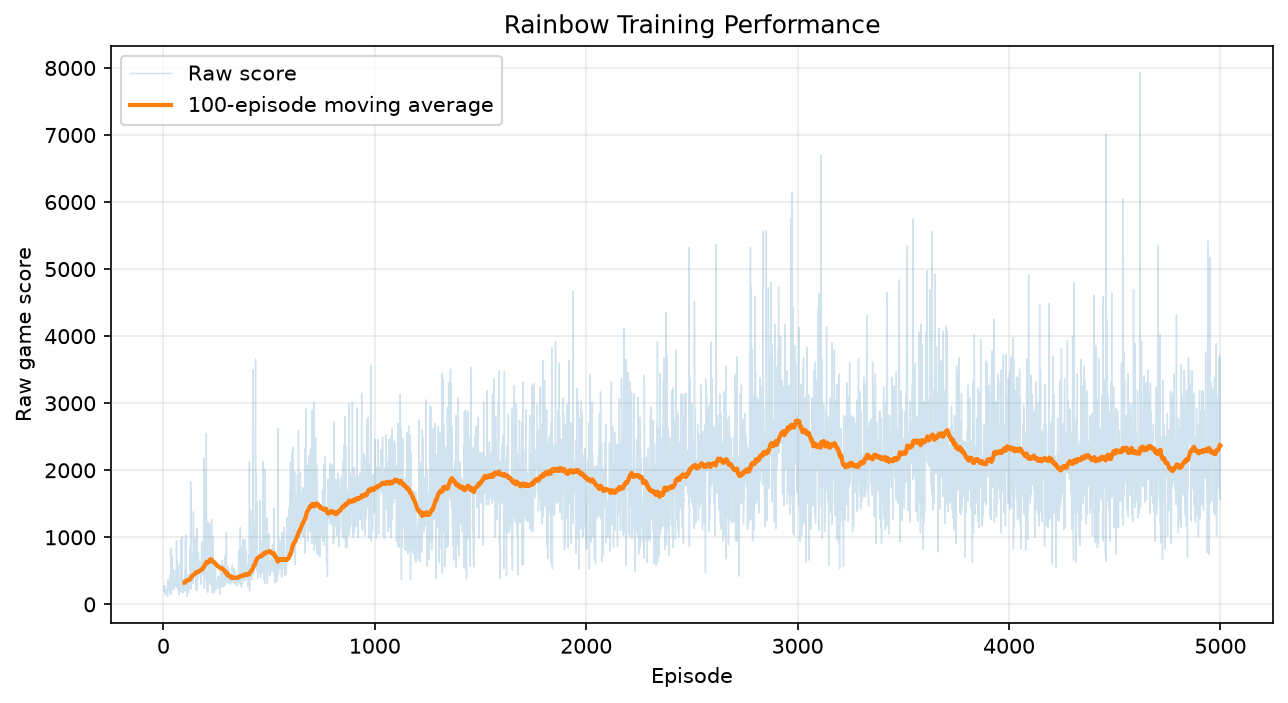

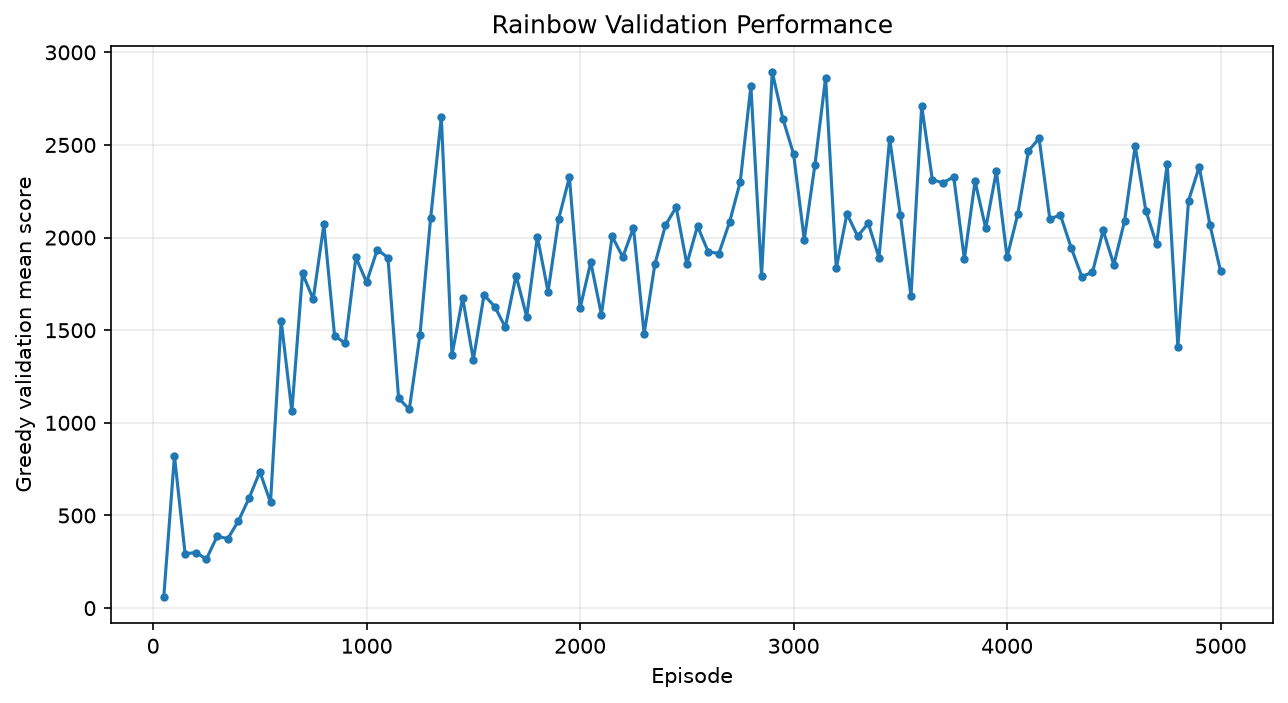

In [7]:
from IPython.display import Image, display
from pathlib import Path

output = Path("Output")

display(Image(filename=str(output / "mspacman_training_rewards.png")))
display(Image(filename=str(output / "mspacman_validation_curve.png")))


# Part (b) - Step 7.1: Q-value Learning Curve

## Objective

Examine how the action-value estimates of the Modified Rainbow DQN change over 5,000 training episodes.

## Recorded Metric

The training log contains `mean_max_q`, which summarizes the mean of the maximum predicted action-values recorded during an episode's optimization updates.

This metric is not the absolute maximum Q-value across all observations in an episode.

## Visualization

Plot:

1. Recorded mean maximum predicted Q-value versus training episode.
2. A 100-episode moving average to highlight long-term changes.

## Interpretation

A changing Q-value curve provides evidence that the network's value estimates are being updated during training.

However, increasing Q-values alone do not prove better game performance. They should be interpreted together with training rewards and independent validation scores.

The C51 value estimates are based on sign-clipped training rewards, not raw MsPacman game scores.

## Safety

Only the saved CSV file is used. No model loading, environment interaction, or gradient updates are performed.

Matplotlib runs in an isolated subprocess and saves the figure directly to the Output directory.


In [8]:

# ============================================================
# STEP 7.1: Q-value Learning Curve
# Safe subprocess plotting
#
# No model loading
# No GPU operations
# No plt.show()
# ============================================================

from pathlib import Path
import subprocess
import sys
import os

# ------------------------------------------------------------
# 1. Input and output paths
# ------------------------------------------------------------

CSV_PATH = (
    Path("results_mspacman_rainbow")
    / "full_training"
    / "rainbow_training_episodes.csv"
).resolve()

OUTPUT_DIR = Path("Output").resolve()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PNG_PATH = (
    OUTPUT_DIR
    / "mspacman_mean_max_q_curve.png"
)

assert CSV_PATH.is_file(), (
    f"Training CSV not found: {CSV_PATH}"
)

print("Input:", CSV_PATH)
print("Output:", PNG_PATH)


# ------------------------------------------------------------
# 2. Isolated plotting script
# ------------------------------------------------------------

plot_script = r'''
import sys

import numpy as np
import pandas as pd

import matplotlib
matplotlib.use("Agg", force=True)

import matplotlib.pyplot as plt

from pathlib import Path


csv_path = Path(sys.argv[1])
png_path = Path(sys.argv[2])

print("Stage 1: Imports successful", flush=True)


# ------------------------------------------------------------
# Read only necessary columns
# ------------------------------------------------------------

df = pd.read_csv(
    csv_path,
    usecols=["episode", "mean_max_q"]
)

df["episode"] = pd.to_numeric(
    df["episode"],
    errors="coerce"
)

df["mean_max_q"] = pd.to_numeric(
    df["mean_max_q"],
    errors="coerce"
)

df = (
    df.replace([np.inf, -np.inf], np.nan)
    .sort_values("episode")
)

valid = df.dropna(
    subset=["episode", "mean_max_q"]
).copy()

assert not valid.empty, "No valid Q-values found."

print(
    f"Stage 2: Loaded {len(df)} rows; "
    f"{len(valid)} valid Q-value records",
    flush=True
)


# ------------------------------------------------------------
# Calculate moving average
# ------------------------------------------------------------

valid["q_ma100"] = (
    valid["mean_max_q"]
    .rolling(
        window=100,
        min_periods=100
    )
    .mean()
)

print(
    "Stage 3: Moving average calculated",
    flush=True
)


# ------------------------------------------------------------
# Plot Q-value curve
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.plot(
    valid["episode"].to_numpy(),
    valid["mean_max_q"].to_numpy(),
    linewidth=0.75,
    alpha=0.30,
    label="Recorded mean maximum predicted Q"
)

ax.plot(
    valid["episode"].to_numpy(),
    valid["q_ma100"].to_numpy(),
    linewidth=2.2,
    label="100-episode moving average"
)

ax.set_title(
    "Modified Rainbow DQN: Q-value Learning Curve"
)

ax.set_xlabel(
    "Training episode"
)

ax.set_ylabel(
    "Mean maximum predicted Q-value"
)

ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()

print(
    "Stage 4: Plot constructed",
    flush=True
)


# ------------------------------------------------------------
# Save figure without displaying it
# ------------------------------------------------------------

fig.savefig(
    png_path,
    dpi=150,
    bbox_inches="tight"
)

plt.close(fig)

print(
    "Stage 5: PNG saved",
    flush=True
)


# ------------------------------------------------------------
# Numerical statistics
# ------------------------------------------------------------

first_100 = (
    valid["mean_max_q"]
    .head(100)
    .mean()
)

last_100 = (
    valid["mean_max_q"]
    .tail(100)
    .mean()
)

print("\nQ-VALUE SUMMARY", flush=True)

print(
    "First valid episode:",
    int(valid["episode"].iloc[0]),
    flush=True
)

print(
    "Last episode:",
    int(valid["episode"].iloc[-1]),
    flush=True
)

print(
    "First 100 valid Q-value mean:",
    round(float(first_100), 4),
    flush=True
)

print(
    "Last 100 Q-value mean:",
    round(float(last_100), 4),
    flush=True
)

print(
    "Overall Q-value minimum:",
    round(float(valid["mean_max_q"].min()), 4),
    flush=True
)

print(
    "Overall Q-value maximum:",
    round(float(valid["mean_max_q"].max()), 4),
    flush=True
)

print(
    "\nStage 6: ALL TESTS PASSED",
    flush=True
)
'''


# ------------------------------------------------------------
# 3. Launch isolated Python process
# ------------------------------------------------------------

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
env["PYTHONUNBUFFERED"] = "1"

try:

    result = subprocess.run(
        [
            sys.executable,
            "-c",
            plot_script,
            str(CSV_PATH),
            str(PNG_PATH)
        ],
        capture_output=True,
        text=True,
        timeout=120,
        env=env
    )

    print("\nExit code:", result.returncode)
    print("\nSTDOUT:\n", result.stdout)

    if result.stderr:
        print(
            "\nSTDERR:\n",
            result.stderr[-4000:]
        )

    if (
        result.returncode == 0
        and PNG_PATH.is_file()
    ):
        print("\nPASS: Q-value curve saved.")
        print("Figure:", PNG_PATH)
    else:
        print("\nFAIL: Check the stage output.")

except subprocess.TimeoutExpired:
    print("\nFAIL: Plotting process timed out.")


Input: C:\Users\24298\Downloads\results_mspacman_rainbow\full_training\rainbow_training_episodes.csv
Output: C:\Users\24298\Downloads\Output\mspacman_mean_max_q_curve.png

Exit code: 0

STDOUT:
 Stage 1: Imports successful
Stage 2: Loaded 5000 rows; 4960 valid Q-value records
Stage 3: Moving average calculated
Stage 4: Plot constructed
Stage 5: PNG saved

Q-VALUE SUMMARY
First valid episode: 41
Last episode: 5000
First 100 valid Q-value mean: 0.7358
Last 100 Q-value mean: 6.1286
Overall Q-value minimum: 0.0979
Overall Q-value maximum: 6.8107

Stage 6: ALL TESTS PASSED


PASS: Q-value curve saved.
Figure: C:\Users\24298\Downloads\Output\mspacman_mean_max_q_curve.png


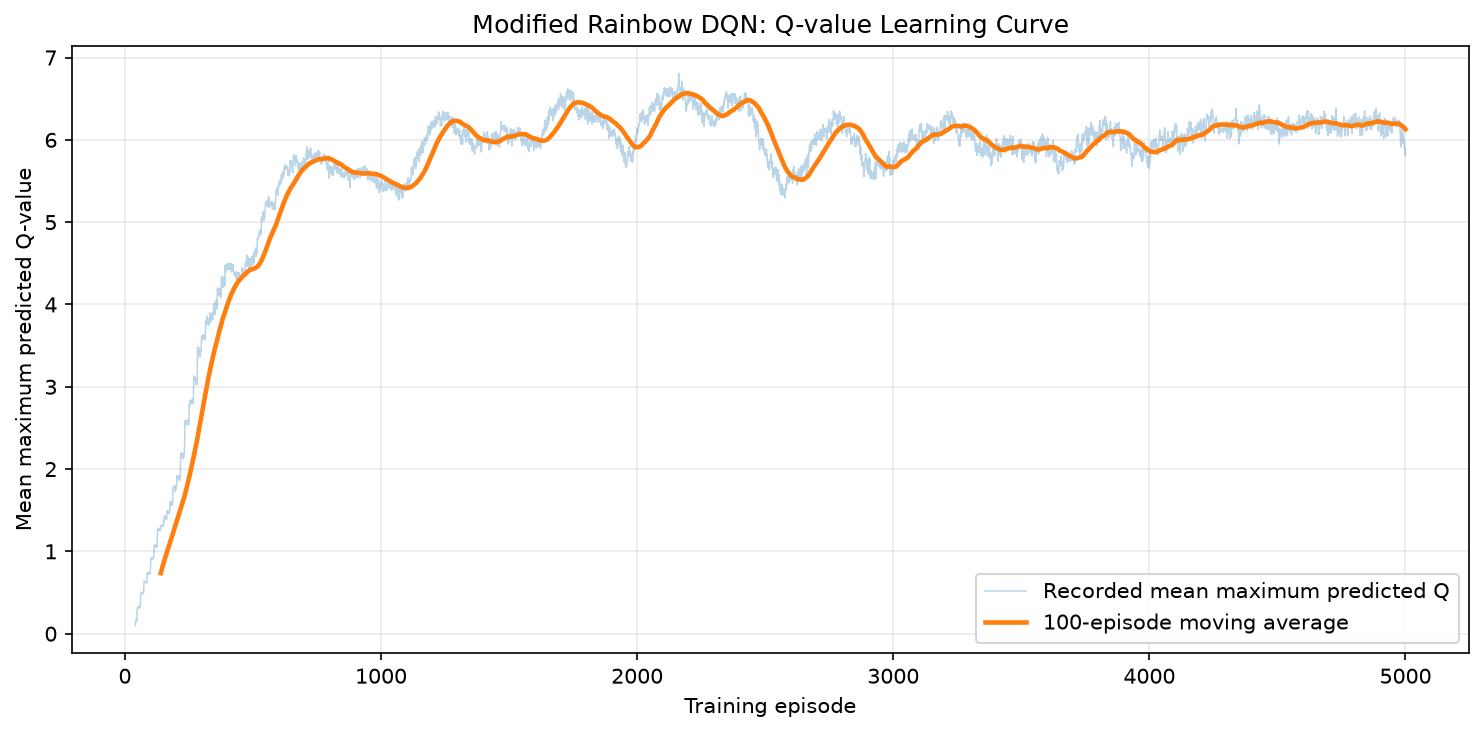

In [9]:
from IPython.display import Image, display
from pathlib import Path

image_path = Path("Output/mspacman_mean_max_q_curve.png")

display(Image(filename=str(image_path), width=1000))

In [10]:

# ============================================================
# Step 8.1: Inspect Best Rainbow Model
# No environment, GPU, or training operations
# ============================================================

from pathlib import Path
import torch
import gc

model_path = (
    Path("results_mspacman_rainbow")
    / "full_training"
    / "rainbow_best.pt"
)

assert model_path.is_file(), model_path

print("Model file:", model_path.resolve())
print(
    "File size:",
    round(model_path.stat().st_size / 1024**2, 2),
    "MB"
)

checkpoint = torch.load(
    model_path,
    map_location="cpu",
    weights_only=True
)

print("\nCheckpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):

    print("\nTop-level keys:")
    for key in checkpoint:
        print(" ", key)

    print("\nModel state dictionaries:")

    for key, value in checkpoint.items():

        if (
            isinstance(value, dict)
            and value
            and all(
                isinstance(v, torch.Tensor)
                for v in value.values()
            )
        ):

            print(
                f"\n{key}: {len(value)} tensors"
            )

            for name, tensor in list(value.items())[:8]:
                print(
                    " ",
                    name,
                    tuple(tensor.shape)
                )

del checkpoint
gc.collect()

print("\nStep 8.1 completed.")


Model file: C:\Users\24298\Downloads\results_mspacman_rainbow\full_training\rainbow_best.pt
File size: 14.57 MB

Checkpoint type: <class 'dict'>

Top-level keys:
  online_state_dict
  episode
  environment_steps
  validation_mean_score
  config

Model state dictionaries:

online_state_dict: 33 tensors
  support (51,)
  conv.0.weight (32, 4, 8, 8)
  conv.0.bias (32,)
  conv.2.weight (64, 32, 4, 4)
  conv.2.bias (64,)
  conv.4.weight (64, 64, 3, 3)
  conv.4.bias (64,)
  fc.0.weight (512, 2688)

Step 8.1 completed.



# Part (b) - Step 8: Independent Evaluation of Modified Rainbow DQN

## Objective

Evaluate the generalization performance of the best Modified Rainbow DQN checkpoint after training for 5,000 episodes on ALE/MsPacman-v5.

## Model Selection

The best checkpoint was selected using the validation results collected during training.

- Best checkpoint: Episode 2900
- Best validation mean score: 2894.0
- Full training budget: 5000 episodes
- Total environment steps: 4,254,796

The best checkpoint is evaluated without further training or parameter updates.

## Evaluation Protocol

The following protocol is used:

- Environment: ALE/MsPacman-v5
- Policy: Greedy action selection
- NoisyNet: Evaluation mode, with parameter noise disabled
- Observation preprocessing: Assignment-provided preprocessing
- Observation history: Four stacked frames
- Evaluation episodes: 500
- Evaluation seeds: 900000 to 900499
- Score: Original, unclipped game reward

The evaluation seeds are separate from those used for training and checkpoint selection.

## Measurements

For the 500 independent episodes, report:

1. Mean raw game score
2. Sample standard deviation
3. Minimum and maximum scores
4. Median score
5. Approximate 95% confidence interval for the mean
6. Histogram of episode scores

The confidence interval is calculated as:

CI = mean +/- 1.96 * (sample standard deviation / sqrt(500))

## Reproducibility

The evaluation reuses the previously validated independent runner.

Completed episodes are recorded immediately in a CSV file. If execution is interrupted, the next run skips completed seeds and continues from the saved results.

The evaluation is performed in an isolated Python subprocess to reduce the risk of Jupyter kernel crashes.

## Interpretation

The 500-episode evaluation provides a more reliable estimate of the selected model's performance than the original 10-episode validation.

A comparison between the independent test mean and the checkpoint's validation mean helps assess whether the selected model's performance generalizes to new random seeds.

No training, gradient updates, or checkpoint modifications are performed.


In [12]:

# ============================================================
# STEP 8: FINAL INDEPENDENT EVALUATION
# Modified Rainbow DQN - MsPacman-v5
#
# 500 episodes, resumable evaluation
# Mean, standard deviation, confidence interval
# Reward histogram
#
# No training or checkpoint modifications.
# ============================================================

from pathlib import Path
import sys
import os
import csv
import json
import re
import hashlib
import subprocess

import numpy as np


# ============================================================
# 1. Configuration
# ============================================================

DATA_DIR = (
    Path("results_mspacman_rainbow")
    / "full_training"
).resolve()

OUTPUT_DIR = Path("Output").resolve()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL = DATA_DIR / "rainbow_best.pt"

RUNNER_FILE = (
    DATA_DIR / "step8_independent_runner.py"
)

RESULT_CSV = (
    DATA_DIR / "step8_best_independent_scores.csv"
)

LOG_FILE = (
    DATA_DIR / "step8_evaluation_500.log"
)

SUMMARY_FILE = (
    DATA_DIR / "step8_evaluation_summary.json"
)

HISTOGRAM_FILE = (
    OUTPUT_DIR
    / "mspacman_independent_reward_histogram.png"
)

N_EVAL_EPISODES = 500

SEED_START = 900000

assert BEST_MODEL.is_file(), (
    f"Missing model: {BEST_MODEL}"
)

assert RUNNER_FILE.is_file(), (
    "Validated evaluation runner not found. "
    "Run the previous Step 8.2 setup first."
)

print("STEP 8: FINAL EVALUATION")
print("Model:", BEST_MODEL)
print("Runner:", RUNNER_FILE)
print("Target episodes:", N_EVAL_EPISODES)
print("Output:", RESULT_CSV)


# ============================================================
# 2. Run the validated evaluation script
# ============================================================

env = os.environ.copy()
env["PYTHONUNBUFFERED"] = "1"

command = [
    sys.executable,
    "-u",
    str(RUNNER_FILE),
    str(BEST_MODEL),
    str(RESULT_CSV),
    str(N_EVAL_EPISODES)
]

print("\nStarting independent evaluation...\n")

with LOG_FILE.open(
    "a",
    encoding="utf-8"
) as log:

    process = subprocess.Popen(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        encoding="utf-8",
        errors="replace",
        bufsize=1,
        env=env
    )

    try:

        for line in process.stdout:

            log.write(line)
            log.flush()

            # Avoid flooding Jupyter with 500 lines.
            match = re.match(
                r"Episode (\d+)/(\d+)",
                line
            )

            if match:

                episode_number = int(
                    match.group(1)
                )

                if (
                    episode_number <= 6
                    or episode_number % 25 == 0
                    or episode_number == 500
                ):
                    print(
                        line,
                        end="",
                        flush=True
                    )

            else:

                print(
                    line,
                    end="",
                    flush=True
                )

        return_code = process.wait()

    except KeyboardInterrupt:

        process.terminate()
        process.wait()

        print(
            "\nEvaluation interrupted. "
            "Completed episodes remain saved."
        )

        raise

print("\nEvaluation process exit code:", return_code)

if return_code != 0:
    raise RuntimeError(
        "Evaluation subprocess failed. "
        f"Inspect: {LOG_FILE}"
    )


# ============================================================
# 3. Load and verify exactly 500 independent scores
# ============================================================

sha256 = hashlib.sha256()

with BEST_MODEL.open("rb") as f:

    for chunk in iter(
        lambda: f.read(1024 * 1024),
        b""
    ):
        sha256.update(chunk)

model_hash = sha256.hexdigest()

score_by_seed = {}

with RESULT_CSV.open(
    "r",
    newline="",
    encoding="utf-8"
) as f:

    reader = csv.DictReader(f)

    for row in reader:

        seed = int(row["seed"])

        if (
            SEED_START
            <= seed
            < SEED_START + N_EVAL_EPISODES
        ):

            assert (
                row["model_sha256"] == model_hash
            ), (
                "Checkpoint hash mismatch. "
                "Do not mix different models."
            )

            assert seed not in score_by_seed, (
                f"Duplicate evaluation seed: {seed}"
            )

            score_by_seed[seed] = float(
                row["raw_score"]
            )

expected_seeds = list(
    range(
        SEED_START,
        SEED_START + N_EVAL_EPISODES
    )
)

missing = [
    seed
    for seed in expected_seeds
    if seed not in score_by_seed
]

assert not missing, (
    f"Missing {len(missing)} evaluation episodes."
)

scores = np.array(
    [score_by_seed[s] for s in expected_seeds],
    dtype=np.float64
)

assert scores.size == 500
assert np.isfinite(scores).all()

print("\n500 unique evaluation seeds verified.")


# ============================================================
# 4. Calculate evaluation statistics
# ============================================================

mean_score = float(
    np.mean(scores)
)

std_score = float(
    np.std(scores, ddof=1)
)

median_score = float(
    np.median(scores)
)

min_score = float(
    np.min(scores)
)

max_score = float(
    np.max(scores)
)

standard_error = (
    std_score / np.sqrt(len(scores))
)

ci_lower = (
    mean_score - 1.96 * standard_error
)

ci_upper = (
    mean_score + 1.96 * standard_error
)

summary = {
    "environment": "ALE/MsPacman-v5",
    "model": str(BEST_MODEL),
    "model_sha256": model_hash,
    "evaluation_episodes": 500,
    "first_seed": SEED_START,
    "last_seed": SEED_START + 499,
    "mean_score": mean_score,
    "sample_std_score": std_score,
    "median_score": median_score,
    "min_score": min_score,
    "max_score": max_score,
    "standard_error": float(standard_error),
    "ci_95_normal_approx": [
        float(ci_lower),
        float(ci_upper)
    ],
    "original_best_validation_mean": 2894.0
}

with SUMMARY_FILE.open(
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )


# ============================================================
# 5. Plot histogram in an isolated subprocess
# ============================================================

plot_script = r'''
import sys
import pandas as pd

import matplotlib
matplotlib.use("Agg", force=True)

import matplotlib.pyplot as plt

csv_path = sys.argv[1]
png_path = sys.argv[2]

df = pd.read_csv(csv_path)

df = df[
    (df["seed"] >= 900000)
    & (df["seed"] < 900500)
].sort_values("seed")

assert len(df) == 500
assert df["seed"].nunique() == 500

scores = df["raw_score"].to_numpy()

mean_score = scores.mean()

fig, ax = plt.subplots(
    figsize=(10, 5.5)
)

ax.hist(
    scores,
    bins=25,
    edgecolor="black",
    alpha=0.75
)

ax.axvline(
    mean_score,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_score:.1f}"
)

ax.set_title(
    "Modified Rainbow DQN: "
    "500-Episode Independent Evaluation"
)

ax.set_xlabel(
    "Raw game score"
)

ax.set_ylabel(
    "Number of episodes"
)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.legend()
fig.tight_layout()

fig.savefig(
    png_path,
    dpi=180,
    bbox_inches="tight"
)

plt.close(fig)

print(
    "Histogram saved successfully:",
    png_path,
    flush=True
)
'''

plot_env = os.environ.copy()
plot_env["MPLBACKEND"] = "Agg"

plot_result = subprocess.run(
    [
        sys.executable,
        "-c",
        plot_script,
        str(RESULT_CSV),
        str(HISTOGRAM_FILE)
    ],
    capture_output=True,
    text=True,
    timeout=120,
    env=plot_env
)

print("\nHistogram process exit code:",
      plot_result.returncode)

print(plot_result.stdout)

if plot_result.returncode != 0:
    print(plot_result.stderr[-4000:])
    raise RuntimeError(
        "Histogram generation failed."
    )

assert HISTOGRAM_FILE.is_file()


# ============================================================
# 6. Final numerical report
# ============================================================

print("\n" + "=" * 60)
print("STEP 8: FINAL INDEPENDENT EVALUATION")
print("=" * 60)

print("Evaluation episodes:", len(scores))
print("Mean score:", round(mean_score, 3))
print("Sample std:", round(std_score, 3))
print("Median score:", round(median_score, 3))
print("Minimum score:", round(min_score, 3))
print("Maximum score:", round(max_score, 3))

print(
    "Approximate 95% CI:",
    (
        round(ci_lower, 3),
        round(ci_upper, 3)
    )
)

print("\nBest validation mean: 2894.0")

print("\nSaved files:")
print("Scores:", RESULT_CSV)
print("Summary:", SUMMARY_FILE)
print("Histogram:", HISTOGRAM_FILE)
print("Log:", LOG_FILE)

print("\nSTEP 8 COMPLETED.")
print("No model training was performed.")


STEP 8: FINAL EVALUATION
Model: C:\Users\24298\Downloads\results_mspacman_rainbow\full_training\rainbow_best.pt
Runner: C:\Users\24298\Downloads\results_mspacman_rainbow\full_training\step8_independent_runner.py
Target episodes: 500
Output: C:\Users\24298\Downloads\results_mspacman_rainbow\full_training\step8_best_independent_scores.csv

Starting independent evaluation...

Checkpoint episode: 2900
Original validation mean: 2894.0
Device: cuda:0
Model loading: PASS
Deterministic policy: PASS
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Episode 6/500 | Seed 900005 | Score 3430 | Steps 931
Episode 25/500 | Seed 900024 | Score 2950 | Steps 979
Episode 50/500 | Seed 900049 | Score 2150 | Steps 1239
Episode 75/500 | Seed 900074 | Score 2040 | Steps 987
Episode 100/500 | Seed 900099 | Score 3160 | Steps 1165
Episode 125/500 | Seed 900124 | Score 2650 | Steps 1011
Episode 150/500 | Seed 900149 | Score 1710 | Steps 741
Episode 175/500 | Seed 900174 | Score 266

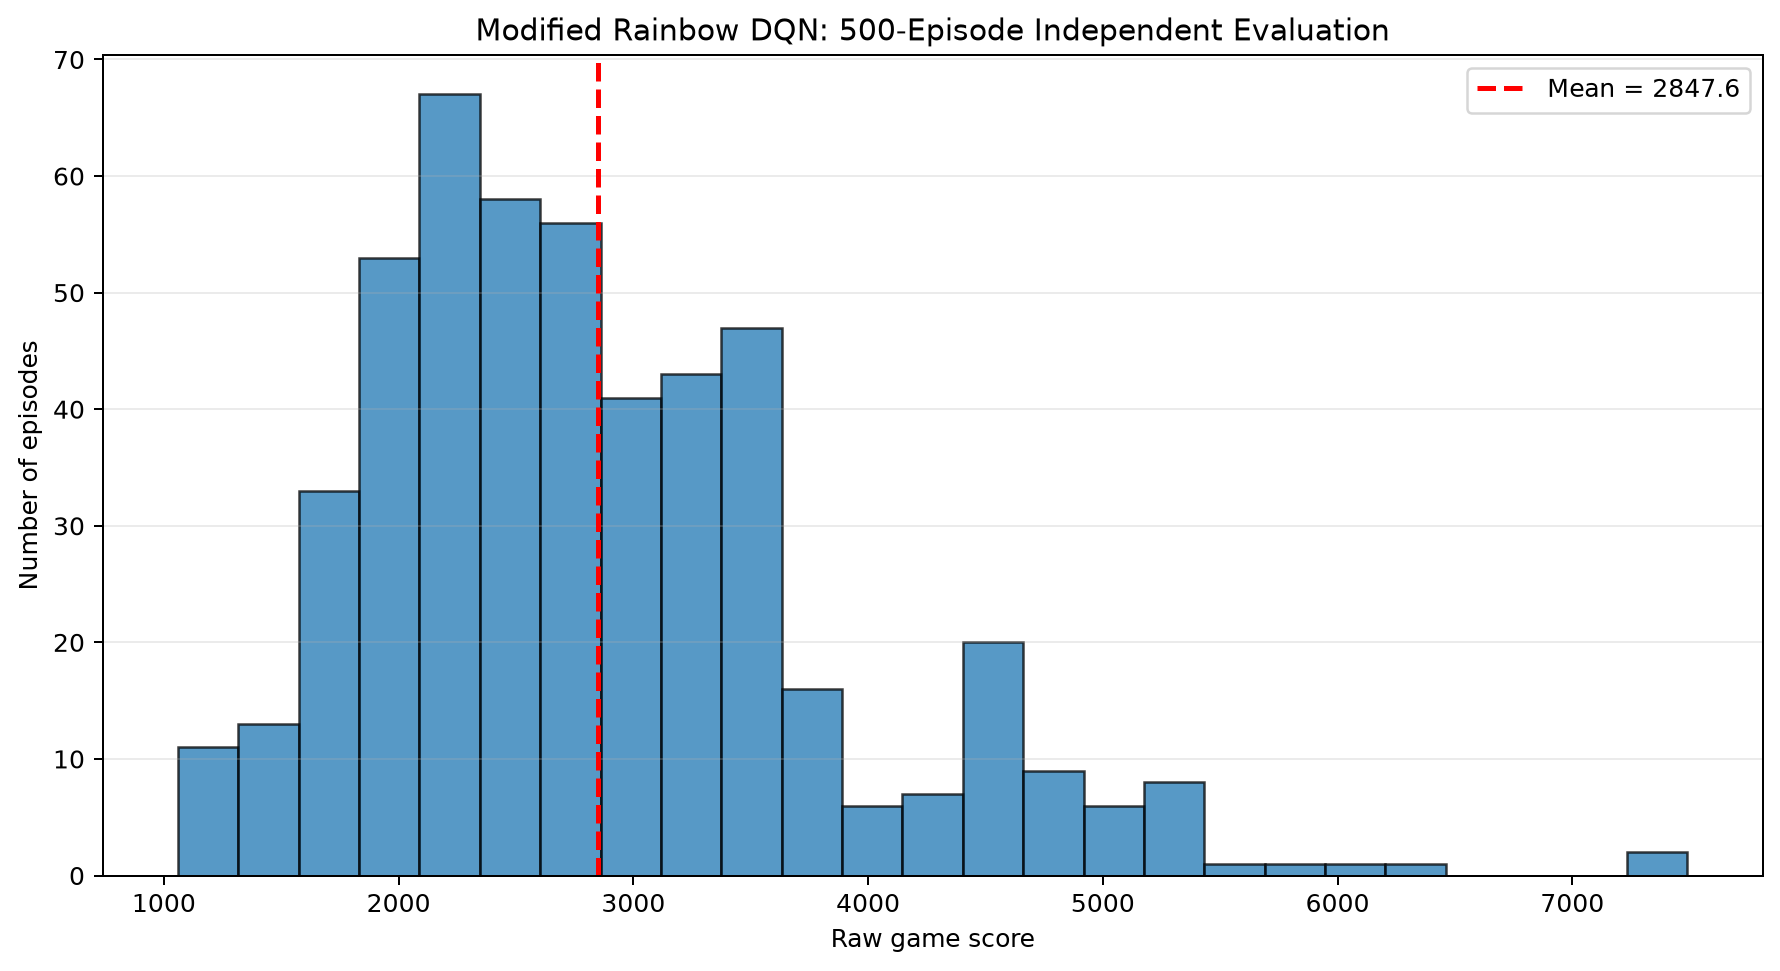

In [13]:

from IPython.display import Image, display

display(
    Image(
        filename="Output/mspacman_independent_reward_histogram.png",
        width=950
    )
)



# Part (b) - Step 9: Edge Case Testing

## Objective

Evaluate the robustness and correctness of the trained Modified Rainbow DQN under boundary conditions and unusual observations.

## Edge Case 1: Extreme Observations

Test all-black, all-white, and real MsPacman observations.

Verify that the assignment preprocessing produces valid int8 observations and that the network outputs finite Q-values.

## Edge Case 2: C51 Distribution Bounds

Check that the predicted categorical probabilities are finite, nonnegative, and sum to one.

Verify that expected Q-values remain within the C51 support interval [-10, 10].

## Edge Case 3: Deterministic Evaluation

Run two complete evaluation episodes using the same random seed and the same best checkpoint.

Compare the raw scores, episode lengths, termination flags, and full action sequences.

Repeated evaluations should produce identical results when both the environment and policy are deterministic under a fixed seed.

## Edge Case 4: Early Episode Cutoff

Limit an evaluation episode to 20 steps.

Verify that this external evaluation cutoff is distinguished from the terminated and truncated signals returned by the environment.

This test does not modify the training replay buffer or Bellman targets.

## Edge Case 5: Action and Reward Integrity

Verify that every selected action belongs to the environment's discrete action space.

Record action frequencies and compare original game rewards with sign-clipped rewards.

Raw game scores must remain unmodified during evaluation.

## Expected Outcome

All numerical and logical assertions should pass. Action diversity and reward statistics are reported as diagnostics rather than being assigned arbitrary pass thresholds.

The tests use the previously trained best checkpoint and perform no optimizer updates.

## Safety and Reproducibility

The tests run in an isolated Python subprocess and reuse the validated evaluation network and preprocessing implementation.

Results are saved in a JSON file. No training checkpoint or existing evaluation CSV is modified.


In [14]:

# ============================================================
# STEP 9: RAINBOW EDGE CASE TESTS
#
# Uses the validated Step 8 evaluation network.
# Isolated subprocess; no training or replay loading.
# ============================================================

from pathlib import Path
import subprocess
import sys
import os

DATA_DIR = (
    Path("results_mspacman_rainbow")
    / "full_training"
).resolve()

MODEL_PATH = DATA_DIR / "rainbow_best.pt"
EVAL_RUNNER = DATA_DIR / "step8_independent_runner.py"

EDGE_RUNNER = DATA_DIR / "step9_edge_cases_runner.py"
EDGE_RESULTS = DATA_DIR / "step9_edge_cases.json"

assert MODEL_PATH.is_file(), MODEL_PATH
assert EVAL_RUNNER.is_file(), EVAL_RUNNER


edge_script = r'''
import sys
import json
import runpy
import hashlib
from pathlib import Path
from collections import deque

import numpy as np
import torch
import gymnasium as gym


# ------------------------------------------------------------
# 1. Reuse validated Step 8 implementation
# ------------------------------------------------------------

model_path = Path(sys.argv[1])
eval_runner = Path(sys.argv[2])
results_path = Path(sys.argv[3])

module = runpy.run_path(
    str(eval_runner),
    run_name="rainbow_edge_case_import"
)

Network = module["EvalRainbowNetwork"]
preprocess = module["preprocess_observation"]

device = torch.device(
    "cuda:0" if torch.cuda.is_available()
    else "cpu"
)

checkpoint = torch.load(
    model_path,
    map_location="cpu",
    weights_only=True
)

model = Network()

model.load_state_dict(
    checkpoint["online_state_dict"],
    strict=True
)

model.to(device)
model.eval()

print("Model loading: PASS", flush=True)
print("Checkpoint episode:", checkpoint["episode"], flush=True)
print("Device:", device, flush=True)

results = {
    "checkpoint_episode": int(checkpoint["episode"]),
    "tests": {}
}


# ------------------------------------------------------------
# 2. Extreme observation test
# ------------------------------------------------------------

env = gym.make("ALE/MsPacman-v5", obs_type="rgb")

try:
    raw_obs, _ = env.reset(seed=910000)

    assert raw_obs.shape == (210, 160, 3)
    assert raw_obs.dtype == np.uint8

    observations = {
        "black": np.zeros_like(raw_obs),
        "white": np.full_like(raw_obs, 255),
        "player_color": np.broadcast_to(
            np.array([210, 164, 74], dtype=np.uint8),
            raw_obs.shape
        ),
        "real": raw_obs
    }

    states = {}

    for name, obs in observations.items():

        frame = preprocess(obs)

        assert frame.shape == (88, 80, 1)
        assert frame.dtype == np.int8

        assert frame.min() >= -128
        assert frame.max() <= 127

        states[name] = np.repeat(
            frame[:, :, 0][None, :, :],
            4,
            axis=0
        )

    assert np.all(states["black"] == -128)
    assert np.all(states["white"] == 127)
    assert np.all(states["player_color"] == -128)

    print(
        "EDGE 1: Extreme observations PASS",
        flush=True
    )

    results["tests"]["extreme_observations"] = {
        "passed": True,
        "cases": list(states.keys())
    }

finally:
    env.close()


# ------------------------------------------------------------
# 3. C51 probability and Q-value bounds
# ------------------------------------------------------------

batch = np.stack(
    list(states.values()),
    axis=0
)

batch_tensor = torch.from_numpy(
    batch.copy()
).to(device)

with torch.inference_mode():

    x = (batch_tensor.float() + 128.0) / 255.0

    features = model.fc(
        model.conv(x).flatten(start_dim=1)
    )

    v = model.value(features).view(-1, 1, 51)
    a = model.advantage(features).view(-1, 9, 51)

    logits = v + a - a.mean(
        dim=1,
        keepdim=True
    )

    probs = torch.softmax(logits, dim=-1)

    q_values = (
        probs * model.support.view(1, 1, 51)
    ).sum(dim=-1)

    direct_q = model.q_values(batch_tensor)

assert torch.isfinite(probs).all().item()
assert torch.isfinite(q_values).all().item()

assert (probs >= 0).all().item()

prob_sums = probs.sum(dim=-1)

assert torch.allclose(
    prob_sums,
    torch.ones_like(prob_sums),
    atol=1e-5
)

assert (q_values >= -10.00001).all().item()
assert (q_values <= 10.00001).all().item()

assert torch.allclose(
    q_values,
    direct_q,
    atol=1e-5
)

print(
    "EDGE 2: C51 distributions and Q bounds PASS",
    flush=True
)

results["tests"]["c51_bounds"] = {
    "passed": True,
    "min_q": float(q_values.min().item()),
    "max_q": float(q_values.max().item()),
    "max_probability_sum_error": float(
        (prob_sums - 1).abs().max().item()
    )
}


# ------------------------------------------------------------
# 4. Reproducible evaluation rollout
# ------------------------------------------------------------

def rollout(env, seed, max_steps):

    obs, _ = env.reset(seed=seed)

    frame = preprocess(obs)[:, :, 0].copy()

    frames = deque(
        [frame.copy() for _ in range(4)],
        maxlen=4
    )

    # Every episode must start from its own
    # newly initialized four-frame stack.
    assert all(
        np.array_equal(f, frame)
        for f in frames
    )

    raw_score = 0.0
    clipped_score = 0.0

    actions = []
    terminated = False
    truncated = False

    for step in range(1, max_steps + 1):

        state = np.stack(
            frames,
            axis=0
        )[None, ...]

        tensor = torch.from_numpy(
            state.copy()
        ).to(device)

        with torch.inference_mode():

            q = model.q_values(tensor)

            assert torch.isfinite(q).all().item()

            action = int(
                q.argmax(dim=1).item()
            )

        assert env.action_space.contains(action)

        actions.append(action)

        (
            obs,
            reward,
            terminated,
            truncated,
            _
        ) = env.step(action)

        raw_score += float(reward)
        clipped_score += float(np.sign(reward))

        next_frame = preprocess(
            obs
        )[:, :, 0].copy()

        frames.append(next_frame)

        assert np.array_equal(
            frames[-1],
            next_frame
        )

        if terminated or truncated:
            break

    forced_cap = (
        step == max_steps
        and not terminated
        and not truncated
    )

    counts = np.bincount(
        actions,
        minlength=9
    )

    frequencies = counts / counts.sum()

    nonzero = frequencies[frequencies > 0]

    entropy = -float(
        np.sum(nonzero * np.log2(nonzero))
    )

    action_digest = hashlib.sha256(
        np.array(actions, dtype=np.uint8).tobytes()
    ).hexdigest()

    return {
        "seed": int(seed),
        "raw_score": float(raw_score),
        "clipped_reward_sum": float(clipped_score),
        "steps": int(step),
        "terminated": bool(terminated),
        "truncated": bool(truncated),
        "forced_cap": bool(forced_cap),
        "distinct_actions": int(np.count_nonzero(counts)),
        "action_entropy_bits": entropy,
        "action_counts": counts.tolist(),
        "action_sha256": action_digest,
        "first_20_actions": actions[:20]
    }


env = gym.make("ALE/MsPacman-v5", obs_type="rgb")

try:

    first = rollout(
        env,
        seed=910011,
        max_steps=27000
    )

    second = rollout(
        env,
        seed=910011,
        max_steps=27000
    )

    # Same seed + same deterministic policy.
    for key in [
        "raw_score",
        "steps",
        "terminated",
        "truncated",
        "action_sha256"
    ]:
        assert first[key] == second[key], (
            f"Determinism failed for {key}"
        )

    assert first["terminated"] or first["truncated"]
    assert not first["forced_cap"]

    print(
        "EDGE 3: Deterministic replay PASS",
        flush=True
    )

    print(
        "Repeated episode score:",
        first["raw_score"],
        "| Steps:",
        first["steps"],
        flush=True
    )

    results["tests"]["determinism"] = {
        "passed": True,
        "first": first,
        "second": second
    }


    # --------------------------------------------------------
    # 5. Deliberate early evaluation cutoff
    # --------------------------------------------------------

    short = rollout(
        env,
        seed=910012,
        max_steps=20
    )

    assert short["steps"] <= 20

    # The cap is imposed by our evaluation code.
    # It is NOT automatically an environment truncation.
    assert short["forced_cap"] == (
        not short["terminated"]
        and not short["truncated"]
    )

    if short["forced_cap"]:
        assert short["steps"] == 20

    print(
        "EDGE 4: Early cutoff PASS",
        "| Forced cap:",
        short["forced_cap"],
        flush=True
    )

    results["tests"]["early_cutoff"] = {
        "passed": True,
        "episode": short
    }


    # --------------------------------------------------------
    # 6. Action and reward integrity
    # --------------------------------------------------------

    assert first["distinct_actions"] >= 1
    assert first["distinct_actions"] <= 9

    assert np.isfinite(first["raw_score"])
    assert np.isfinite(first["clipped_reward_sum"])

    assert sum(first["action_counts"]) == first["steps"]

    print(
        "EDGE 5: Action and reward integrity PASS",
        flush=True
    )

    print(
        "Distinct actions:",
        first["distinct_actions"],
        "| Action entropy:",
        round(first["action_entropy_bits"], 4),
        "bits",
        flush=True
    )

    print(
        "Raw score:",
        first["raw_score"],
        "| Sign-clipped reward sum:",
        first["clipped_reward_sum"],
        flush=True
    )

    results["tests"]["action_reward_integrity"] = {
        "passed": True,
        "distinct_actions": first["distinct_actions"],
        "action_entropy_bits": first["action_entropy_bits"],
        "raw_score": first["raw_score"],
        "clipped_reward_sum": first["clipped_reward_sum"]
    }

finally:
    env.close()


# ------------------------------------------------------------
# 7. Save results
# ------------------------------------------------------------

with results_path.open(
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        results,
        f,
        indent=2
    )

print("\n" + "=" * 55, flush=True)
print("STEP 9: EDGE CASE SUMMARY", flush=True)
print("=" * 55, flush=True)

for test_name, record in results["tests"].items():

    print(
        test_name,
        "PASS" if record["passed"] else "FAIL",
        flush=True
    )

print("\nResults:", results_path, flush=True)
print("All edge case tests passed.", flush=True)
print("No training performed.", flush=True)
'''


# ------------------------------------------------------------
# 3. Save isolated test runner
# ------------------------------------------------------------

EDGE_RUNNER.write_text(
    edge_script,
    encoding="utf-8"
)

print("Edge case runner:", EDGE_RUNNER)
print("Best checkpoint:", MODEL_PATH)


# ------------------------------------------------------------
# 4. Run in independent Python process
# ------------------------------------------------------------

env = os.environ.copy()
env["PYTHONUNBUFFERED"] = "1"

process = subprocess.Popen(
    [
        sys.executable,
        "-u",
        str(EDGE_RUNNER),
        str(MODEL_PATH),
        str(EVAL_RUNNER),
        str(EDGE_RESULTS)
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    encoding="utf-8",
    errors="replace",
    bufsize=1,
    env=env
)

try:

    for line in process.stdout:
        print(line, end="", flush=True)

    exit_code = process.wait()

    print("\nProcess exit code:", exit_code)

    if exit_code == 0:
        print("STEP 9: PASS")
    else:
        print("STEP 9: FAILED - inspect output.")

except KeyboardInterrupt:

    process.terminate()
    process.wait()

    print("Edge case testing interrupted.")


Edge case runner: C:\Users\24298\Downloads\results_mspacman_rainbow\full_training\step9_edge_cases_runner.py
Best checkpoint: C:\Users\24298\Downloads\results_mspacman_rainbow\full_training\rainbow_best.pt
Model loading: PASS
Checkpoint episode: 2900
Device: cuda:0
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
EDGE 1: Extreme observations PASS
EDGE 2: C51 distributions and Q bounds PASS
EDGE 3: Deterministic replay PASS
Repeated episode score: 5050.0 | Steps: 873
EDGE 4: Early cutoff PASS | Forced cap: True
EDGE 5: Action and reward integrity PASS
Distinct actions: 9 | Action entropy: 2.9386 bits
Raw score: 5050.0 | Sign-clipped reward sum: 138.0

STEP 9: EDGE CASE SUMMARY
extreme_observations PASS
c51_bounds PASS
determinism PASS
early_cutoff PASS
action_reward_integrity PASS

Results: C:\Users\24298\Downloads\results_mspacman_rainbow\full_training\step9_edge_cases.json
All edge case tests passed.
No training performed.

Process exit code: 0
STEP 9: P


# Part (b) - Step 10: Validation Experiment 1 - Random Policy Baseline

## Objective

Determine whether the trained Modified Rainbow DQN achieves better game performance than a uniformly random policy.

## Experimental Design

Compare two policies on ALE/MsPacman-v5:

1. Trained Rainbow DQN: reuse the previously completed 500-episode independent evaluation.
2. Random Policy: uniformly sample one of the 9 legal actions at each environment step.

Both policies are evaluated using the same 500 environment seeds, from 900000 to 900499.

The random policy has no neural network, replay buffer, or training process. It provides a performance baseline rather than an alternative DQN implementation.

## Measurements

Record:

- Mean and sample standard deviation of raw game scores
- Mean score improvement
- Ratio of Rainbow mean score to random mean score
- Paired episode score differences
- Approximate 95% confidence interval for the mean paired improvement
- Fraction of evaluation seeds where Rainbow scores higher

## Validation Hypothesis

If Rainbow consistently outperforms random actions on independent game seeds, this supports the conclusion that its performance improvement is due to learned action selection rather than random exploration alone.

The shared seeds improve comparability, although the two policies follow different game trajectories.

## Safety and Reproducibility

The existing Rainbow evaluation CSV is reused without modification.

The random baseline runs in an isolated Python subprocess and saves completed episodes immediately. No checkpoint is loaded, no GPU is needed, and no neural network training is performed.


In [15]:

# ============================================================
# STEP 10: RANDOM POLICY BASELINE
# 500 evaluation episodes, resumable.
# No PyTorch, no model loading, no plots.
# ============================================================

from pathlib import Path
import sys
import os
import csv
import json
import subprocess
import statistics
import math

DATA_DIR = (
    Path("results_mspacman_rainbow")
    / "full_training"
).resolve()

BEST_CSV = DATA_DIR / "step8_best_independent_scores.csv"
RANDOM_CSV = DATA_DIR / "step10_random_policy_scores.csv"
RUNNER = DATA_DIR / "step10_random_runner.py"
SUMMARY_JSON = DATA_DIR / "step10_random_comparison.json"

assert BEST_CSV.is_file(), BEST_CSV

N_EPISODES = 500
SEED_START = 900000

# ------------------------------------------------------------
# 1. Independent random evaluation script
# ------------------------------------------------------------

runner_code = r'''
import csv
import sys
from pathlib import Path

import numpy as np
import gymnasium as gym
import ale_py

gym.register_envs(ale_py)

csv_path = Path(sys.argv[1])
n = int(sys.argv[2])
seed_start = int(sys.argv[3])

columns = ["seed", "raw_score", "steps", "terminated", "truncated"]

completed = set()

if csv_path.exists():
    with csv_path.open("r", newline="", encoding="utf-8") as f:
        for row in csv.DictReader(f):
            seed = int(row["seed"])
            assert seed not in completed, f"Duplicate seed: {seed}"
            completed.add(seed)

env = gym.make("ALE/MsPacman-v5", obs_type="rgb")

try:
    with csv_path.open("a", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=columns)

        if f.tell() == 0:
            writer.writeheader()
            f.flush()

        for i in range(n):
            seed = seed_start + i

            if seed in completed:
                continue

            rng = np.random.default_rng(seed + 12345)
            env.reset(seed=seed)

            score = 0.0
            terminated = False
            truncated = False

            for step in range(1, 27001):
                action = int(rng.integers(0, env.action_space.n))

                _, reward, terminated, truncated, _ = env.step(action)
                score += float(reward)

                if terminated or truncated:
                    break

            writer.writerow({
                "seed": seed,
                "raw_score": score,
                "steps": step,
                "terminated": terminated,
                "truncated": truncated
            })
            f.flush()

            if i < 5 or (i + 1) % 25 == 0:
                print(
                    f"Random {i + 1}/{n} | "
                    f"Score {score:.0f} | Steps {step}",
                    flush=True
                )

finally:
    env.close()

print("Random evaluation completed.", flush=True)
'''

RUNNER.write_text(runner_code, encoding="utf-8")

# ------------------------------------------------------------
# 2. Launch isolated subprocess
# ------------------------------------------------------------

print("Running random-policy baseline...")

process = subprocess.Popen(
    [
        sys.executable, "-u",
        str(RUNNER),
        str(RANDOM_CSV),
        str(N_EPISODES),
        str(SEED_START)
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    encoding="utf-8",
    errors="replace",
    bufsize=1,
    env={**os.environ, "PYTHONUNBUFFERED": "1"}
)

try:
    for line in process.stdout:
        print(line, end="", flush=True)

    exit_code = process.wait()

except KeyboardInterrupt:
    process.terminate()
    process.wait()
    print("Interrupted. Completed random episodes are saved.")
    raise

assert exit_code == 0, (
    f"Random evaluation failed: exit code {exit_code}"
)

# ------------------------------------------------------------
# 3. Load the two sets of evaluation scores
# ------------------------------------------------------------

def load_scores(path):
    result = {}

    with path.open("r", newline="", encoding="utf-8") as f:
        for row in csv.DictReader(f):
            seed = int(row["seed"])

            assert seed not in result, (
                f"Duplicate seed in {path.name}: {seed}"
            )

            result[seed] = float(row["raw_score"])

    expected = set(range(SEED_START, SEED_START + N_EPISODES))
    assert expected.issubset(result.keys()), (
        f"Missing seeds in {path.name}"
    )

    return result


rainbow_data = load_scores(BEST_CSV)
random_data = load_scores(RANDOM_CSV)

seeds = list(range(SEED_START, SEED_START + N_EPISODES))

rainbow = [rainbow_data[s] for s in seeds]
random_scores = [random_data[s] for s in seeds]
differences = [a - b for a, b in zip(rainbow, random_scores)]

# ------------------------------------------------------------
# 4. Quantitative comparison
# ------------------------------------------------------------

rainbow_mean = statistics.mean(rainbow)
random_mean = statistics.mean(random_scores)

rainbow_std = statistics.stdev(rainbow)
random_std = statistics.stdev(random_scores)

difference_mean = statistics.mean(differences)
difference_std = statistics.stdev(differences)

standard_error = difference_std / math.sqrt(N_EPISODES)

ci_lower = difference_mean - 1.96 * standard_error
ci_upper = difference_mean + 1.96 * standard_error

win_fraction = sum(
    a > b for a, b in zip(rainbow, random_scores)
) / N_EPISODES

ratio = (
    rainbow_mean / random_mean
    if random_mean != 0
    else None
)

summary = {
    "episodes": N_EPISODES,
    "rainbow_mean": rainbow_mean,
    "rainbow_std": rainbow_std,
    "random_mean": random_mean,
    "random_std": random_std,
    "mean_paired_improvement": difference_mean,
    "paired_improvement_ci95": [ci_lower, ci_upper],
    "rainbow_to_random_ratio": ratio,
    "rainbow_win_fraction": win_fraction
}

with SUMMARY_JSON.open("w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 55)
print("STEP 10: RANDOM POLICY VALIDATION")
print("=" * 55)

print(f"Episodes: {N_EPISODES}")
print(f"Rainbow mean: {rainbow_mean:.2f}")
print(f"Rainbow std: {rainbow_std:.2f}")
print(f"Random mean: {random_mean:.2f}")
print(f"Random std: {random_std:.2f}")
print(f"Mean paired improvement: {difference_mean:.2f}")
print(f"95% CI of improvement: [{ci_lower:.2f}, {ci_upper:.2f}]")
print(f"Rainbow win fraction: {win_fraction:.2%}")

if ratio is not None:
    print(f"Rainbow / Random mean ratio: {ratio:.2f}x")

print("\nSaved CSV:", RANDOM_CSV)
print("Saved summary:", SUMMARY_JSON)
print("No training performed.")


Running random-policy baseline...
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Random 1/500 | Score 280 | Steps 525
Random 2/500 | Score 310 | Steps 509
Random 3/500 | Score 310 | Steps 587
Random 4/500 | Score 160 | Steps 465
Random 5/500 | Score 220 | Steps 545
Random 25/500 | Score 190 | Steps 375
Random 50/500 | Score 290 | Steps 521
Random 75/500 | Score 260 | Steps 543
Random 100/500 | Score 210 | Steps 521
Random 125/500 | Score 590 | Steps 673
Random 150/500 | Score 330 | Steps 629
Random 175/500 | Score 220 | Steps 553
Random 200/500 | Score 230 | Steps 531
Random 225/500 | Score 140 | Steps 453
Random 250/500 | Score 200 | Steps 447
Random 275/500 | Score 330 | Steps 743
Random 300/500 | Score 330 | Steps 501
Random 325/500 | Score 190 | Steps 377
Random 350/500 | Score 280 | Steps 405
Random 375/500 | Score 280 | Steps 529
Random 400/500 | Score 220 | Steps 483
Random 425/500 | Score 240 | Steps 489
Random 450/500 | Score 210 | Steps 471
Ra


# Part (b) - Step 11: Best vs. Final Checkpoint Validation

## Objective

Investigate training stability by comparing the best validation checkpoint with the final checkpoint after 5,000 training episodes.

## Experimental Design

Compare:

1. Best checkpoint: Episode 2900, selected by validation performance.
2. Final checkpoint: Episode 5000, obtained at the end of training.

Reuse the existing 500-episode evaluation results for the best checkpoint.

Evaluate the final checkpoint on the same 500 independent seeds, from 900000 to 900499.

Both models use greedy action selection with NoisyNet exploration disabled. No additional training is performed.

## Measurements

Report:

- Mean and sample standard deviation of each model's raw game score
- Mean paired score difference
- Approximate 95% confidence interval for the paired difference
- Fraction of seeds on which the best checkpoint outperforms the final checkpoint

## Validation Hypothesis

The final checkpoint may perform worse than the best checkpoint because additional off-policy training does not guarantee monotonic policy improvement.

If the paired performance difference is consistently positive, this supports selecting the best validation checkpoint rather than automatically using the final training weights.

## Reproducibility and Safety

The experiment reuses the previously validated evaluation runner.

Only the lightweight final model is loaded. Evaluation runs in an isolated subprocess, and each completed episode is immediately saved to CSV.

No optimizer updates, replay buffer loading, or modifications to trained checkpoints are performed.


In [16]:

# ============================================================
# STEP 11: BEST VS FINAL CHECKPOINT
#
# Reuse validated evaluation runner.
# Test only the final checkpoint.
# 500 episodes, resumable.
# No training, replay, or plotting.
# ============================================================

from pathlib import Path
import sys
import os
import csv
import json
import re
import hashlib
import subprocess
import statistics
import math


# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

DATA_DIR = (
    Path("results_mspacman_rainbow")
    / "full_training"
).resolve()

BEST_MODEL = DATA_DIR / "rainbow_best.pt"
FINAL_MODEL = DATA_DIR / "rainbow_final.pt"

BEST_CSV = (
    DATA_DIR / "step8_best_independent_scores.csv"
)

FINAL_CSV = (
    DATA_DIR / "step11_final_independent_scores.csv"
)

RUNNER = (
    DATA_DIR / "step8_independent_runner.py"
)

SUMMARY_JSON = (
    DATA_DIR / "step11_best_vs_final_summary.json"
)

LOG_FILE = (
    DATA_DIR / "step11_final_evaluation.log"
)

N_EPISODES = 500
SEED_START = 900000

for path in [
    BEST_MODEL, FINAL_MODEL, BEST_CSV, RUNNER
]:
    assert path.is_file(), f"Missing: {path}"

# Prevent accidentally passing a large full-training checkpoint.
assert FINAL_MODEL.stat().st_size < 100 * 1024**2, (
    "Final checkpoint is unexpectedly large. "
    "Check that rainbow_final.pt is a model-only file."
)

print("Best model:", BEST_MODEL)
print("Final model:", FINAL_MODEL)
print("Evaluation episodes:", N_EPISODES)


# ------------------------------------------------------------
# 2. Evaluate final checkpoint only
# ------------------------------------------------------------

command = [
    sys.executable,
    "-u",
    str(RUNNER),
    str(FINAL_MODEL),
    str(FINAL_CSV),
    str(N_EPISODES)
]

print("\nEvaluating final checkpoint...\n")

with LOG_FILE.open("a", encoding="utf-8") as log:

    process = subprocess.Popen(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        encoding="utf-8",
        errors="replace",
        bufsize=1,
        env={
            **os.environ,
            "PYTHONUNBUFFERED": "1"
        }
    )

    try:
        for line in process.stdout:

            log.write(line)
            log.flush()

            match = re.match(
                r"Episode (\d+)/(\d+)",
                line
            )

            if match:
                n = int(match.group(1))

                if n <= 5 or n % 25 == 0:
                    print(line, end="", flush=True)
            else:
                print(line, end="", flush=True)

        exit_code = process.wait()

    except KeyboardInterrupt:
        process.terminate()
        process.wait()
        print(
            "Interrupted. Completed episodes "
            "remain saved to CSV."
        )
        raise

assert exit_code == 0, (
    f"Evaluation failed. See {LOG_FILE}"
)


# ------------------------------------------------------------
# 3. Read and verify paired scores
# ------------------------------------------------------------

def sha256_file(path):
    digest = hashlib.sha256()

    with path.open("rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


def read_scores(path, expected_hash):

    scores = {}

    with path.open(
        "r", newline="", encoding="utf-8"
    ) as f:

        for row in csv.DictReader(f):

            seed = int(row["seed"])

            if not (
                SEED_START <= seed < SEED_START + N_EPISODES
            ):
                continue

            assert row["model_sha256"] == expected_hash, (
                f"Model mismatch in {path.name}"
            )

            assert seed not in scores, (
                f"Duplicate seed: {seed}"
            )

            scores[seed] = float(row["raw_score"])

    expected = set(
        range(SEED_START, SEED_START + N_EPISODES)
    )

    assert set(scores) == expected, (
        f"Missing evaluation seeds in {path.name}"
    )

    return scores


best_data = read_scores(
    BEST_CSV,
    sha256_file(BEST_MODEL)
)

final_data = read_scores(
    FINAL_CSV,
    sha256_file(FINAL_MODEL)
)

seeds = list(
    range(SEED_START, SEED_START + N_EPISODES)
)

best_scores = [best_data[s] for s in seeds]
final_scores = [final_data[s] for s in seeds]

differences = [
    best - final
    for best, final in zip(best_scores, final_scores)
]

assert all(
    math.isfinite(x)
    for x in best_scores + final_scores
)


# ------------------------------------------------------------
# 4. Numerical comparison
# ------------------------------------------------------------

best_mean = statistics.mean(best_scores)
best_std = statistics.stdev(best_scores)

final_mean = statistics.mean(final_scores)
final_std = statistics.stdev(final_scores)

diff_mean = statistics.mean(differences)
diff_std = statistics.stdev(differences)

margin = (
    1.96 * diff_std / math.sqrt(N_EPISODES)
)

ci = [
    diff_mean - margin,
    diff_mean + margin
]

best_win_rate = (
    sum(d > 0 for d in differences)
    / N_EPISODES
)

ties = sum(d == 0 for d in differences)

summary = {
    "episodes": N_EPISODES,
    "best_checkpoint_episode": 2900,
    "final_checkpoint_episode": 5000,
    "best_mean": best_mean,
    "best_sample_std": best_std,
    "final_mean": final_mean,
    "final_sample_std": final_std,
    "paired_difference_best_minus_final": diff_mean,
    "paired_difference_sample_std": diff_std,
    "paired_difference_ci95": ci,
    "best_win_fraction": best_win_rate,
    "tie_count": ties
}

with SUMMARY_JSON.open(
    "w", encoding="utf-8"
) as f:

    json.dump(summary, f, indent=2)


# ------------------------------------------------------------
# 5. Report
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("STEP 11: BEST VS FINAL CHECKPOINT")
print("=" * 60)

print("Paired evaluation episodes:", N_EPISODES)

print(
    f"Best checkpoint:  {best_mean:.2f} "
    f"+/- {best_std:.2f}"
)

print(
    f"Final checkpoint: {final_mean:.2f} "
    f"+/- {final_std:.2f}"
)

print(
    f"Mean difference (Best - Final): "
    f"{diff_mean:.2f}"
)

print(
    f"Approx. 95% CI of paired difference: "
    f"[{ci[0]:.2f}, {ci[1]:.2f}]"
)

print(
    f"Best checkpoint win fraction: "
    f"{best_win_rate:.2%}"
)

print("Tied episodes:", ties)

print("\nSaved results:")
print("Final scores:", FINAL_CSV)
print("Summary:", SUMMARY_JSON)
print("Log:", LOG_FILE)

print("\nNo training performed.")


Best model: C:\Users\24298\Downloads\results_mspacman_rainbow\full_training\rainbow_best.pt
Final model: C:\Users\24298\Downloads\results_mspacman_rainbow\full_training\rainbow_final.pt
Evaluation episodes: 500

Evaluating final checkpoint...

Checkpoint episode: 5000
Original validation mean: 2894.0
Device: cuda:0
Model loading: PASS
Deterministic policy: PASS
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Episode 1/500 | Seed 900000 | Score 2520 | Steps 1099
Episode 2/500 | Seed 900001 | Score 1760 | Steps 771
Episode 3/500 | Seed 900002 | Score 2040 | Steps 1083
Episode 4/500 | Seed 900003 | Score 1960 | Steps 981
Episode 5/500 | Seed 900004 | Score 2230 | Steps 933
Episode 25/500 | Seed 900024 | Score 1480 | Steps 933
Episode 50/500 | Seed 900049 | Score 1530 | Steps 903
Episode 75/500 | Seed 900074 | Score 1430 | Steps 967
Episode 100/500 | Seed 900099 | Score 1450 | Steps 747
Episode 125/500 | Seed 900124 | Score 1650 | Steps 861
Episode 150/500 |

In [17]:

# ============================================================
# STEP 12: VALIDATION RESULTS VISUALIZATION
#
# Three policies, 500 paired seeds.
# Subprocess plotting: no Jupyter rendering risk.
# No PyTorch, Atari environment, or training.
# ============================================================

from pathlib import Path
import subprocess
import sys
import os


# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

DATA_DIR = (
    Path("results_mspacman_rainbow")
    / "full_training"
).resolve()

OUTPUT_DIR = Path("Output").resolve()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BEST_CSV = DATA_DIR / "step8_best_independent_scores.csv"
FINAL_CSV = DATA_DIR / "step11_final_independent_scores.csv"
RANDOM_CSV = DATA_DIR / "step10_random_policy_scores.csv"

FIGURE_1 = (
    OUTPUT_DIR / "mspacman_policy_comparison.png"
)

FIGURE_2 = (
    OUTPUT_DIR / "mspacman_best_final_paired_difference.png"
)

for path in [BEST_CSV, FINAL_CSV, RANDOM_CSV]:
    assert path.is_file(), f"Missing file: {path}"

print("Input files verified.")
print("Output directory:", OUTPUT_DIR)


# ------------------------------------------------------------
# 2. Subprocess plotting script
# ------------------------------------------------------------

plot_script = r'''
import sys
import csv
import math

import numpy as np

import matplotlib
matplotlib.use("Agg", force=True)

from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg


best_path = sys.argv[1]
final_path = sys.argv[2]
random_path = sys.argv[3]

figure_1_path = sys.argv[4]
figure_2_path = sys.argv[5]

SEED_START = 900000
N = 500

print("Stage 1: Imports successful", flush=True)


# ------------------------------------------------------------
# Read and validate data
# ------------------------------------------------------------

def read_scores(path):

    records = {}

    with open(
        path,
        "r",
        newline="",
        encoding="utf-8"
    ) as f:

        for row in csv.DictReader(f):

            seed = int(row["seed"])

            if not SEED_START <= seed < SEED_START + N:
                continue

            if seed in records:
                raise ValueError(
                    f"Duplicate seed {seed} in {path}"
                )

            score = float(row["raw_score"])

            if not math.isfinite(score):
                raise ValueError(
                    f"Nonfinite score at seed {seed}"
                )

            records[seed] = score

    expected = set(range(SEED_START, SEED_START + N))

    if set(records) != expected:
        raise ValueError(
            f"Incomplete evaluation: {path}. "
            f"Expected {N}, got {len(records)}."
        )

    return np.array(
        [
            records[seed]
            for seed in range(
                SEED_START, SEED_START + N
            )
        ],
        dtype=np.float64
    )


best = read_scores(best_path)
final = read_scores(final_path)
random_scores = read_scores(random_path)

print(
    "Stage 2: All 500 paired seeds verified",
    flush=True
)


# ------------------------------------------------------------
# Compute statistics
# ------------------------------------------------------------

policies = [
    "Random Policy",
    "Best Rainbow\nEpisode 2900",
    "Final Rainbow\nEpisode 5000"
]

datasets = [
    random_scores,
    best,
    final
]

means = np.array(
    [x.mean() for x in datasets]
)

stds = np.array(
    [x.std(ddof=1) for x in datasets]
)

# Normal-approximation 95% CI for means.
ci_halfwidths = 1.96 * stds / np.sqrt(N)

paired_difference = best - final

paired_mean = paired_difference.mean()

paired_std = paired_difference.std(ddof=1)

paired_ci_halfwidth = (
    1.96 * paired_std / np.sqrt(N)
)

wins = int(np.sum(paired_difference > 0))
losses = int(np.sum(paired_difference < 0))
ties = int(np.sum(paired_difference == 0))

print(
    "Stage 3: Statistics calculated",
    flush=True
)


# ============================================================
# FIGURE 1: POLICY PERFORMANCE COMPARISON
# ============================================================

fig = Figure(figsize=(10, 5.5), dpi=160)
canvas = FigureCanvasAgg(fig)

ax = fig.add_subplot(111)

positions = np.arange(3)

bars = ax.bar(
    positions,
    means,
    yerr=ci_halfwidths,
    capsize=7,
    width=0.60,
    color=["#A0A0A0", "#397AC9", "#E29B4B"],
    edgecolor="black",
    linewidth=0.7,
    error_kw={
        "elinewidth": 1.5,
        "capthick": 1.5
    }
)

for bar, value, ci in zip(
    bars, means, ci_halfwidths
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + ci + 75,
        f"{value:,.1f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

ax.set_xticks(positions)
ax.set_xticklabels(policies)

ax.set_title(
    "MsPacman: Independent Policy Comparison"
)

ax.set_ylabel(
    "Mean raw game score (500 episodes)"
)

ax.set_ylim(
    0,
    float(np.max(means + ci_halfwidths)) * 1.18
)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.set_axisbelow(True)

ax.text(
    0.02,
    0.97,
    "Error bars: approximate 95% CI of the mean",
    transform=ax.transAxes,
    fontsize=9,
    va="top"
)

fig.tight_layout()
canvas.print_png(figure_1_path)

print(
    "Stage 4: Policy comparison PNG saved",
    flush=True
)

fig.clear()
del canvas, fig


# ============================================================
# FIGURE 2: PAIRED SCORE DIFFERENCE HISTOGRAM
# ============================================================

fig = Figure(figsize=(10, 5.5), dpi=160)
canvas = FigureCanvasAgg(fig)

ax = fig.add_subplot(111)

ax.hist(
    paired_difference,
    bins=30,
    color="#397AC9",
    alpha=0.80,
    edgecolor="white"
)

ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.6,
    label="Equal performance (0)"
)

ax.axvline(
    paired_mean,
    color="#D34B46",
    linestyle="-",
    linewidth=2,
    label=f"Mean difference = {paired_mean:.1f}"
)

ax.set_title(
    "Best vs. Final Rainbow: Paired Score Differences"
)

ax.set_xlabel(
    "Best checkpoint score - Final checkpoint score"
)

ax.set_ylabel(
    "Number of evaluation seeds"
)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.legend()

ax.text(
    0.98,
    0.97,
    (
        f"Best wins: {wins}/500\n"
        f"Final wins: {losses}/500\n"
        f"Ties: {ties}/500"
    ),
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=10,
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "#CCCCCC",
        "alpha": 0.95
    }
)

fig.tight_layout()
canvas.print_png(figure_2_path)

print(
    "Stage 5: Paired difference PNG saved",
    flush=True
)

fig.clear()
del canvas, fig


# ------------------------------------------------------------
# Numerical summary
# ------------------------------------------------------------

print("\n" + "=" * 55, flush=True)
print("STEP 12: VALIDATION RESULTS", flush=True)
print("=" * 55, flush=True)

for name, mean, std, ci in zip(
    policies, means, stds, ci_halfwidths
):
    print(
        name.replace("\n", " ") + ": "
        f"mean={mean:.2f}, std={std:.2f}, "
        f"95% CI=[{mean-ci:.2f}, {mean+ci:.2f}]",
        flush=True
    )

print(
    f"\nBest - Final mean difference: "
    f"{paired_mean:.2f}",
    flush=True
)

print(
    "Paired difference 95% CI: "
    f"[{paired_mean-paired_ci_halfwidth:.2f}, "
    f"{paired_mean+paired_ci_halfwidth:.2f}]",
    flush=True
)

print(
    f"Best wins: {wins}, "
    f"Final wins: {losses}, "
    f"Ties: {ties}",
    flush=True
)

print(
    "\nStage 6: ALL TESTS PASSED",
    flush=True
)
'''


# ------------------------------------------------------------
# 3. Run isolated plotting subprocess
# ------------------------------------------------------------

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
env["PYTHONUNBUFFERED"] = "1"

try:

    result = subprocess.run(
        [
            sys.executable,
            "-c",
            plot_script,
            str(BEST_CSV),
            str(FINAL_CSV),
            str(RANDOM_CSV),
            str(FIGURE_1),
            str(FIGURE_2)
        ],
        capture_output=True,
        text=True,
        timeout=120,
        env=env
    )

    print("\nExit code:", result.returncode)
    print("\nSTDOUT:\n", result.stdout)

    if result.stderr:
        print(
            "\nSTDERR:\n",
            result.stderr[-4000:]
        )

    if result.returncode == 0:

        assert FIGURE_1.is_file()
        assert FIGURE_2.is_file()

        print("\nSTEP 12: PASS")
        print("\nSaved figures:")
        print(FIGURE_1)
        print(FIGURE_2)

    else:
        print("\nSTEP 12: FAILED")

except subprocess.TimeoutExpired:

    print("\nSTEP 12: Plotting timed out.")


Input files verified.
Output directory: C:\Users\24298\Downloads\Output

Exit code: 0

STDOUT:
 Stage 1: Imports successful
Stage 2: All 500 paired seeds verified
Stage 3: Statistics calculated
Stage 4: Policy comparison PNG saved
Stage 5: Paired difference PNG saved

STEP 12: VALIDATION RESULTS
Random Policy: mean=252.98, std=104.47, 95% CI=[243.82, 262.14]
Best Rainbow Episode 2900: mean=2847.64, std=984.67, 95% CI=[2761.33, 2933.95]
Final Rainbow Episode 5000: mean=1988.38, std=613.64, 95% CI=[1934.59, 2042.17]

Best - Final mean difference: 859.26
Paired difference 95% CI: [756.67, 961.85]
Best wins: 400, Final wins: 99, Ties: 1

Stage 6: ALL TESTS PASSED


STEP 12: PASS

Saved figures:
C:\Users\24298\Downloads\Output\mspacman_policy_comparison.png
C:\Users\24298\Downloads\Output\mspacman_best_final_paired_difference.png



mspacman_policy_comparison.png


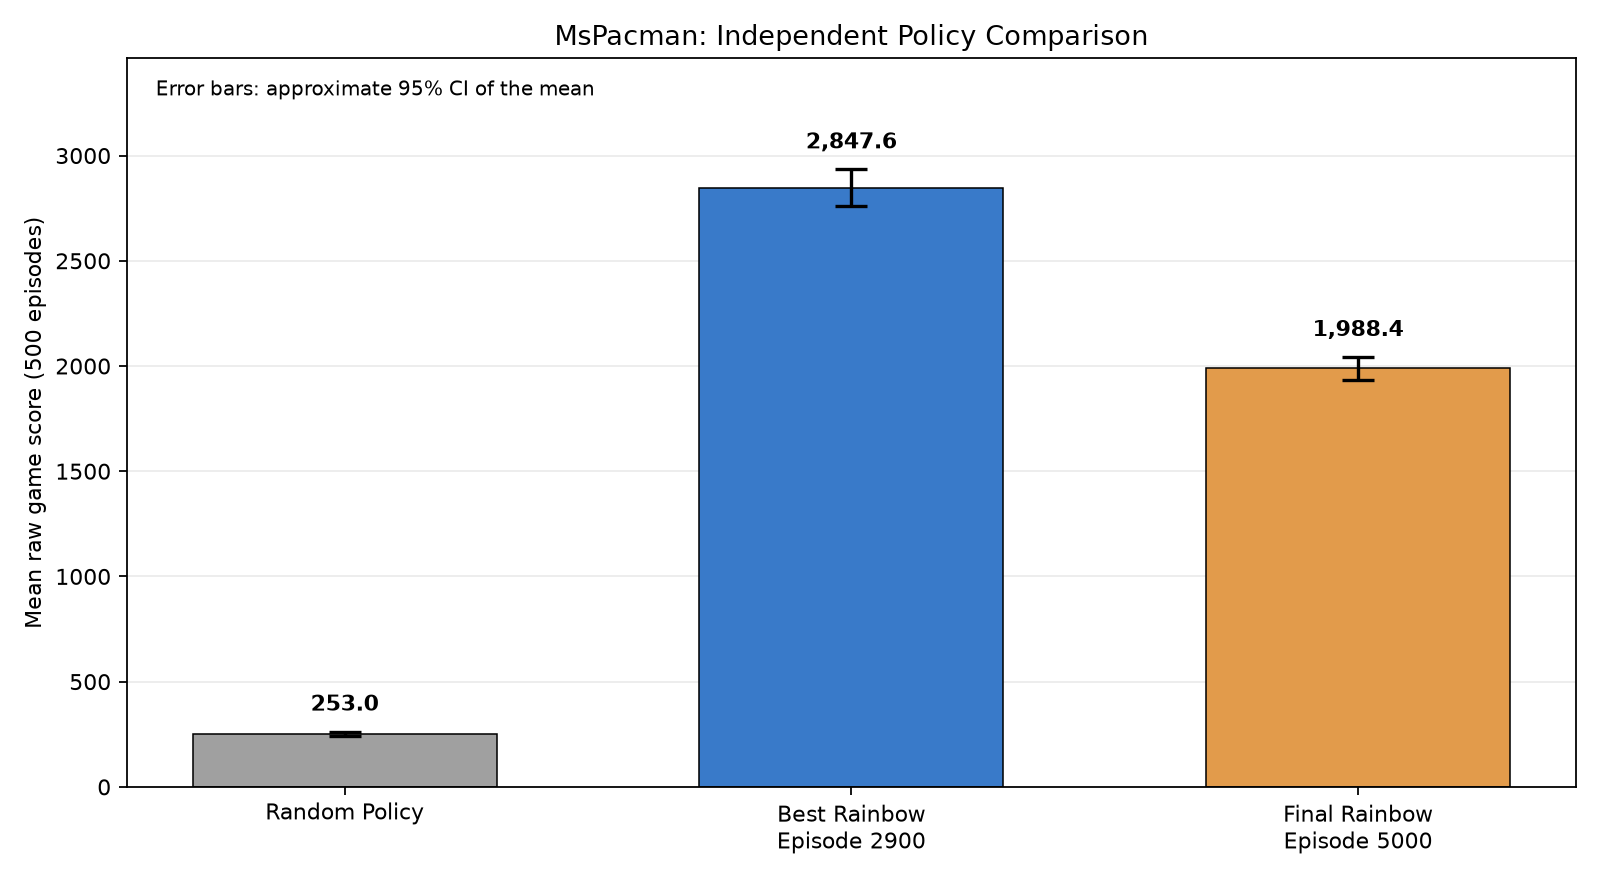


mspacman_best_final_paired_difference.png


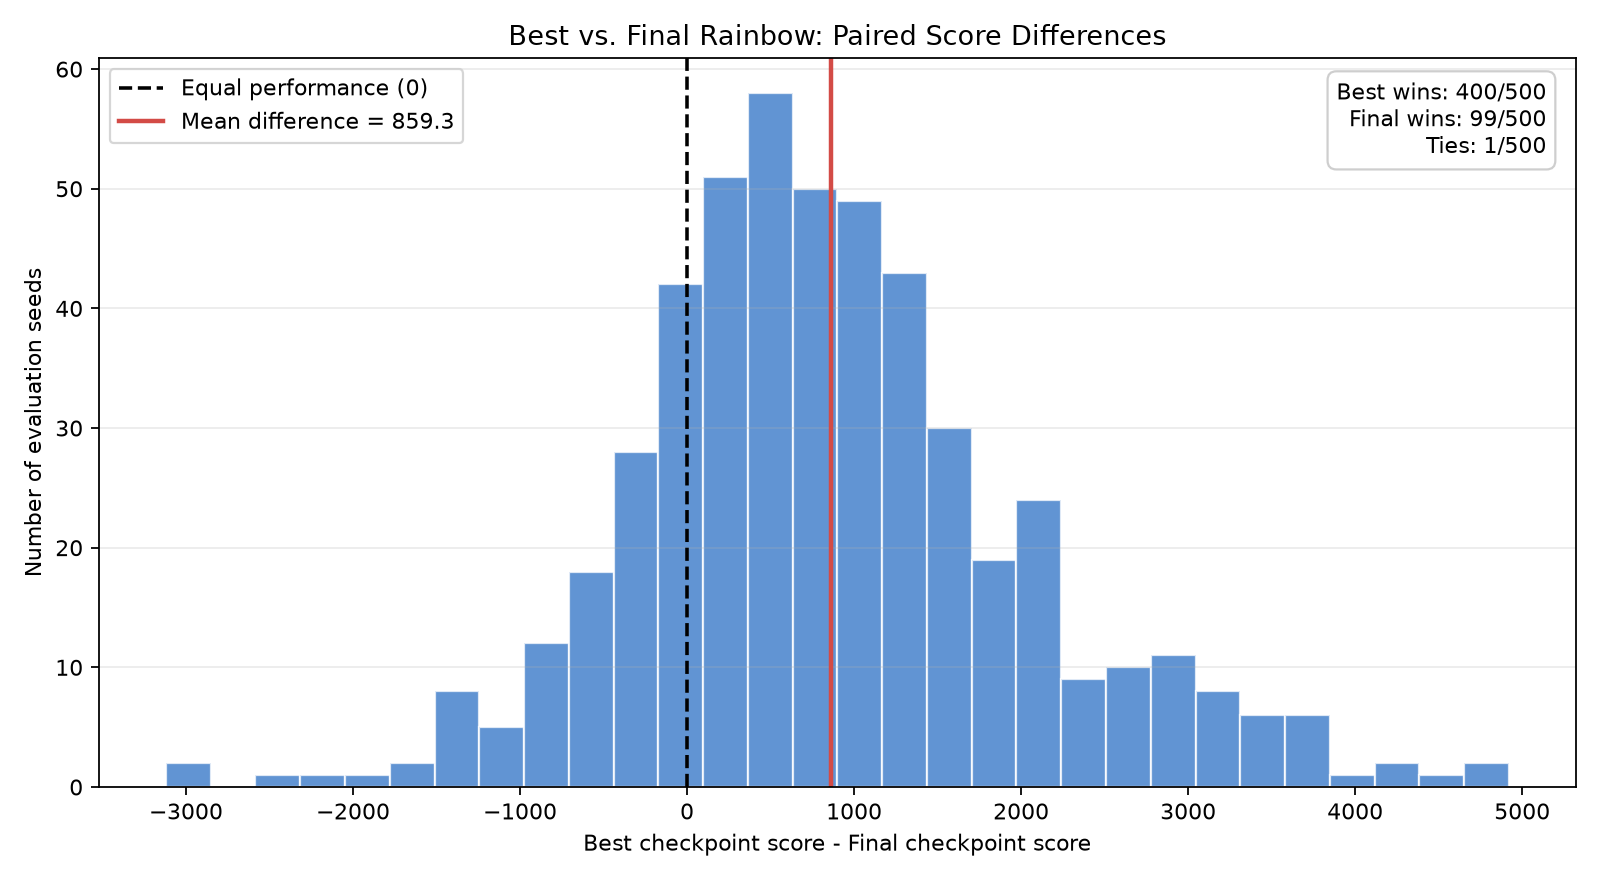

In [18]:

from pathlib import Path
from IPython.display import Image, display

output_dir = Path("Output")

figures = [
    "mspacman_policy_comparison.png",
    "mspacman_best_final_paired_difference.png"
]

for filename in figures:
    image_path = output_dir / filename

    if image_path.exists():
        print(f"\n{filename}")
        display(Image(filename=str(image_path), width=1000))
    else:
        print(f"File not found: {image_path.resolve()}")



# Part (b) - Step 13: Non-standard Visualization

## Rainbow Action-Preference and Decision-Margin Map

### Objective

Develop a non-standard visualization that reveals how the trained Rainbow agent makes decisions during actual MsPacman gameplay.

### Experimental Design

Run the best Rainbow checkpoint on three independent environment seeds.

For every decision step, record:

- The greedy action selected by the policy
- The difference between the highest and second-highest predicted Q-values
- The total raw game score

### Visualization

The upper heatmap shows the selected action at each decision step. Each action has a distinct color.

The lower heatmap shows the Q-value margin between the best and second-best actions.

A larger margin indicates a stronger preference in the network's predicted action values. It does not necessarily imply that the action is correct or that the prediction is well calibrated.

### Research Questions

1. Does the policy use multiple actions throughout an episode?
2. How frequently does it switch between actions?
3. Does its Q-value margin vary over the course of gameplay?
4. Are there periods where multiple actions have s and reward histograms do not reveal.

### Reproducibility

The experiment uses the existing best checkpoint and the validated independent evaluation implementation.

No training or gradient updates are performed. Execution and plotting take place in an isolated Python subprocess.


In [20]:

# ============================================================
# STEP 13 - CELL 1
# Collect Action and Q-value Margin Data
#
# If the completed JSON already exists:
#   Validate it and SKIP game evaluation.
#
# Otherwise:
#   Run PyTorch + Atari in an isolated subprocess.
#
# No Matplotlib in this process.
# ============================================================

from pathlib import Path
import json
import math
import os
import subprocess
import sys

DATA_DIR = (
    Path("results_mspacman_rainbow")
    / "full_training"
).resolve()

MODEL_PATH = DATA_DIR / "rainbow_best.pt"
EVAL_RUNNER = DATA_DIR / "step8_independent_runner.py"

JSON_PATH = DATA_DIR / "step13_action_map_data.json"
COLLECT_SCRIPT = DATA_DIR / "step13_collect_only.py"

SEEDS = [910100, 910101, 910102]

assert MODEL_PATH.is_file(), MODEL_PATH
assert EVAL_RUNNER.is_file(), EVAL_RUNNER


# ------------------------------------------------------------
# 1. Check existing trajectory data
# ------------------------------------------------------------

def validate_saved_data(path):

    with path.open("r", encoding="utf-8") as f:
        data = json.load(f)

    records = data["records"]

    assert data["checkpoint_episode"] == 2900
    assert len(records) == 3
    assert len(data["action_names"]) == 9

    assert [r["seed"] for r in records] == SEEDS

    for record in records:

        actions = record["actions"]
        margins = record["q_margins"]
        steps = int(record["steps"])

        assert steps > 0
        assert len(actions) == steps
        assert len(margins) == steps

        assert all(
            isinstance(a, int) and 0 <= a < 9
            for a in actions
        )

        assert all(
            math.isfinite(m) and m >= 0
            for m in margins
        )

        assert math.isfinite(record["score"])

    return data


if JSON_PATH.is_file():

    print("Existing Step 13 JSON found.")
    saved = validate_saved_data(JSON_PATH)

    print("Saved data validation: PASS")
    print("Game rollouts skipped.")

else:

    print("No existing JSON. Collecting trajectories.")

    collect_code = r'''
import sys
import json
import os
import runpy
from pathlib import Path
from collections import deque

import numpy as np
import torch
import gymnasium as gym
import ale_py

gym.register_envs(ale_py)
torch.set_num_threads(1)

model_path = Path(sys.argv[1])
eval_runner = Path(sys.argv[2])
json_path = Path(sys.argv[3])

# Reuse the previously validated evaluation implementation.
module = runpy.run_path(
    str(eval_runner),
    run_name="step13_evaluation_import"
)

Network = module["EvalRainbowNetwork"]
preprocess = module["preprocess_observation"]

checkpoint = torch.load(
    model_path,
    map_location="cpu",
    weights_only=True
)

device = torch.device(
    "cuda:0" if torch.cuda.is_available()
    else "cpu"
)

model = Network()

model.load_state_dict(
    checkpoint["online_state_dict"],
    strict=True
)

model.to(device)
model.eval()

print("Model loading: PASS", flush=True)
print("Device:", device, flush=True)
print(
    "Checkpoint episode:",
    checkpoint["episode"],
    flush=True
)

env = gym.make(
    "ALE/MsPacman-v5",
    obs_type="rgb"
)

seeds = [910100, 910101, 910102]
records = []

try:

    try:
        action_names = list(
            env.unwrapped.get_action_meanings()
        )
    except (AttributeError, NotImplementedError):
        action_names = [
            f"Action {i}" for i in range(9)
        ]

    if len(action_names) != 9:
        action_names = [
            f"Action {i}" for i in range(9)
        ]

    for seed in seeds:

        obs, _ = env.reset(seed=seed)

        first = preprocess(obs)[:, :, 0].copy()

        frames = deque(
            [first.copy() for _ in range(4)],
            maxlen=4
        )

        actions = []
        margins = []
        score = 0.0

        terminated = False
        truncated = False

        for step in range(1, 27001):

            state = np.stack(
                frames, axis=0
            )[None, ...]

            tensor = torch.from_numpy(
                state
            ).to(device)

            with torch.inference_mode():

                q = model.q_values(tensor)[0]

                top2 = torch.topk(
                    q, k=2
                )

                action = int(
                    top2.indices[0].item()
                )

                margin = float(
                    (
                        top2.values[0]
                        - top2.values[1]
                    ).item()
                )

            assert env.action_space.contains(action)
            assert np.isfinite(margin)

            actions.append(action)
            margins.append(max(margin, 0.0))

            (
                obs,
                reward,
                terminated,
                truncated,
                _
            ) = env.step(action)

            score += float(reward)

            next_frame = preprocess(
                obs
            )[:, :, 0].copy()

            frames.append(next_frame)

            if terminated or truncated:
                break

        changes = sum(
            actions[i] != actions[i - 1]
            for i in range(1, len(actions))
        )

        record = {
            "seed": int(seed),
            "score": float(score),
            "steps": len(actions),
            "actions": actions,
            "q_margins": margins,
            "distinct_actions": int(
                len(set(actions))
            ),
            "action_switch_rate": float(
                changes / max(1, len(actions) - 1)
            ),
            "mean_q_margin": float(
                np.mean(margins)
            ),
            "terminated": bool(terminated),
            "truncated": bool(truncated)
        }

        records.append(record)

        print(
            f"Seed {seed} | "
            f"Score {score:.0f} | "
            f"Steps {len(actions)} | "
            f"Distinct actions {record['distinct_actions']} | "
            f"Mean Q margin {record['mean_q_margin']:.4f}",
            flush=True
        )

finally:
    env.close()

data = {
    "checkpoint_episode": int(
        checkpoint["episode"]
    ),
    "action_names": action_names,
    "records": records
}

# Atomic JSON write to avoid partially saved results.
temp_path = json_path.with_suffix(".json.tmp")

with temp_path.open("w", encoding="utf-8") as f:
    json.dump(data, f)

os.replace(temp_path, json_path)

print(
    "Three trajectories saved successfully.",
    flush=True
)
'''

    COLLECT_SCRIPT.write_text(
        collect_code,
        encoding="utf-8"
    )

    env = os.environ.copy()
    env["PYTHONUNBUFFERED"] = "1"
    env.pop("KMP_DUPLICATE_LIB_OK", None)

    result = subprocess.run(
        [
            sys.executable,
            "-u",
            str(COLLECT_SCRIPT),
            str(MODEL_PATH),
            str(EVAL_RUNNER),
            str(JSON_PATH)
        ],
        capture_output=True,
        text=True,
        timeout=600,
        env=env
    )

    print(result.stdout)

    if result.stderr:
        print("STDERR:", result.stderr[-4000:])

    if result.returncode != 0:
        raise RuntimeError(
            "Trajectory collection failed."
        )

    saved = validate_saved_data(JSON_PATH)
    print("New trajectory data validation: PASS")


# ------------------------------------------------------------
# 2. Summary
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("STEP 13 - CELL 1 SUMMARY")
print("=" * 55)

for record in saved["records"]:

    print(
        f"Seed {record['seed']} | "
        f"Score {record['score']:.0f} | "
        f"Steps {record['steps']} | "
        f"Actions {record['distinct_actions']} | "
        f"Mean Q Margin {record['mean_q_margin']:.4f}"
    )

print("\nData file:", JSON_PATH)
print("CELL 1: PASS")
print("No training performed.")


Existing Step 13 JSON found.
Saved data validation: PASS
Game rollouts skipped.

STEP 13 - CELL 1 SUMMARY
Seed 910100 | Score 2620 | Steps 1231 | Actions 9 | Mean Q Margin 0.0254
Seed 910101 | Score 3830 | Steps 1133 | Actions 9 | Mean Q Margin 0.0230
Seed 910102 | Score 1760 | Steps 1251 | Actions 9 | Mean Q Margin 0.0332

Data file: C:\Users\24298\Downloads\results_mspacman_rainbow\full_training\step13_action_map_data.json
CELL 1: PASS
No training performed.


In [21]:

# ============================================================
# STEP 13 - CELL 2
# Non-standard Rainbow Action-Preference Visualization
#
# Reads existing JSON only.
# Matplotlib runs in a fresh isolated subprocess.
# No PyTorch, CUDA, ALE, model, or game evaluation.
# ============================================================

from pathlib import Path
import subprocess
import sys
import os

DATA_DIR = (
    Path("results_mspacman_rainbow")
    / "full_training"
).resolve()

OUTPUT_DIR = Path("Output").resolve()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

JSON_PATH = (
    DATA_DIR / "step13_action_map_data.json"
)

PNG_PATH = (
    OUTPUT_DIR / "mspacman_action_preference_map.png"
)

assert JSON_PATH.is_file(), (
    f"Trajectory JSON not found: {JSON_PATH}"
)


# ------------------------------------------------------------
# 1. Plotting-only subprocess script
# ------------------------------------------------------------

plot_code = r'''
import sys
import json
import os
from pathlib import Path

import numpy as np

import matplotlib
matplotlib.use("Agg", force=True)

from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.colors import ListedColormap, BoundaryNorm


# ------------------------------------------------------------
# 2. Load stored trajectories
# ------------------------------------------------------------

json_path = Path(sys.argv[1])
png_path = Path(sys.argv[2])

with json_path.open("r", encoding="utf-8") as f:
    data = json.load(f)

records = data["records"]
action_names = data["action_names"]

assert len(records) == 3
assert len(action_names) == 9

print(
    "Stage 1: Trajectory JSON loaded",
    flush=True
)


# ------------------------------------------------------------
# 3. Validate and assemble action matrices
# ------------------------------------------------------------

max_steps = max(
    int(r["steps"]) for r in records
)

n = len(records)

action_matrix = np.full(
    (n, max_steps),
    np.nan,
    dtype=np.float32
)

margin_matrix = np.full(
    (n, max_steps),
    np.nan,
    dtype=np.float32
)

for i, record in enumerate(records):

    actions = np.asarray(
        record["actions"],
        dtype=np.int32
    )

    margins = np.asarray(
        record["q_margins"],
        dtype=np.float32
    )

    steps = int(record["steps"])

    assert len(actions) == steps
    assert len(margins) == steps

    assert np.all(
        (actions >= 0) & (actions <= 8)
    )

    assert np.isfinite(margins).all()
    assert np.all(margins >= 0)

    action_matrix[i, :steps] = actions
    margin_matrix[i, :steps] = margins

print(
    "Stage 2: Trajectory matrices validated",
    flush=True
)


# ------------------------------------------------------------
# 4. Prepare figure
# ------------------------------------------------------------

fig = Figure(
    figsize=(14, 7),
    dpi=160
)

canvas = FigureCanvasAgg(fig)

ax1 = fig.add_subplot(211)
ax2 = fig.add_subplot(212, sharex=ax1)

labels = [
    f"Seed {r['seed']} | {r['score']:.0f} pts"
    for r in records
]


# ------------------------------------------------------------
# 5. Upper panel: Greedy action selection
# ------------------------------------------------------------

action_colors = [
    "#607D8B",
    "#E69F00",
    "#56B4E9",
    "#009E73",
    "#D55E00",
    "#CC79A7",
    "#7570B3",
    "#66A61E",
    "#E6AB02"
]

action_cmap = ListedColormap(
    action_colors
)

action_cmap.set_bad("white")

# Exactly 9 color bins for actions 0 through 8.
boundaries = np.arange(
    -0.5, 9.5, 1.0
)

action_norm = BoundaryNorm(
    boundaries,
    ncolors=9
)

im1 = ax1.imshow(
    np.ma.masked_invalid(
        action_matrix
    ),
    aspect="auto",
    interpolation="nearest",
    cmap=action_cmap,
    norm=action_norm
)

ax1.set_title(
    "Greedy Action-Preference Timeline",
    fontsize=12
)

ax1.set_yticks(
    np.arange(n)
)

ax1.set_yticklabels(
    labels
)

ax1.set_ylabel(
    "Evaluation episode"
)


# ------------------------------------------------------------
# 6. Lower panel: Q-value margin
# ------------------------------------------------------------

valid_margins = margin_matrix[
    np.isfinite(margin_matrix)
]

assert len(valid_margins) > 0

q95 = float(
    np.percentile(valid_margins, 95)
)

q_upper = max(q95, 1e-6)

margin_cmap = (
    matplotlib.colormaps["viridis"].copy()
)

margin_cmap.set_bad("white")

im2 = ax2.imshow(
    np.ma.masked_invalid(
        margin_matrix
    ),
    aspect="auto",
    interpolation="nearest",
    cmap=margin_cmap,
    vmin=0,
    vmax=q_upper
)

ax2.set_title(
    "Decision Margin: Best Q minus Second-Best Q",
    fontsize=12
)

ax2.set_yticks(
    np.arange(n)
)

ax2.set_yticklabels(
    labels
)

ax2.set_xlabel(
    "Decision step within episode"
)

ax2.set_ylabel(
    "Evaluation episode"
)


# ------------------------------------------------------------
# 7. Add colorbars and action labels
# ------------------------------------------------------------

fig.subplots_adjust(
    left=0.22,
    right=0.78,
    top=0.87,
    bottom=0.10,
    hspace=0.40
)

action_colorbar_axis = fig.add_axes(
    [0.81, 0.55, 0.02, 0.29]
)

cb1 = fig.colorbar(
    im1,
    cax=action_colorbar_axis,
    ticks=np.arange(9)
)

cb1.ax.set_yticklabels(
    [
        f"{i}: {name}"
        for i, name in enumerate(action_names)
    ]
)

cb1.ax.tick_params(
    labelsize=8
)

margin_colorbar_axis = fig.add_axes(
    [0.81, 0.15, 0.02, 0.28]
)

cb2 = fig.colorbar(
    im2,
    cax=margin_colorbar_axis
)

cb2.set_label(
    "Predicted Q-value margin"
)

fig.suptitle(
    "Modified Rainbow DQN: "
    "Action-Preference and Decision-Margin Map",
    fontsize=14
)

print(
    "Stage 3: Visualization constructed",
    flush=True
)


# ------------------------------------------------------------
# 8. Save PNG atomically
# ------------------------------------------------------------

temp_png = png_path.with_name(
    png_path.stem + ".tmp.png"
)

canvas.print_png(
    str(temp_png)
)

os.replace(
    temp_png,
    png_path
)

fig.clear()

print(
    "Stage 4: PNG saved",
    flush=True
)


# ------------------------------------------------------------
# 9. Numerical summary
# ------------------------------------------------------------

print(
    "\nACTION-PREFERENCE SUMMARY",
    flush=True
)

for record in records:

    print(
        f"Seed {record['seed']} | "
        f"Score {record['score']:.0f} | "
        f"Steps {record['steps']} | "
        f"Distinct actions {record['distinct_actions']} | "
        f"Switch rate {record['action_switch_rate']:.4f} | "
        f"Mean Q margin {record['mean_q_margin']:.4f}",
        flush=True
    )

print(
    f"\nQ-margin 95th percentile: {q95:.5f}",
    flush=True
)

print(
    "Stage 5: ALL TESTS PASSED",
    flush=True
)
'''


# ------------------------------------------------------------
# 10. Run a fresh plotting-only subprocess
# ------------------------------------------------------------

env = os.environ.copy()

env["MPLBACKEND"] = "Agg"
env["PYTHONUNBUFFERED"] = "1"

# Never bypass duplicate OpenMP runtime detection.
env.pop("KMP_DUPLICATE_LIB_OK", None)

print("Running plotting-only subprocess...\n")

result = subprocess.run(
    [
        sys.executable,
        "-u",
        "-c",
        plot_code,
        str(JSON_PATH),
        str(PNG_PATH)
    ],
    capture_output=True,
    text=True,
    timeout=120,
    env=env
)

print("Exit code:", result.returncode)

print("\nSTDOUT:\n", result.stdout)

if result.stderr:

    print(
        "\nSTDERR:\n",
        result.stderr[-4000:]
    )

if (
    result.returncode == 0
    and PNG_PATH.is_file()
):

    print("\nSTEP 13: PASS")

    print(
        "Saved figure:",
        PNG_PATH
    )

else:

    print("\nSTEP 13: FAILED")


Running plotting-only subprocess...

Exit code: 0

STDOUT:
 Stage 1: Trajectory JSON loaded
Stage 2: Trajectory matrices validated
Stage 3: Visualization constructed
Stage 4: PNG saved

ACTION-PREFERENCE SUMMARY
Seed 910100 | Score 2620 | Steps 1231 | Distinct actions 9 | Switch rate 0.3732 | Mean Q margin 0.0254
Seed 910101 | Score 3830 | Steps 1133 | Distinct actions 9 | Switch rate 0.3860 | Mean Q margin 0.0230
Seed 910102 | Score 1760 | Steps 1251 | Distinct actions 9 | Switch rate 0.3128 | Mean Q margin 0.0332

Q-margin 95th percentile: 0.09565
Stage 5: ALL TESTS PASSED


STEP 13: PASS
Saved figure: C:\Users\24298\Downloads\Output\mspacman_action_preference_map.png


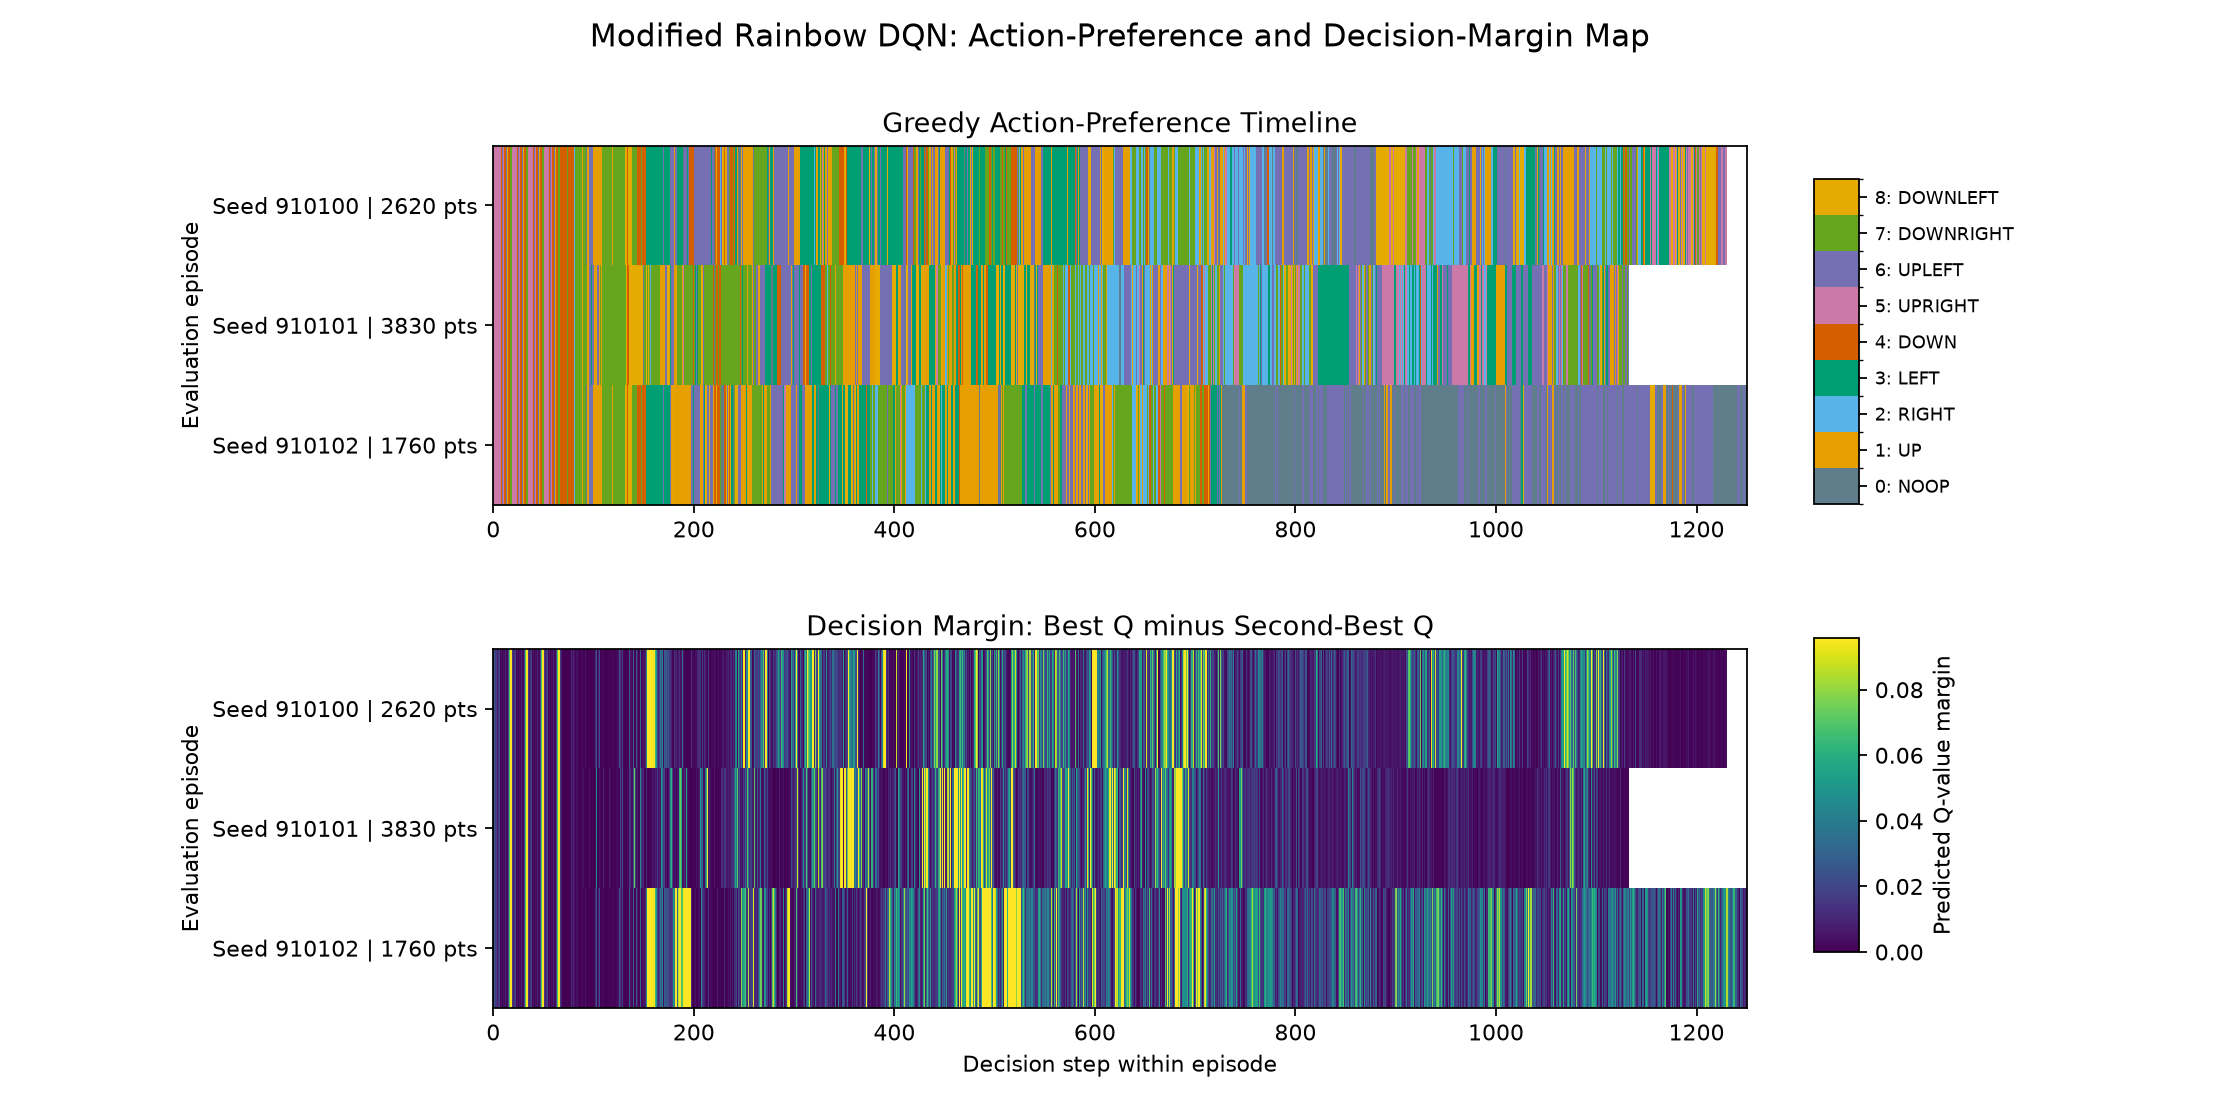

In [22]:

from pathlib import Path
from IPython.display import Image, display

image_path = Path("Output/mspacman_action_preference_map.png")

assert image_path.exists(), f"Image not found: {image_path.resolve()}"

display(Image(filename=str(image_path), width=1200))



# Part (b) - Step 14: Additional Three-Month Validation and Research Plan

## 1. Motivation

Given an additional three months, I would investigate the training stability, sample efficiency, and generalization of the Modified Rainbow DQN on ALE/MsPacman-v5.

Our completed experiments provide strong evidence that the agent learned a useful control policy.

Key experimental results include:

- Training budget: 5,000 episodes and 4,254,796 environment steps.
- Initial 100-episode mean training score: 322.8.
- Final 100-episode mean training score: 2370.5.
- Best checkpoint: Episode 2900.
- Best checkpoint independent evaluation: 2847.64 +/- 984.67 over 500 episodes.
- Random policy evaluation: 252.98 +/- 104.47 over 500 episodes.
- Rainbow outperformed the random policy by approximately 11.26 times in mean score.
- Final checkpoint evaluation: 1988.38 +/- 613.64 over 500 episodes.
- Best-minus-final paired score difference: 859.26, with an approximate 95% confidence interval of [756.67, 961.85].

An important observation is that the best checkpoint substantially outperformed the final checkpoint, despite the additional training.

Furthermore, the recorded mean maximum Q-values became relatively stable late in training, while validation performance continued to fluctuate.

These findings motivate a more systematic investigation of whether the performance degradation is caused by optimization instability, exploration behavior, replay sampling, or other aspects of the learning algorithm.

## 2. Experiment A: Multi-Seed Training Reproducibility

### Research Question

Is the observed performance improvement and late-stage degradation consistent across independent training runs?

### Experimental Design

Repeat the full Modified Rainbow DQN training procedure with at least three independent training seeds, increasing to five if computational resources permit.

Use identical network architectures, reward preprocessing, hyperparameters, and environment-step budgets.

Evaluate checkpoints at fixed intervals using the same held-out validation seed set.

After checkpoint selection, evaluate each selected model on a separate test seed set.

### Measurements

- Mean and standard deviation of evaluation scores across training runs
- Best and final checkpoint performance for each run
- Episode or environment step at which the best checkpoint occurs
- Variability in learning curves across independent seeds
- Fraction of runs exhibiting late-stage performance degradation

### Validation Purpose

This experiment would determine whether the Episode 2900 performance peak is a reproducible learning phenomenon or a result specific to one training seed.

Reporting performance across independent training runs would provide stronger evidence of algorithmic reliability than evaluating a single trained model.

## 3. Experiment B: Rainbow Component Ablation Study

### Research Question

Which Rainbow components contribute most strongly to learning efficiency and training stability?

### Experimental Design

Compare the complete Modified Rainbow implementation against controlled variants with one component altered at a time.

Priority comparisons would include:

1. Prioritized replay versus uniform replay sampling
2. NoisyNet exploration versus epsilon-greedy exploration
3. Three-step returns versus one-step returns
4. Dueling architecture versus a standard action-value head

A Standard DQN baseline could also be included if computational resources permit.

For each comparison, keep the environment, preprocessing, network capacity where feasible, training budget, and evaluation protocol consistent.

### Measurements

- Independent evaluation mean score
- Sample efficiency measured in environment steps
- Area under the validation learning curve
- Variation in performance across training seeds
- Best-to-final checkpoint performance gap

### Validation Purpose

These experiments would identify whether a particular Rainbow component improves early learning but contributes to instability later in training.

Ablations should not be interpreted as proof that an individual component is universally beneficial or harmful, because interactions between Rainbow components may also matter.

## 4. Experiment C: Learning Rate and Target Network Stability

### Research Question

Can optimization changes reduce the decline in policy performance observed after the best checkpoint?

### Experimental Design

Compare the current fixed learning rate of 1e-4 with alternative schedules:

- Fixed learning rate of 1e-4
- Linear learning rate decay
- Cosine learning rate decay

Additionally, investigate different target-network synchronization intervals while keeping other settings fixed.

All schedules should be defined before training begins, rather than selected using final test scores.

### Measurements

- Best and final checkpoint scores
- Validation-score variability during late training
- Distributional cross-entropy loss
- Predicted Q-value trajectories
- Difference between best and final checkpoint performance

### Validation Purpose

If learning rate decay reduces late-stage performance loss across multiple training seeds, this would support the hypothesis that continued optimization with a fixed learning rate contributes to instability.

However, a reduction in loss or Q-value fluctuations would not by itself demonstrate better policy performance. Improvements must be confirmed through independent evaluation.

## 5. Experiment D: Replay Buffer and Sampling Efficiency

### Research Question

How do replay capacity and prioritized sampling affect learning efficiency and policy stability?

### Experimental Design

Compare replay capacities of:

- 50,000 stored frames
- 100,000 stored frames
- 200,000 stored frames

Separately investigate prioritized replay parameters, including priority exponent alpha and importance-sampling correction beta.

Collect replay diagnostics throughout training, including the distribution of sampled transition ages and priority values.

Analyze how the sampling distribution changes as older experiences are overwritten.

### Measurements

- Validation score versus environment steps
- Frequency of repeated transition sampling
- Distribution of sampled experience ages
- Effective importance-sampling weights
- Late-stage evaluation performance

### Validation Purpose

This experiment would examine whether limited historical diversity or overly concentrated prioritized sampling contributes to unstable policy improvement.

Replay changes would be evaluated through actual game performance and sample efficiency, rather than only checking buffer implementation correctness.

## 6. Experiment E: Robustness and Generalization

### Research Question

Does the trained policy remain effective under game conditions different from those used during training?

### Experimental Design

Evaluate selected policies under controlled changes to the Atari environment.

Possible changes include:

- Alternative sticky-action probabilities
- Different no-op initial-state distributions
- Different episode initialization seeds
- Controlled observation perturbations

For image perturbation experiments, use small, explicitly defined changes and maintain the required input shape and preprocessing.

Evaluate the original training configuration separately from the modified conditions.

### Measurements

- Mean game score under each condition
- Relative performance reduction from the original environment
- Episode length and termination statistics
- Changes in action-selection distributions
- Performance variation across independent seeds

### Validation Purpose

This experiment would test whether the agent learned robust game behavior or relied heavily on the specific observation and transition distributions encountered during training.

Results from altered environments would be reported as robustness tests, not as directly interchangeable with standard MsPacman benchmark scores.

## 7. Experiment F: Interpreting Agent Decision-Making

### Research Question

Can internal action-value estimates explain changes in policy behavior and game performance?

### Experimental Design

Extend the non-standard Action-Preference and Decision-Margin Map developed in Step 13.

Collect action sequences, Q-value margins, and game outcomes from a larger set of independent episodes.

Compare high-scoring and low-scoring trajectories using matched evaluation conditions.

Analyze:

- Action-switching frequency
- Frequency of individual action selections
- Mean and distribution of Q-value margins
- Changes in Q-value margins before game termination
- Associations between action patterns and game scores

### Measurements

- Action-switching rates
- Action entropy
- Q-value margin distributions
- Score-conditioned behavioral statistics
- Correlation estimates with uncertainty intervals

### Validation Purpose

This analysis would investigate whether particular action patterns or value-estimation characteristics are associated with successful gameplay.

Importantly, a small Q-value margin does not necessarily imply an incorrect decision, and correlations between behavior and score would not establish causality.

## 8. Three-Month Schedule

### Month 1: Reproducibility and Benchmarking

- Reproduce the full Rainbow experiment using multiple training seeds.
- Establish a consistent evaluation protocol.
- Quantify best-versus-final checkpoint differences across runs.
- Begin the highest-priority Rainbow component ablations.

Primary deliverable: Reproducibility report and multi-seed learning curves.

### Month 2: Training Stability and Sample Efficiency

- Compare fixed and scheduled learning rates.
- Investigate target-network synchronization intervals.
- Study replay buffer capacity and prioritized sampling.
- Identify configurations that reduce validation-score fluctuations.

Primary deliverable: Controlled ablation results and training stability analysis.

### Month 3: Robustness and Behavioral Interpretation

- Evaluate generalization under controlled environment changes.
- Extend action-preference visualization to more trajectories.
- Compare the best-performing configurations across independent seeds.
- Conduct final held-out evaluations and statistical comparisons.

Primary deliverable: Robustness analysis, behavioral visualizations, and a final comparison of improved training configurations.

## 9. Experimental Controls and Statistical Validation

To ensure convincing conclusions, all experiments would follow these principles:

- Use environment steps as the primary training-budget measure.
- Keep evaluation seeds separate from training and checkpoint-selection seeds.
- Repeat important comparisons across multiple independent training seeds.
- Compare policies under matched environments and evaluation budgets.
- Report confidence intervals and effect sizes, not only the best observed score.
- Avoid selecting hyperparameters using the final held-out test set.
- Record computational cost and training throughput.
- Preserve checkpoints and evaluation logs for reproducibility.

Because training multiple Rainbow agents is computationally expensive, experiments would be prioritized according to the uncertainty they address.

The highest-priority question is whether late-stage performance degradation remains consistent across training seeds. Subsequent ablations would focus on the most plausible sources of that degradation.

## 10. Expected Research Contribution

The extended study would aim to provide a deeper understanding of how Rainbow DQN learns and why policy performance can decline despite continued optimization.

Instead of maximizing the best single evaluation score, the main objective would be to obtain a policy that is:

- Reliable across independent training runs
- Sample-efficient
- Robust to controlled environment changes
- Stable during late-stage training
- Reproducible under held-out evaluation conditions

The most important outcome would be identifying which modifications improve independent game performance consistently, rather than merely producing isolated high-scoring checkpoints.
